In [16]:
import numpy as np

def lattice_energy(occupation, epsilon=1.0, mu=0.0):
    """Square lattice with periodic boundaries; count each bond once."""
    n = np.asarray(occupation, dtype=np.int64)

    if n.ndim != 2 or min(n.shape) < 3:
        raise ValueError("Use a 2D lattice with both dimensions >= 3.")
    if not np.isin(n, [0, 1]).all():
        raise ValueError("Occupations must be 0 or 1.")

    occupied_bonds = np.sum(
        n * np.roll(n, -1, axis=0)
        + n * np.roll(n, -1, axis=1)
    )

    return float(-epsilon * occupied_bonds - mu * n.sum())


L = 20
epsilon = 1.0
mu = -2.0

empty = np.zeros((L, L), dtype=np.int64)
full = np.ones((L, L), dtype=np.int64)

single = empty.copy()
single[0, 0] = 1

# Two particles neighboring across the periodic boundary.
boundary_pair = single.copy()
boundary_pair[0, -1] = 1

assert lattice_energy(empty, epsilon, mu) == 0.0
assert lattice_energy(full, epsilon, mu) == -2 * epsilon * L**2 - mu * L**2
assert lattice_energy(single, epsilon, mu) == -mu
assert lattice_energy(boundary_pair, epsilon, mu) == -epsilon - 2 * mu

print("PASS: empty, full, single-particle, and periodic-boundary checks.")

PASS: empty, full, single-particle, and periodic-boundary checks.


In [17]:
def flip_energy_change(n, i, j, epsilon=1.0, mu=0.0):
    """Energy change for toggling one site's occupation."""
    rows, cols = n.shape

    neighbors = (
        int(n[(i - 1) % rows, j])
        + int(n[(i + 1) % rows, j])
        + int(n[i, (j - 1) % cols])
        + int(n[i, (j + 1) % cols])
    )

    delta_n = 1 - 2 * int(n[i, j])
    return -delta_n * (epsilon * neighbors + mu)


# Check the local formula against full energy recomputation.
check_rng = np.random.default_rng(42)
test_lattice = check_rng.integers(0, 2, size=(L, L))
energy_before = lattice_energy(test_lattice, epsilon, mu)

errors = []

for i in range(L):
    for j in range(L):
        local_delta = flip_energy_change(
            test_lattice, i, j, epsilon, mu
        )

        changed = test_lattice.copy()
        changed[i, j] = 1 - changed[i, j]

        full_delta = (
            lattice_energy(changed, epsilon, mu) - energy_before
        )
        errors.append(abs(local_delta - full_delta))

assert np.allclose(errors, 0.0, rtol=0.0, atol=1e-12)

print(f"PASS: checked all {L * L} single-site flips.")
print("Maximum energy-change error:", max(errors))

PASS: checked all 400 single-site flips.
Maximum energy-change error: 0.0


In [18]:
def metropolis_sweep(n, temperature, rng, epsilon=1.0, mu=0.0):
    """Attempt n.size random-site flips; modify n in place."""
    if not np.isfinite(temperature) or temperature <= 0:
        raise ValueError("Temperature must be finite and positive.")

    rows, cols = n.shape
    accepted = 0
    total_delta = 0.0

    for _ in range(n.size):
        i = int(rng.integers(rows))
        j = int(rng.integers(cols))

        delta_h = flip_energy_change(n, i, j, epsilon, mu)

        # Accept downhill moves; sometimes accept uphill moves.
        if delta_h <= 0 or rng.random() < np.exp(-delta_h / temperature):
            n[i, j] = 1 - n[i, j]
            accepted += 1
            total_delta += delta_h

    return accepted / n.size, total_delta


# Short implementation check, not an equilibrium measurement.
rng = np.random.default_rng(42)
occupation = np.zeros((L, L), dtype=np.int64)
temperature = 1.0

tracked_energy = lattice_energy(occupation, epsilon, mu)

for sweep in range(1, 21):
    acceptance, delta_h = metropolis_sweep(
        occupation, temperature, rng, epsilon, mu
    )
    tracked_energy += delta_h

    # Independently recompute the full energy after every sweep.
    direct_energy = lattice_energy(occupation, epsilon, mu)
    assert np.isclose(
        tracked_energy, direct_energy, rtol=0.0, atol=1e-10
    )
    assert np.isin(occupation, [0, 1]).all()

    if sweep in (1, 5, 10, 20):
        print(
            f"Sweep {sweep:2d} | "
            f"density={occupation.mean():.4f} | "
            f"acceptance={acceptance:.3f} | "
            f"H={direct_energy:.1f}"
        )

print("PASS: energy bookkeeping and binary occupations.")

Sweep  1 | density=0.1375 | acceptance=0.258 | H=82.0
Sweep  5 | density=0.3725 | acceptance=0.642 | H=154.0
Sweep 10 | density=0.4875 | acceptance=0.632 | H=147.0
Sweep 20 | density=0.4375 | acceptance=0.642 | H=144.0
PASS: energy bookkeeping and binary occupations.


In [19]:
from itertools import product

def exact_lattice_reference(temperature, epsilon, mu):
    """Enumerate all states of a 3x3 periodic lattice."""
    if not np.isfinite(temperature) or temperature <= 0:
        raise ValueError("Temperature must be finite and positive.")

    states = np.array(
        list(product([0, 1], repeat=9)),
        dtype=np.int64,
    ).reshape(-1, 3, 3)

    energies = np.array([
        lattice_energy(n, epsilon, mu) for n in states
    ])
    densities = states.mean(axis=(1, 2))

    # Subtract a constant to keep the exponentials numerically stable.
    log_weights = -energies / temperature
    weights = np.exp(log_weights - log_weights.max())
    probabilities = weights / weights.sum()

    return {
        "mean_density": float(probabilities @ densities),
        "mean_H_per_site": float(probabilities @ energies / 9),
        "probabilities": probabilities,
        "states": states,
    }


# Test three chemical potentials, including an asymmetric pair.
exact_references = {}

for test_mu in (-2.5, -2.0, -1.5):
    ref = exact_lattice_reference(
        temperature=1.0, epsilon=1.0, mu=test_mu
    )
    exact_references[test_mu] = ref

    assert np.isclose(ref["probabilities"].sum(), 1.0)

    print(
        f"mu={test_mu:+.1f} | "
        f"exact density={ref['mean_density']:.6f} | "
        f"exact H/site={ref['mean_H_per_site']:.6f}"
    )

# Particle-hole symmetry for this model and these parameters.
assert np.isclose(
    exact_references[-2.0]["mean_density"], 0.5
)
assert np.isclose(
    exact_references[-2.5]["mean_density"]
    + exact_references[-1.5]["mean_density"],
    1.0,
)

print("PASS: exact normalization and particle-hole symmetry.")

mu=-2.5 | exact density=0.174640 | exact H/site=0.304349
mu=-2.0 | exact density=0.500000 | exact H/site=0.313248
mu=-1.5 | exact density=0.825360 | exact H/site=-0.195651
PASS: exact normalization and particle-hole symmetry.


In [20]:
def block_mean_sem(values, block_size):
    """Estimate SEM from consecutive block means."""
    values = np.asarray(values, dtype=float)
    n_blocks = len(values) // block_size
    if n_blocks < 2:
        raise ValueError("At least two blocks are required.")

    block_means = values[:n_blocks * block_size].reshape(
        n_blocks, block_size
    ).mean(axis=1)

    return float(block_means.std(ddof=1) / np.sqrt(n_blocks))


validation_runs = {}

for test_mu in (-2.5, -2.0, -1.5):
    ref = exact_references[test_mu]

    for seed in (42, 43, 44):
        # Independent run, always starting from an empty 3x3 lattice.
        run_rng = np.random.default_rng(seed)
        n = np.zeros((3, 3), dtype=np.int64)

        for _ in range(1000):
            metropolis_sweep(
                n, temperature=1.0, rng=run_rng,
                epsilon=1.0, mu=test_mu
            )

        densities = np.empty(20000)
        h_per_site = np.empty(20000)
        tracked_h = lattice_energy(n, epsilon=1.0, mu=test_mu)

        for step in range(20000):
            _, delta_h = metropolis_sweep(
                n, temperature=1.0, rng=run_rng,
                epsilon=1.0, mu=test_mu
            )
            tracked_h += delta_h

            # Record every sweep, including those with rejected moves.
            densities[step] = n.mean()
            h_per_site[step] = tracked_h / n.size

        assert np.isclose(
            tracked_h,
            lattice_energy(n, epsilon=1.0, mu=test_mu),
            rtol=0.0, atol=1e-10,
        )

        validation_runs[(test_mu, seed)] = {
            "density": densities,
            "H_per_site": h_per_site,
        }

        rho_sem = block_mean_sem(densities, 500)
        h_sem = block_mean_sem(h_per_site, 500)

        print(
            f"mu={test_mu:+.1f}, seed={seed} | "
            f"rho={densities.mean():.6f} +/- {rho_sem:.6f} "
            f"(exact {ref['mean_density']:.6f}) | "
            f"H/site={h_per_site.mean():.6f} +/- {h_sem:.6f} "
            f"(exact {ref['mean_H_per_site']:.6f})"
        )

print("Finished: 9 validation runs. Uncertainties are block SEM estimates.")

mu=-2.5, seed=42 | rho=0.175850 +/- 0.002901 (exact 0.174640) | H/site=0.305586 +/- 0.003584 (exact 0.304349)
mu=-2.5, seed=43 | rho=0.177244 +/- 0.003076 (exact 0.174640) | H/site=0.307600 +/- 0.003763 (exact 0.304349)
mu=-2.5, seed=44 | rho=0.177889 +/- 0.003181 (exact 0.174640) | H/site=0.310150 +/- 0.003930 (exact 0.304349)
mu=-2.0, seed=42 | rho=0.495544 +/- 0.006538 (exact 0.500000) | H/site=0.310961 +/- 0.001785 (exact 0.313248)
mu=-2.0, seed=43 | rho=0.489572 +/- 0.005967 (exact 0.500000) | H/site=0.316022 +/- 0.001845 (exact 0.313248)
mu=-2.0, seed=44 | rho=0.514161 +/- 0.004239 (exact 0.500000) | H/site=0.318289 +/- 0.001740 (exact 0.313248)
mu=-1.5, seed=42 | rho=0.824533 +/- 0.002997 (exact 0.825360) | H/site=-0.194850 +/- 0.003658 (exact -0.195651)
mu=-1.5, seed=43 | rho=0.822639 +/- 0.003189 (exact 0.825360) | H/site=-0.191814 +/- 0.003939 (exact -0.195651)
mu=-1.5, seed=44 | rho=0.822644 +/- 0.003162 (exact 0.825360) | H/site=-0.190461 +/- 0.004042 (exact -0.195651)
Fini

In [21]:
block_sizes = (100, 200, 500, 1000)

print("SEM by block size; half difference = second half - first half.")
print("These diagnostics do not automatically establish convergence.\n")

for (test_mu, seed), run in sorted(validation_runs.items()):
    print(f"mu={test_mu:+.1f}, seed={seed}")

    for key, reference_key in (
        ("density", "mean_density"),
        ("H_per_site", "mean_H_per_site"),
    ):
        values = np.asarray(run[key], dtype=float)
        exact = exact_references[test_mu][reference_key]
        midpoint = len(values) // 2

        first_mean = values[:midpoint].mean()
        second_mean = values[midpoint:].mean()

        sem_text = " | ".join(
            f"B={size}: {block_mean_sem(values, size):.6f}"
            for size in block_sizes
        )

        print(
            f"  {key}: mean={values.mean():.6f}, "
            f"exact={exact:.6f}, "
            f"error={values.mean() - exact:+.6f}"
        )
        print(f"    SEM: {sem_text}")
        print(
            f"    halves: {first_mean:.6f}, {second_mean:.6f} | "
            f"difference={second_mean - first_mean:+.6f}"
        )

SEM by block size; half difference = second half - first half.
These diagnostics do not automatically establish convergence.

mu=-2.5, seed=42
  density: mean=0.175850, exact=0.174640, error=+0.001210
    SEM: B=100: 0.002986 | B=200: 0.002495 | B=500: 0.002901 | B=1000: 0.002910
    halves: 0.176467, 0.175233 | difference=-0.001233
  H_per_site: mean=0.305586, exact=0.304349, error=+0.001237
    SEM: B=100: 0.003629 | B=200: 0.003106 | B=500: 0.003584 | B=1000: 0.003296
    halves: 0.305856, 0.305317 | difference=-0.000539
mu=-2.5, seed=43
  density: mean=0.177244, exact=0.174640, error=+0.002605
    SEM: B=100: 0.003235 | B=200: 0.003405 | B=500: 0.003076 | B=1000: 0.002501
    halves: 0.178967, 0.175522 | difference=-0.003444
  H_per_site: mean=0.307600, exact=0.304349, error=+0.003251
    SEM: B=100: 0.004024 | B=200: 0.004175 | B=500: 0.003763 | B=1000: 0.003350
    halves: 0.307794, 0.307406 | difference=-0.000389
mu=-2.5, seed=44
  density: mean=0.177889, exact=0.174640, error=+

In [22]:
run = validation_runs[(-2.0, 44)]
ref = exact_references[-2.0]

for key, ref_key in (
    ("density", "mean_density"),
    ("H_per_site", "mean_H_per_site"),
):
    values = np.asarray(run[key])
    midpoint = len(values) // 2

    print(f"\n{key}")
    print(f"Mean:  {values.mean():.6f}")
    print(f"Exact: {ref[ref_key]:.6f}")
    print(f"First half:  {values[:midpoint].mean():.6f}")
    print(f"Second half: {values[midpoint:].mean():.6f}")

    for size in (100, 200, 500, 1000):
        sem = block_mean_sem(values, size)
        print(f"Block size {size:4d} | SEM={sem:.6f}")


density
Mean:  0.514161
Exact: 0.500000
First half:  0.514367
Second half: 0.513956
Block size  100 | SEM=0.005380
Block size  200 | SEM=0.004474
Block size  500 | SEM=0.004239
Block size 1000 | SEM=0.003789

H_per_site
Mean:  0.318289
Exact: 0.313248
First half:  0.320944
Second half: 0.315633
Block size  100 | SEM=0.001796
Block size  200 | SEM=0.001688
Block size  500 | SEM=0.001740
Block size 1000 | SEM=0.001806


In [23]:
# Deterministic validation of the single-attempt transition matrix.
# No Monte Carlo sampling is performed here.

for test_mu in (-2.5, -2.0, -1.5):
    ref = exact_references[test_mu]
    states = ref["states"]
    pi = ref["probabilities"]
    state_index = {
        state.tobytes(): index
        for index, state in enumerate(states)
    }

    P = np.zeros((len(states), len(states)))
    max_delta_error = 0.0

    for a, state in enumerate(states):
        energy_before = lattice_energy(state, 1.0, test_mu)

        for i in range(3):
            for j in range(3):
                changed = state.copy()
                changed[i, j] = 1 - changed[i, j]
                b = state_index[changed.tobytes()]

                delta_local = flip_energy_change(
                    state, i, j, 1.0, test_mu
                )
                delta_full = (
                    lattice_energy(changed, 1.0, test_mu)
                    - energy_before
                )
                max_delta_error = max(
                    max_delta_error,
                    abs(delta_local - delta_full),
                )

                # Temperature = 1.0; proposal probability = 1/9.
                acceptance = np.exp(-max(delta_local, 0.0))
                P[a, b] += acceptance / 9
                P[a, a] += (1 - acceptance) / 9

    flux = pi[:, None] * P
    row_error = np.max(np.abs(P.sum(axis=1) - 1))
    balance_error = np.max(np.abs(flux - flux.T))
    stationary_error = np.max(np.abs(pi @ P - pi))

    assert np.all(P >= 0)
    assert max_delta_error < 1e-12
    assert row_error < 1e-12
    assert balance_error < 1e-12
    assert stationary_error < 1e-12

    print(
        f"mu={test_mu:+.1f} | "
        f"delta error={max_delta_error:.2e} | "
        f"row error={row_error:.2e} | "
        f"balance error={balance_error:.2e} | "
        f"stationary error={stationary_error:.2e}"
    )

print("PASS: exact transition-rule checks for all three chemical potentials.")

mu=-2.5 | delta error=0.00e+00 | row error=2.22e-16 | balance error=2.17e-19 | stationary error=1.67e-16
mu=-2.0 | delta error=0.00e+00 | row error=3.33e-16 | balance error=5.42e-20 | stationary error=4.16e-17
mu=-1.5 | delta error=0.00e+00 | row error=4.44e-16 | balance error=2.17e-19 | stationary error=6.94e-18
PASS: exact transition-rule checks for all three chemical potentials.


empty, seed=42 | final density=0.4925 | mean acceptance=0.610
empty, seed=43 | final density=0.4975 | mean acceptance=0.610
empty, seed=44 | final density=0.4175 | mean acceptance=0.608
full , seed=45 | final density=0.4525 | mean acceptance=0.610
full , seed=46 | final density=0.5525 | mean acceptance=0.610
full , seed=47 | final density=0.5350 | mean acceptance=0.610


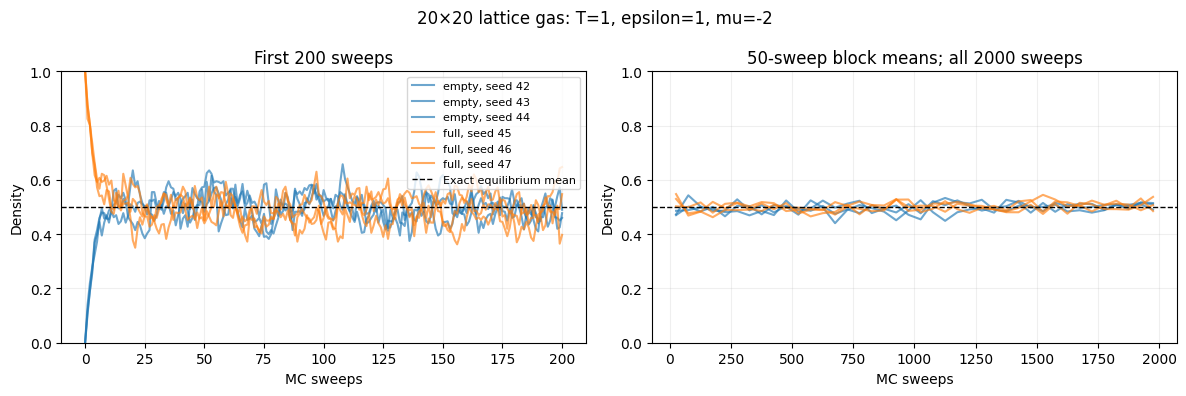

In [24]:
import matplotlib.pyplot as plt

pilot_config = {
    "L": 20,
    "temperature": 1.0,
    "epsilon": 1.0,
    "mu": -2.0,
    "sweeps": 2000,
    "seeds": {"empty": [42, 43, 44], "full": [45, 46, 47]},
}

pilot_runs = {}

for initial, seeds in pilot_config["seeds"].items():
    for seed in seeds:
        run_rng = np.random.default_rng(seed)
        n = np.full(
            (pilot_config["L"], pilot_config["L"]),
            0 if initial == "empty" else 1,
            dtype=np.int64,
        )

        sweeps = pilot_config["sweeps"]
        density = np.empty(sweeps + 1)
        h_per_site = np.empty(sweeps + 1)
        acceptance = np.empty(sweeps)

        tracked_h = lattice_energy(n, 1.0, -2.0)
        density[0] = n.mean()
        h_per_site[0] = tracked_h / n.size

        for step in range(1, sweeps + 1):
            rate, delta_h = metropolis_sweep(
                n, temperature=1.0, rng=run_rng,
                epsilon=1.0, mu=-2.0,
            )
            tracked_h += delta_h
            density[step] = n.mean()
            h_per_site[step] = tracked_h / n.size
            acceptance[step - 1] = rate

            if step % 100 == 0:
                assert np.isclose(
                    tracked_h, lattice_energy(n, 1.0, -2.0),
                    rtol=0.0, atol=1e-10,
                )

        pilot_runs[(initial, seed)] = {
            "density": density,
            "H_per_site": h_per_site,
            "acceptance": acceptance,
            "final_state": n.copy(),
        }
        print(
            f"{initial:5s}, seed={seed} | "
            f"final density={density[-1]:.4f} | "
            f"mean acceptance={acceptance.mean():.3f}"
        )

# Show early relaxation and later fluctuations separately.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
colors = {"empty": "tab:blue", "full": "tab:orange"}

for (initial, seed), run in pilot_runs.items():
    rho = run["density"]
    label = f"{initial}, seed {seed}"

    axes[0].plot(
        np.arange(201), rho[:201],
        color=colors[initial], alpha=0.65, label=label,
    )

    block_size = 50
    block_means = rho[1:].reshape(-1, block_size).mean(axis=1)
    block_centers = (
        np.arange(len(block_means)) * block_size
        + (block_size + 1) / 2
    )
    axes[1].plot(
        block_centers, block_means,
        color=colors[initial], alpha=0.65,
    )

for ax in axes:
    ax.axhline(
        0.5, color="black", linestyle="--",
        linewidth=1, label="Exact equilibrium mean",
    )
    ax.set(xlabel="MC sweeps", ylabel="Density", ylim=(0, 1))
    ax.grid(alpha=0.2)

axes[0].set_title("First 200 sweeps")
axes[1].set_title("50-sweep block means; all 2000 sweeps")
axes[0].legend(fontsize=8)
fig.suptitle("20×20 lattice gas: T=1, epsilon=1, mu=-2")
fig.tight_layout()
plt.show()

Density means under different initial exclusions:
Initial | Seed | discard 100 | discard 200 | discard 500
empty   |   42 | 0.493926 | 0.494022 | 0.494325
empty   |   43 | 0.499576 | 0.499825 | 0.502608
empty   |   44 | 0.497359 | 0.497554 | 0.497305
full    |   45 | 0.501517 | 0.501549 | 0.502085
full    |   46 | 0.501868 | 0.502078 | 0.500887
full    |   47 | 0.499105 | 0.500554 | 0.501088

Exploratory estimates after discarding 200 sweeps:
empty, seed=42 | rho=0.494022 | rho SEM(B=50/100)=0.003533/0.003272 | H/site=0.361315
empty, seed=43 | rho=0.499825 | rho SEM(B=50/100)=0.003183/0.003374 | H/site=0.360504
empty, seed=44 | rho=0.497554 | rho SEM(B=50/100)=0.002369/0.002138 | H/site=0.360456
full , seed=45 | rho=0.501549 | rho SEM(B=50/100)=0.002653/0.002954 | H/site=0.361219
full , seed=46 | rho=0.502078 | rho SEM(B=50/100)=0.002864/0.003322 | H/site=0.361310
full , seed=47 | rho=0.500554 | rho SEM(B=50/100)=0.002622/0.002407 | H/site=0.360676


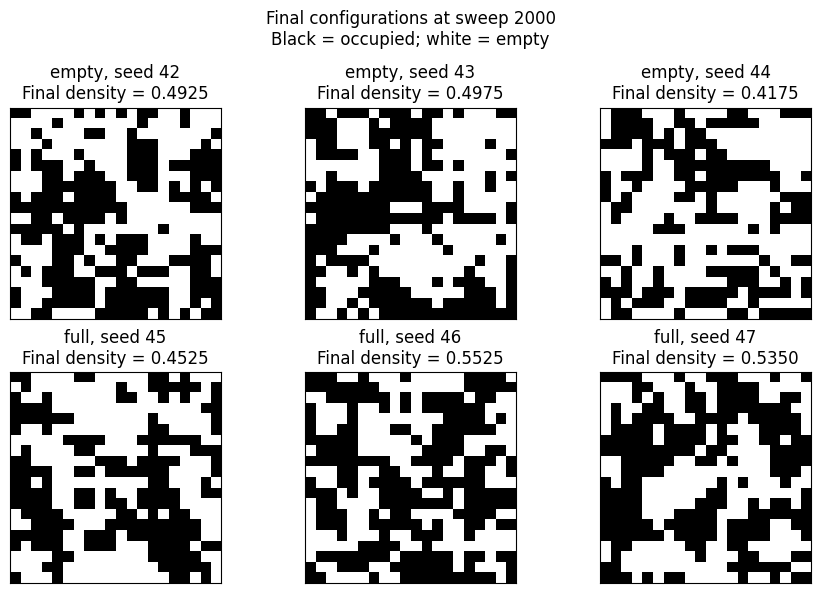

In [25]:
# Exploratory summaries of the existing pilot trajectories.
# Discard sweeps 1–200; retain sweeps 201–2000.
discard = 200

print("Density means under different initial exclusions:")
print("Initial | Seed | discard 100 | discard 200 | discard 500")

for (initial, seed), run in pilot_runs.items():
    means = [
        run["density"][cut + 1:].mean()
        for cut in (100, 200, 500)
    ]
    print(
        f"{initial:7s} | {seed:4d} | "
        + " | ".join(f"{value:.6f}" for value in means)
    )

print("\nExploratory estimates after discarding 200 sweeps:")
for (initial, seed), run in pilot_runs.items():
    rho = run["density"][discard + 1:]
    h = run["H_per_site"][discard + 1:]

    print(
        f"{initial:5s}, seed={seed} | "
        f"rho={rho.mean():.6f} | "
        f"rho SEM(B=50/100)="
        f"{block_mean_sem(rho, 50):.6f}/"
        f"{block_mean_sem(rho, 100):.6f} | "
        f"H/site={h.mean():.6f}"
    )

# Display every final configuration, without selecting favorable examples.
fig, axes = plt.subplots(2, 3, figsize=(9, 6))

for ax, ((initial, seed), run) in zip(axes.flat, pilot_runs.items()):
    state = run["final_state"]
    ax.imshow(
        state, cmap="binary", vmin=0, vmax=1,
        interpolation="nearest",
    )
    ax.set_title(
        f"{initial}, seed {seed}\n"
        f"Final density = {state.mean():.4f}"
    )
    ax.set_xticks([])
    ax.set_yticks([])

fig.suptitle(
    "Final configurations at sweep 2000\n"
    "Black = occupied; white = empty"
)
fig.tight_layout()
plt.show()

In [26]:
# Nearest-neighbor occupancy relative to a random arrangement
# with the same instantaneous particle number.
# Uses existing trajectories only.

M = pilot_config["L"] ** 2
eps = pilot_config["epsilon"]
chem_mu = pilot_config["mu"]
discard = 200

print("Nearest-neighbor occupancy after discarding 200 sweeps:")
print("Initial | Seed | Observed | Random reference | Excess +/- block SEM")

for (initial, seed), run in pilot_runs.items():
    rho = run["density"][discard + 1:]
    h = run["H_per_site"][discard + 1:]

    # H/M = -2 * epsilon * bond_fraction - mu * rho.
    bond_fraction = (-h - chem_mu * rho) / (2 * eps)

    particle_number = np.rint(M * rho).astype(np.int64)
    random_reference = (
        particle_number * (particle_number - 1)
        / (M * (M - 1))
    )

    excess = bond_fraction - random_reference
    sem = block_mean_sem(excess, 100)

    print(
        f"{initial:7s} | {seed:4d} | "
        f"{bond_fraction.mean():.6f} | "
        f"{random_reference.mean():.6f} | "
        f"{excess.mean():+.6f} +/- {sem:.6f}"
    )

Nearest-neighbor occupancy after discarding 200 sweeps:
Initial | Seed | Observed | Random reference | Excess +/- block SEM
empty   |   42 | 0.313365 | 0.246102 | +0.067263 +/- 0.000304
empty   |   43 | 0.319573 | 0.251934 | +0.067639 +/- 0.000267
empty   |   44 | 0.317326 | 0.249548 | +0.067778 +/- 0.000336
full    |   45 | 0.320939 | 0.253576 | +0.067363 +/- 0.000391
full    |   46 | 0.321423 | 0.253810 | +0.067613 +/- 0.000259
full    |   47 | 0.320216 | 0.252501 | +0.067715 +/- 0.000362


empty, seed=142 | final density=0.0100 | mean acceptance=0.0193
empty, seed=143 | final density=0.0100 | mean acceptance=0.0201
empty, seed=144 | final density=0.0150 | mean acceptance=0.0198
full , seed=145 | final density=1.0000 | mean acceptance=0.0205
full , seed=146 | final density=0.9950 | mean acceptance=0.0202
full , seed=147 | final density=0.9950 | mean acceptance=0.0204


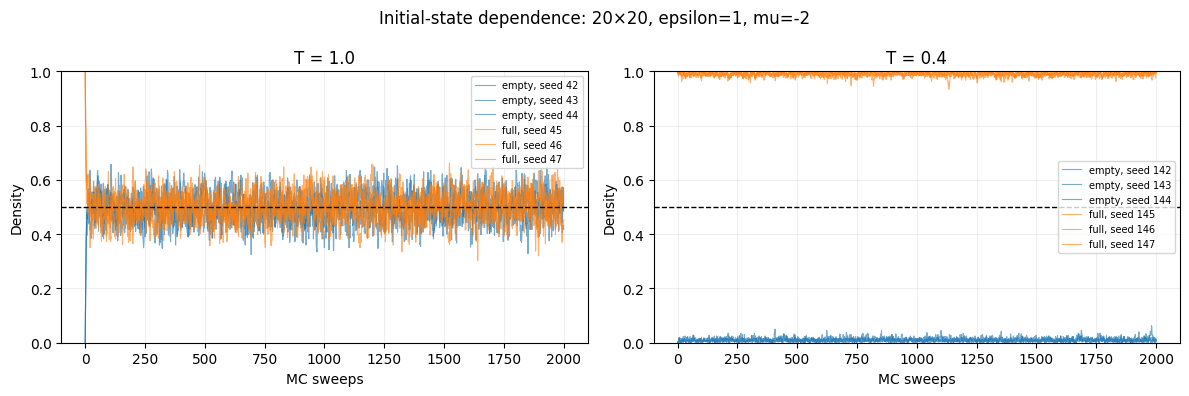

In [27]:
cold_config = {
    "L": 20,
    "temperature": 0.4,
    "epsilon": 1.0,
    "mu": -2.0,
    "sweeps": 2000,
    "seeds": {"empty": [142, 143, 144], "full": [145, 146, 147]},
}

cold_runs = {}

for initial, seeds in cold_config["seeds"].items():
    for seed in seeds:
        run_rng = np.random.default_rng(seed)
        n = np.full(
            (cold_config["L"], cold_config["L"]),
            0 if initial == "empty" else 1,
            dtype=np.int64,
        )

        sweeps = cold_config["sweeps"]
        density = np.empty(sweeps + 1)
        h_per_site = np.empty(sweeps + 1)
        acceptance = np.empty(sweeps)

        eps = cold_config["epsilon"]
        chem_mu = cold_config["mu"]
        tracked_h = lattice_energy(n, eps, chem_mu)
        density[0] = n.mean()
        h_per_site[0] = tracked_h / n.size

        for step in range(1, sweeps + 1):
            rate, delta_h = metropolis_sweep(
                n, temperature=cold_config["temperature"],
                rng=run_rng, epsilon=eps, mu=chem_mu,
            )
            tracked_h += delta_h
            density[step] = n.mean()
            h_per_site[step] = tracked_h / n.size
            acceptance[step - 1] = rate

            if step % 100 == 0:
                assert np.isclose(
                    tracked_h, lattice_energy(n, eps, chem_mu),
                    rtol=0.0, atol=1e-10,
                )

        cold_runs[(initial, seed)] = {
            "density": density,
            "H_per_site": h_per_site,
            "acceptance": acceptance,
            "final_state": n.copy(),
        }
        print(
            f"{initial:5s}, seed={seed} | "
            f"final density={density[-1]:.4f} | "
            f"mean acceptance={acceptance.mean():.4f}"
        )

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, runs, temp in zip(
    axes, (pilot_runs, cold_runs), (1.0, 0.4)
):
    for (initial, seed), run in runs.items():
        ax.plot(
            np.arange(len(run["density"])),
            run["density"],
            color="tab:blue" if initial == "empty" else "tab:orange",
            alpha=0.6,
            linewidth=0.8,
            label=f"{initial}, seed {seed}",
        )

    ax.axhline(0.5, color="black", linestyle="--", linewidth=1)
    ax.set(
        title=f"T = {temp}",
        xlabel="MC sweeps", ylabel="Density", ylim=(0, 1),
    )
    ax.legend(fontsize=7)
    ax.grid(alpha=0.2)

fig.suptitle("Initial-state dependence: 20×20, epsilon=1, mu=-2")
fig.tight_layout()
plt.show()

In [28]:
from pathlib import Path
from datetime import datetime
import json
import platform

save_dir = (
    Path.cwd()
    / "results"
    / datetime.now().strftime("lattice_gas_pilot_%Y%m%d_%H%M%S_%f")
)
save_dir.mkdir(parents=True, exist_ok=False)

metadata = {
    "model": "H = -epsilon * occupied_bonds - mu * N",
    "boundary": "periodic",
    "update": "random-site Metropolis insertion/deletion",
    "sweep": "L**2 attempts with replacement",
    "python_version": platform.python_version(),
    "numpy_version": np.__version__,
    "warm_config": pilot_config,
    "cold_config": cold_config,
    "status": "Exploratory trajectories; low-temperature mixing not established",
}

(save_dir / "config.json").write_text(
    json.dumps(metadata, indent=2), encoding="utf-8"
)

for label, runs in (("warm", pilot_runs), ("cold", cold_runs)):
    for (initial, seed), run in runs.items():
        np.savez_compressed(
            save_dir / f"{label}_{initial}_seed_{seed}.npz",
            **run,
        )

for (test_mu, seed), run in validation_runs.items():
    np.savez_compressed(
        save_dir / f"validation_3x3_mu_{test_mu:+.1f}_seed_{seed}.npz",
        **run,
    )

print("Saved configurations and trajectory arrays to:")
print(save_dir.resolve())

Saved configurations and trajectory arrays to:
C:\Users\user\Documents\GitHub\active-matter-reproductions\lattice-gas\results\lattice_gas_pilot_20261103_203848_210645


In [29]:
import json
from pathlib import Path
from datetime import datetime

half_config = {
    "L": 20,
    "temperature": 0.4,
    "epsilon": 1.0,
    "mu": -2.0,
    "sweeps": 2000,
    "seeds": [242, 243, 244],
    "initial_particles": 200,
    "snapshot_sweeps": [0, 10, 50, 200, 1000, 2000],
}

# Create a separate output directory without overwriting earlier results.
half_dir = (
    Path.cwd()
    / "results"
    / datetime.now().strftime("random_half_%Y%m%d_%H%M%S_%f")
)
half_dir.mkdir(parents=True, exist_ok=False)

(half_dir / "config.json").write_text(
    json.dumps(half_config, indent=2),
    encoding="utf-8",
)

half_runs = {}

for seed in half_config["seeds"]:
    run_rng = np.random.default_rng(seed)
    size = half_config["L"]
    sweeps = half_config["sweeps"]
    eps = half_config["epsilon"]
    chem_mu = half_config["mu"]

    # Exactly half occupied initially; particle number may change afterward.
    flat = np.zeros(size * size, dtype=np.int64)
    flat[:half_config["initial_particles"]] = 1
    run_rng.shuffle(flat)
    n = flat.reshape(size, size)

    density = np.empty(sweeps + 1)
    h_per_site = np.empty(sweeps + 1)
    acceptance = np.empty(sweeps)
    snapshots = [n.copy()]

    tracked_h = lattice_energy(n, eps, chem_mu)
    density[0] = n.mean()
    h_per_site[0] = tracked_h / n.size

    assert density[0] == 0.5

    for step in range(1, sweeps + 1):
        rate, delta_h = metropolis_sweep(
            n,
            temperature=half_config["temperature"],
            rng=run_rng,
            epsilon=eps,
            mu=chem_mu,
        )
        tracked_h += delta_h

        density[step] = n.mean()
        h_per_site[step] = tracked_h / n.size
        acceptance[step - 1] = rate

        if step % 100 == 0:
            assert np.isclose(
                tracked_h,
                lattice_energy(n, eps, chem_mu),
                rtol=0,
                atol=1e-10,
            )

        if step in half_config["snapshot_sweeps"]:
            snapshots.append(n.copy())

    half_runs[seed] = {
        "density": density,
        "H_per_site": h_per_site,
        "acceptance": acceptance,
        "snapshot_sweeps": np.array(half_config["snapshot_sweeps"]),
        "snapshots": np.stack(snapshots),
        "final_state": n.copy(),
    }

    np.savez_compressed(
        half_dir / f"random_half_seed_{seed}.npz",
        **half_runs[seed],
    )

    print(
        f"seed={seed} | "
        f"initial density={density[0]:.4f} | "
        f"final density={density[-1]:.4f} | "
        f"mean acceptance={acceptance.mean():.4f}"
    )

print("Saved to:", half_dir.resolve())

seed=242 | initial density=0.5000 | final density=0.0175 | mean acceptance=0.0238
seed=243 | initial density=0.5000 | final density=0.9775 | mean acceptance=0.0371
seed=244 | initial density=0.5000 | final density=0.9975 | mean acceptance=0.0228
Saved to: C:\Users\user\Documents\GitHub\active-matter-reproductions\lattice-gas\results\random_half_20261103_203848_327240


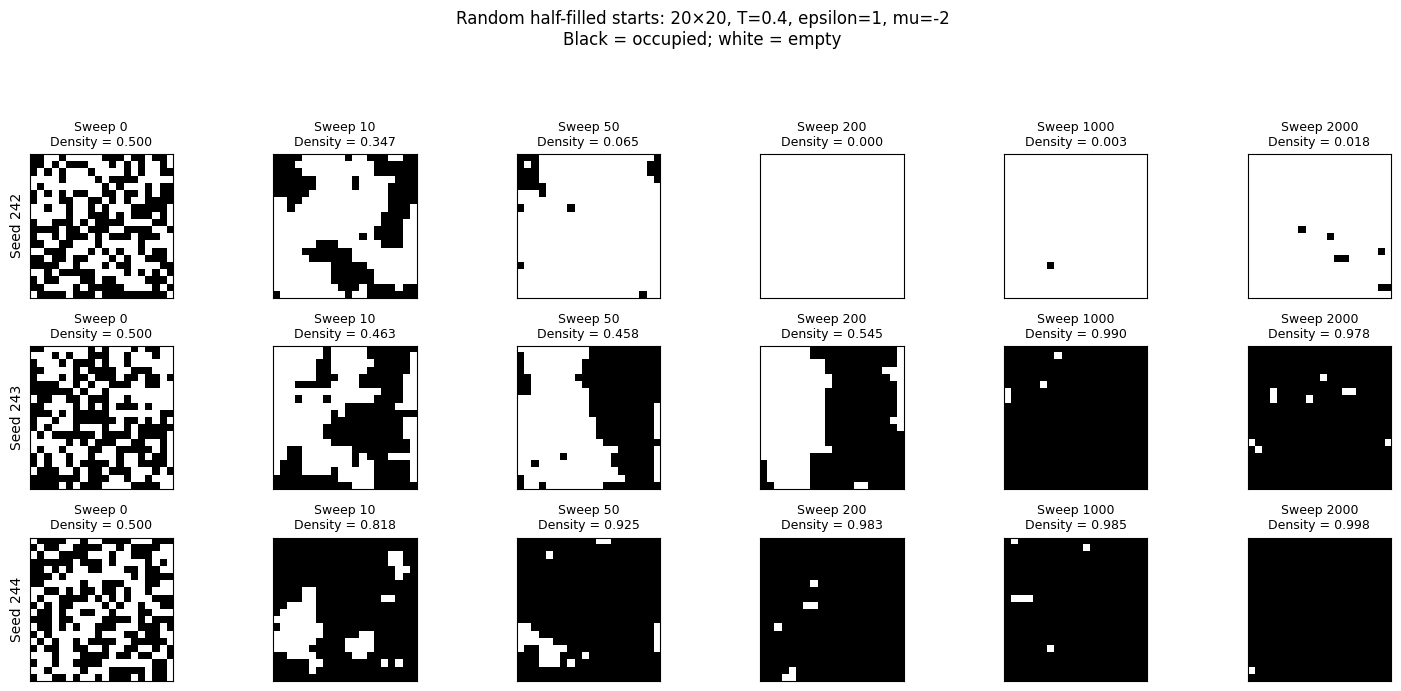

In [30]:
fig, axes = plt.subplots(
    len(half_runs),
    len(half_config["snapshot_sweeps"]),
    figsize=(15, 7),
    squeeze=False,
)

for row, (seed, run) in enumerate(half_runs.items()):
    for col, (step, state) in enumerate(
        zip(run["snapshot_sweeps"], run["snapshots"])
    ):
        ax = axes[row, col]
        ax.imshow(
            state,
            cmap="binary",
            vmin=0,
            vmax=1,
            interpolation="nearest",
        )
        ax.set_title(
            f"Sweep {step}\nDensity = {state.mean():.3f}",
            fontsize=9,
        )
        ax.set_xticks([])
        ax.set_yticks([])

        if col == 0:
            ax.set_ylabel(f"Seed {seed}", fontsize=10)

fig.suptitle(
    "Random half-filled starts: 20×20, T=0.4, epsilon=1, mu=-2\n"
    "Black = occupied; white = empty",
    fontsize=12,
)
fig.tight_layout(rect=(0, 0, 1, 0.92))
fig.savefig(half_dir / "configuration_evolution.png", dpi=180)
plt.show()

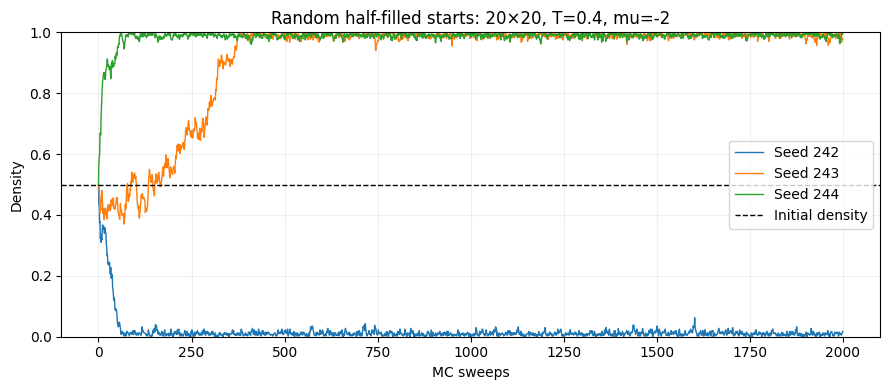

In [31]:
fig, ax = plt.subplots(figsize=(9, 4))

for seed, run in half_runs.items():
    ax.plot(
        np.arange(len(run["density"])),
        run["density"],
        label=f"Seed {seed}",
        linewidth=1,
    )

ax.axhline(
    0.5, color="black", linestyle="--",
    linewidth=1, label="Initial density",
)
ax.set(
    title="Random half-filled starts: 20×20, T=0.4, mu=-2",
    xlabel="MC sweeps",
    ylabel="Density",
    ylim=(0, 1),
)
ax.legend()
ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(half_dir / "density_traces.png", dpi=180)
plt.show()

In [32]:
def swap_energy_change(n, i, j, axis, epsilon=1.0):
    """Energy change for swapping with the next site along axis 0 or 1."""
    rows, cols = n.shape
    if min(rows, cols) < 3:
        raise ValueError("Both lattice dimensions must be >= 3.")
    if axis not in (0, 1):
        raise ValueError("axis must be 0 or 1.")

    # Periodic neighbor: down for axis 0, right for axis 1.
    k = (i + 1) % rows if axis == 0 else i
    l = j if axis == 0 else (j + 1) % cols

    a = int(n[i, j])
    b = int(n[k, l])

    if a == b:
        return 0.0

    def neighbor_sum(r, c):
        return (
            int(n[(r - 1) % rows, c])
            + int(n[(r + 1) % rows, c])
            + int(n[r, (c - 1) % cols])
            + int(n[r, (c + 1) % cols])
        )

    # Exclude the bond between the two exchanged sites.
    neighbors_a = neighbor_sum(i, j) - b
    neighbors_b = neighbor_sum(k, l) - a

    return float(epsilon * (a - b) * (neighbors_a - neighbors_b))


# Validate on one random configuration at each size.
swap_check_rng = np.random.default_rng(342)

for check_size in (3, 20):
    check_state = swap_check_rng.integers(
        0, 2, size=(check_size, check_size), dtype=np.int64
    )
    check_epsilon = 1.0
    check_mu = -2.0
    energy_before = lattice_energy(
        check_state, check_epsilon, check_mu
    )
    particle_count = int(check_state.sum())
    errors = []

    # Down/right edges enumerate every undirected nearest-neighbor bond once.
    for i in range(check_size):
        for j in range(check_size):
            for axis in (0, 1):
                k = (i + 1) % check_size if axis == 0 else i
                l = j if axis == 0 else (j + 1) % check_size

                local_delta = swap_energy_change(
                    check_state, i, j, axis, check_epsilon
                )

                changed = check_state.copy()
                changed[i, j], changed[k, l] = (
                    int(check_state[k, l]),
                    int(check_state[i, j]),
                )

                full_delta = (
                    lattice_energy(changed, check_epsilon, check_mu)
                    - energy_before
                )

                assert int(changed.sum()) == particle_count
                errors.append(abs(local_delta - full_delta))

    assert np.allclose(errors, 0.0, rtol=0.0, atol=1e-12)

    print(
        f"PASS: {check_size}x{check_size}, "
        f"{len(errors)} swaps checked | "
        f"maximum energy-change error = {max(errors):.3e}"
    )

PASS: 3x3, 18 swaps checked | maximum energy-change error = 0.000e+00
PASS: 20x20, 800 swaps checked | maximum energy-change error = 0.000e+00


In [33]:
def kawasaki_sweep(n, temperature, rng, epsilon=1.0):
    """Attempt n.size nearest-neighbor exchanges; modify n in place."""
    if not np.isfinite(temperature) or temperature <= 0:
        raise ValueError("Temperature must be finite and positive.")

    rows, cols = n.shape
    if min(rows, cols) < 3:
        raise ValueError("Both lattice dimensions must be >= 3.")

    moved = 0
    total_delta = 0.0

    for _ in range(n.size):
        i = int(rng.integers(rows))
        j = int(rng.integers(cols))
        axis = int(rng.integers(2))

        k = (i + 1) % rows if axis == 0 else i
        l = j if axis == 0 else (j + 1) % cols

        # Equal occupations produce no change, but count as an attempt.
        if n[i, j] == n[k, l]:
            continue

        delta_h = swap_energy_change(n, i, j, axis, epsilon)

        if delta_h <= 0 or rng.random() < np.exp(-delta_h / temperature):
            a = int(n[i, j])
            b = int(n[k, l])
            n[i, j], n[k, l] = b, a

            moved += 1
            total_delta += delta_h

    # Fraction of all attempts that changed the configuration.
    return moved / n.size, total_delta


# Short implementation check, not an equilibrium measurement.
kawasaki_check_rng = np.random.default_rng(343)

check_flat = np.zeros(400, dtype=np.int64)
check_flat[:200] = 1
kawasaki_check_rng.shuffle(check_flat)
kawasaki_state = check_flat.reshape(20, 20)

# mu=0 gives the interaction energy U; fixed-N exchange needs no mu term.
tracked_u = lattice_energy(kawasaki_state, epsilon=1.0, mu=0.0)

for sweep in range(1, 21):
    move_fraction, delta_u = kawasaki_sweep(
        kawasaki_state,
        temperature=0.4,
        rng=kawasaki_check_rng,
        epsilon=1.0,
    )
    tracked_u += delta_u

    direct_u = lattice_energy(kawasaki_state, epsilon=1.0, mu=0.0)

    assert int(kawasaki_state.sum()) == 200
    assert np.isin(kawasaki_state, [0, 1]).all()
    assert np.isclose(tracked_u, direct_u, rtol=0.0, atol=1e-10)

    if sweep in (1, 5, 10, 20):
        print(
            f"Sweep {sweep:2d} | "
            f"N={kawasaki_state.sum()} | "
            f"density={kawasaki_state.mean():.4f} | "
            f"move fraction={move_fraction:.3f} | "
            f"U={direct_u:.1f}"
        )

print("PASS: particle conservation, binary occupations, and energy bookkeeping.")

Sweep  1 | N=200 | density=0.5000 | move fraction=0.217 | U=-238.0
Sweep  5 | N=200 | density=0.5000 | move fraction=0.080 | U=-258.0
Sweep 10 | N=200 | density=0.5000 | move fraction=0.105 | U=-267.0
Sweep 20 | N=200 | density=0.5000 | move fraction=0.058 | U=-284.0
PASS: particle conservation, binary occupations, and energy bookkeeping.


Initial state: density=0.500, U=-196, boundary bonds=408
After 20 sweeps: density=0.500, U=-284, boundary bonds=232


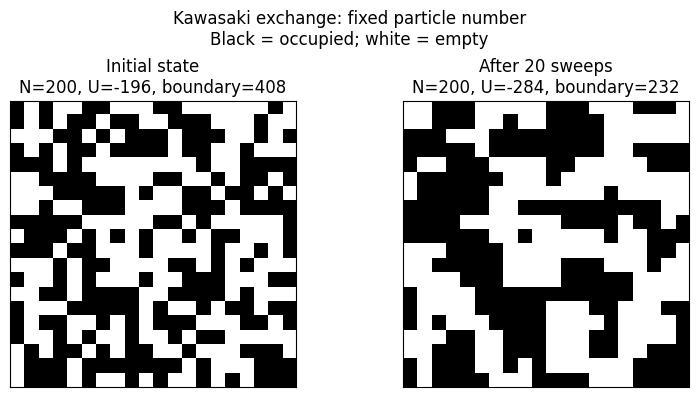

PASS: direct boundary counts match the energy identity.


In [34]:
import matplotlib.pyplot as plt

def count_boundary_bonds(n):
    """Count occupied-empty nearest-neighbor bonds once each."""
    return int(
        np.count_nonzero(n != np.roll(n, -1, axis=0))
        + np.count_nonzero(n != np.roll(n, -1, axis=1))
    )


# Reconstruct the exact initial state used in the 20-sweep check.
initial_rng = np.random.default_rng(343)
initial_flat = np.zeros(400, dtype=np.int64)
initial_flat[:200] = 1
initial_rng.shuffle(initial_flat)
initial_state = initial_flat.reshape(20, 20)

# Copy the existing result without changing it.
final_state = kawasaki_state.copy()

fig, axes = plt.subplots(1, 2, figsize=(8, 4))

for ax, title, state in zip(
    axes,
    ("Initial state", "After 20 sweeps"),
    (initial_state, final_state),
):
    particle_count = int(state.sum())
    energy = lattice_energy(state, epsilon=1.0, mu=0.0)
    boundary = count_boundary_bonds(state)

    # Independent geometric count versus the energy identity.
    assert particle_count == 200
    assert np.isclose(
        boundary, 4 * particle_count + 2 * energy,
        rtol=0.0, atol=1e-12,
    )

    ax.imshow(
        state, cmap="binary", vmin=0, vmax=1,
        interpolation="nearest",
    )
    ax.set_title(
        f"{title}\n"
        f"N={particle_count}, U={energy:.0f}, boundary={boundary}"
    )
    ax.set_xticks([])
    ax.set_yticks([])

    print(
        f"{title}: density={state.mean():.3f}, "
        f"U={energy:.0f}, boundary bonds={boundary}"
    )

fig.suptitle(
    "Kawasaki exchange: fixed particle number\n"
    "Black = occupied; white = empty"
)
fig.tight_layout()
plt.show()

print("PASS: direct boundary counts match the energy identity.")

Sweep   20 | N=200 | U=-284 | boundary=232
Sweep  100 | N=200 | U=-312 | boundary=176
Sweep  500 | N=200 | U=-328 | boundary=144
Sweep 1000 | N=200 | U=-330 | boundary=140
Sweep 2000 | N=200 | U=-359 | boundary=82


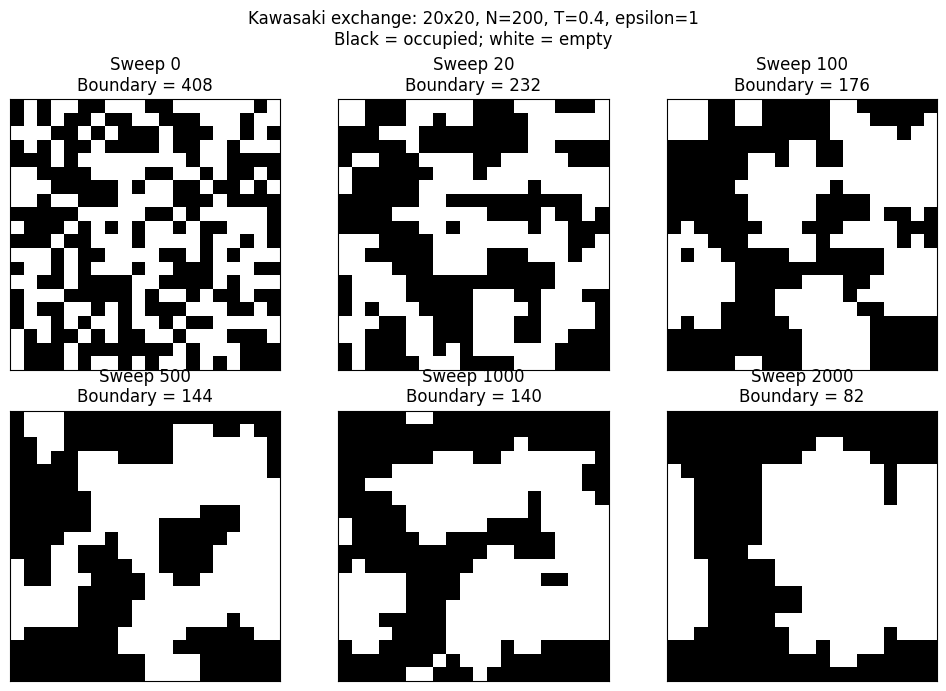

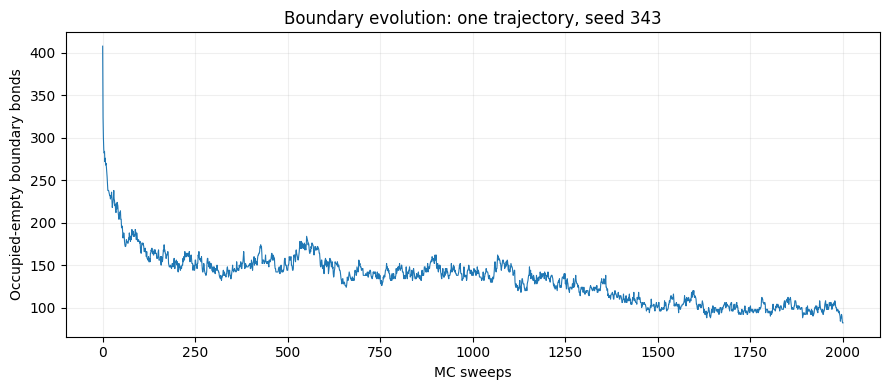

PASS: particle conservation and energy identities.
Saved to: C:\Users\user\Documents\GitHub\active-matter-reproductions\lattice-gas\results\kawasaki_20261103_203858_306027


In [35]:
from pathlib import Path
from datetime import datetime
import json
import platform
import numpy as np
import matplotlib.pyplot as plt

# Fixed settings for this finite-time observation.
kawasaki_config = {
    "L": 20,
    "N": 200,
    "temperature": 0.4,
    "epsilon": 1.0,
    "seed": 343,
    "sweeps": 2000,
    "snapshot_sweeps": [0, 20, 100, 500, 1000, 2000],
    "boundary": "periodic",
    "update": "uniform nearest-neighbor bond proposal; Metropolis exchange",
    "sweep_definition": "L**2 attempts, including equal-occupation proposals",
    "status": "Single finite-time trajectory; equilibrium not established",
    "python_version": platform.python_version(),
    "numpy_version": np.__version__,
}

cfg = kawasaki_config
kawasaki_rng = np.random.default_rng(cfg["seed"])

flat = np.zeros(cfg["L"] ** 2, dtype=np.int64)
flat[:cfg["N"]] = 1
kawasaki_rng.shuffle(flat)
exchange_state = flat.reshape(cfg["L"], cfg["L"])

steps = np.arange(cfg["sweeps"] + 1)
particle_counts = np.empty(len(steps), dtype=np.int64)
boundary_counts = np.empty(len(steps), dtype=np.int64)
energies = np.empty(len(steps))
move_fractions = np.empty(cfg["sweeps"])
snapshots = [exchange_state.copy()]

particle_counts[0] = exchange_state.sum()
boundary_counts[0] = count_boundary_bonds(exchange_state)
energies[0] = lattice_energy(exchange_state, cfg["epsilon"], mu=0.0)

for sweep in range(1, cfg["sweeps"] + 1):
    move_fraction, delta_u = kawasaki_sweep(
        exchange_state,
        temperature=cfg["temperature"],
        rng=kawasaki_rng,
        epsilon=cfg["epsilon"],
    )

    energies[sweep] = energies[sweep - 1] + delta_u
    particle_counts[sweep] = exchange_state.sum()
    boundary_counts[sweep] = count_boundary_bonds(exchange_state)
    move_fractions[sweep - 1] = move_fraction

    assert particle_counts[sweep] == cfg["N"]
    assert np.isin(exchange_state, [0, 1]).all()
    assert np.isclose(
        boundary_counts[sweep],
        4 * cfg["N"] + 2 * energies[sweep] / cfg["epsilon"],
        rtol=0.0, atol=1e-10,
    )

    if sweep % 100 == 0:
        direct_u = lattice_energy(exchange_state, cfg["epsilon"], mu=0.0)
        assert np.isclose(
            energies[sweep], direct_u, rtol=0.0, atol=1e-10
        )

    if sweep == 20:
        assert energies[sweep] == -284.0
        assert boundary_counts[sweep] == 232

    if sweep in cfg["snapshot_sweeps"]:
        snapshots.append(exchange_state.copy())
        print(
            f"Sweep {sweep:4d} | N={particle_counts[sweep]} | "
            f"U={energies[sweep]:.0f} | "
            f"boundary={boundary_counts[sweep]}"
        )

# Save results in a new directory on each execution.
kawasaki_dir = (
    Path.cwd() / "results"
    / datetime.now().strftime("kawasaki_%Y%m%d_%H%M%S_%f")
)
kawasaki_dir.mkdir(parents=True, exist_ok=False)

(kawasaki_dir / "config.json").write_text(
    json.dumps(cfg, indent=2), encoding="utf-8"
)
(kawasaki_dir / "final_rng_state.json").write_text(
    json.dumps(kawasaki_rng.bit_generator.state, indent=2),
    encoding="utf-8",
)
np.savez_compressed(
    kawasaki_dir / "trajectory.npz",
    sweeps=steps,
    particle_count=particle_counts,
    U=energies,
    boundary_count=boundary_counts,
    move_fraction=move_fractions,
    snapshot_sweeps=np.array(cfg["snapshot_sweeps"]),
    snapshots=np.stack(snapshots),
    final_state=exchange_state,
)

# Show the saved configurations.
fig, axes = plt.subplots(2, 3, figsize=(10, 7))
for ax, sweep, state in zip(
    axes.flat, cfg["snapshot_sweeps"], snapshots
):
    ax.imshow(
        state, cmap="binary", vmin=0, vmax=1,
        interpolation="nearest",
    )
    ax.set_title(
        f"Sweep {sweep}\nBoundary = {boundary_counts[sweep]}"
    )
    ax.set_xticks([])
    ax.set_yticks([])

fig.suptitle(
    "Kawasaki exchange: 20x20, N=200, T=0.4, epsilon=1\n"
    "Black = occupied; white = empty"
)
fig.tight_layout()
fig.savefig(kawasaki_dir / "snapshots.png", dpi=180)
plt.show()

# Boundary count and energy are equivalent observables at fixed N.
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(steps, boundary_counts, linewidth=0.8)
ax.set(
    xlabel="MC sweeps",
    ylabel="Occupied-empty boundary bonds",
    title="Boundary evolution: one trajectory, seed 343",
)
ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(kawasaki_dir / "boundary_trace.png", dpi=180)
plt.show()

print("PASS: particle conservation and energy identities.")
print("Saved to:", kawasaki_dir.resolve())

### Fixed-N Kawasaki exchange: finite-time observation

A 20×20 periodic lattice with N=200 particles was simulated at
T=0.4 and epsilon=1 using nearest-neighbor Metropolis exchanges.
One sweep consists of 400 bond proposals, including no-change proposals.

For seed 343, the occupied-empty boundary count decreased from
408 initially to 82 at sweep 2000. The interaction energy changed
from -196 to -359, while the density remained exactly 0.5.

Particle conservation and energy bookkeeping checks passed.
Snapshots show increasingly extended occupied and empty regions.

This single trajectory demonstrates finite-time structural evolution.
Equilibration, stationary coexistence, and seed robustness have not
been established. A temporary plateau in one observable is not
sufficient evidence of equilibrium.

## Kawasaki exchange: initial-state sensitivity

In [36]:
from pathlib import Path
from datetime import datetime
import json
import platform
import time
import numpy as np

comparison_config = {
    "L": 20,
    "N": 200,
    "temperature": 0.4,
    "epsilon": 1.0,
    "sweeps": 10000,
    "record_every": 10,
    "snapshot_sweeps": [0, 100, 1000, 5000, 7500, 10000],
    "seeds": {
        "random": [442, 443, 444],
        "stripe": [445, 446, 447],
    },
    "analysis_windows": [[5001, 7500], [7501, 10000]],
    "diagnostic_block_lengths_sweeps": [250, 500],
    "boundary": "periodic",
    "sweep_definition": "L**2 uniform bond proposals, including no-change moves",
    "status": "Initial-state sensitivity diagnostic; equilibrium not established",
    "python_version": platform.python_version(),
    "numpy_version": np.__version__,
}

comparison_dir = (
    Path.cwd() / "results"
    / datetime.now().strftime("kawasaki_initial_states_%Y%m%d_%H%M%S_%f")
)
comparison_dir.mkdir(parents=True, exist_ok=False)

(comparison_dir / "config.json").write_text(
    json.dumps(comparison_config, indent=2), encoding="utf-8"
)


def lowest_mode_structure(n):
    """Mean S(k)=|FFT(n-rho)|^2/M over the four smallest axial modes."""
    fluctuation = n.astype(float) - n.mean()
    spectrum = np.abs(np.fft.fft2(fluctuation)) ** 2 / n.size
    return float(
        (
            spectrum[1, 0] + spectrum[-1, 0]
            + spectrum[0, 1] + spectrum[0, -1]
        ) / 4
    )


comparison_runs = {}
comparison_start = time.perf_counter()
cc = comparison_config

for initial, seeds in cc["seeds"].items():
    for seed in seeds:
        run_rng = np.random.default_rng(seed)

        if initial == "random":
            flat = np.zeros(cc["L"] ** 2, dtype=np.int64)
            flat[:cc["N"]] = 1
            run_rng.shuffle(flat)
            state = flat.reshape(cc["L"], cc["L"])
        else:
            state = np.zeros((cc["L"], cc["L"]), dtype=np.int64)
            state[:, :cc["L"] // 2] = 1

        assert int(state.sum()) == cc["N"]

        record_sweeps = np.arange(
            0, cc["sweeps"] + 1, cc["record_every"]
        )
        boundary = np.empty(len(record_sweeps), dtype=np.int64)
        energy = np.empty(len(record_sweeps))
        s_low = np.empty(len(record_sweeps))
        moves = np.empty(cc["sweeps"])
        saved_snapshots = [state.copy()]

        tracked_u = lattice_energy(state, cc["epsilon"], mu=0.0)
        boundary[0] = count_boundary_bonds(state)
        energy[0] = tracked_u
        s_low[0] = lowest_mode_structure(state)

        for sweep in range(1, cc["sweeps"] + 1):
            moved, delta_u = kawasaki_sweep(
                state,
                temperature=cc["temperature"],
                rng=run_rng,
                epsilon=cc["epsilon"],
            )
            tracked_u += delta_u
            moves[sweep - 1] = moved

            assert int(state.sum()) == cc["N"]

            if sweep % cc["record_every"] == 0:
                index = sweep // cc["record_every"]
                boundary[index] = count_boundary_bonds(state)
                energy[index] = tracked_u
                s_low[index] = lowest_mode_structure(state)

                direct_u = lattice_energy(state, cc["epsilon"], mu=0.0)
                assert np.isin(state, [0, 1]).all()
                assert np.isclose(
                    tracked_u, direct_u, rtol=0.0, atol=1e-10
                )
                assert np.isclose(
                    boundary[index],
                    4 * cc["N"] + 2 * tracked_u / cc["epsilon"],
                    rtol=0.0, atol=1e-10,
                )

            if sweep in cc["snapshot_sweeps"]:
                saved_snapshots.append(state.copy())

            if sweep % 2500 == 0:
                print(
                    f"{initial:6s}, seed={seed} | "
                    f"{sweep:5d}/{cc['sweeps']} sweeps | "
                    f"boundary={count_boundary_bonds(state)}",
                    flush=True,
                )

        run = {
            "record_sweeps": record_sweeps,
            "boundary": boundary,
            "U": energy,
            "S_low": s_low,
            "move_fraction": moves,
            "snapshot_sweeps": np.array(cc["snapshot_sweeps"]),
            "snapshots": np.stack(saved_snapshots),
            "final_state": state.copy(),
        }
        comparison_runs[(initial, seed)] = run

        # Save each completed run immediately.
        np.savez_compressed(
            comparison_dir / f"{initial}_seed_{seed}.npz", **run
        )
        (comparison_dir / f"{initial}_seed_{seed}_rng.json").write_text(
            json.dumps(run_rng.bit_generator.state, indent=2),
            encoding="utf-8",
        )

elapsed = time.perf_counter() - comparison_start

print(f"\nFinished: {len(comparison_runs)} trajectories in {elapsed:.1f} s.")
print("PASS: particle conservation and energy bookkeeping.")
print("Equilibrium assessment is pending.")
print("Saved to:", comparison_dir.resolve())

random, seed=442 |  2500/10000 sweeps | boundary=100
random, seed=442 |  5000/10000 sweeps | boundary=80
random, seed=442 |  7500/10000 sweeps | boundary=88
random, seed=442 | 10000/10000 sweeps | boundary=84
random, seed=443 |  2500/10000 sweeps | boundary=108
random, seed=443 |  5000/10000 sweeps | boundary=104
random, seed=443 |  7500/10000 sweeps | boundary=112
random, seed=443 | 10000/10000 sweeps | boundary=80
random, seed=444 |  2500/10000 sweeps | boundary=102
random, seed=444 |  5000/10000 sweeps | boundary=78
random, seed=444 |  7500/10000 sweeps | boundary=76
random, seed=444 | 10000/10000 sweeps | boundary=78
stripe, seed=445 |  2500/10000 sweeps | boundary=84
stripe, seed=445 |  5000/10000 sweeps | boundary=68
stripe, seed=445 |  7500/10000 sweeps | boundary=80
stripe, seed=445 | 10000/10000 sweeps | boundary=78
stripe, seed=446 |  2500/10000 sweeps | boundary=70
stripe, seed=446 |  5000/10000 sweeps | boundary=82
stripe, seed=446 |  7500/10000 sweeps | boundary=62
stripe,

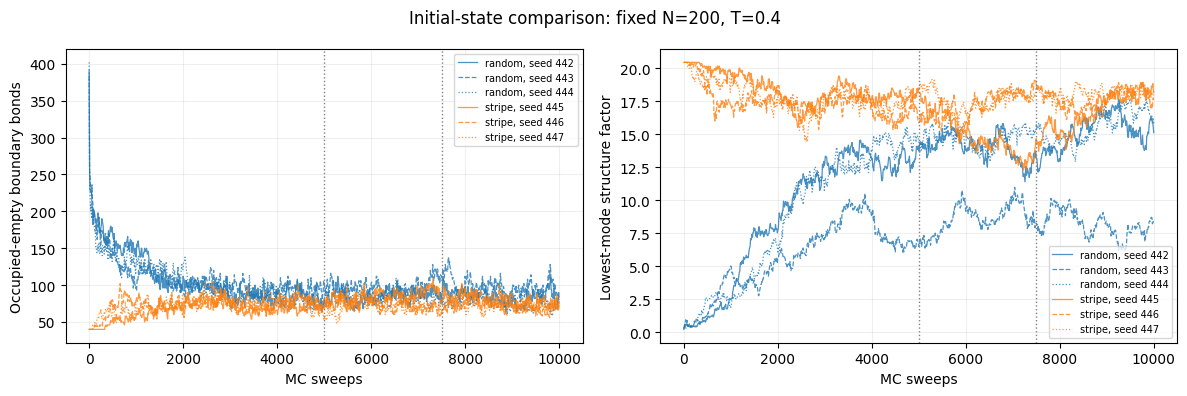

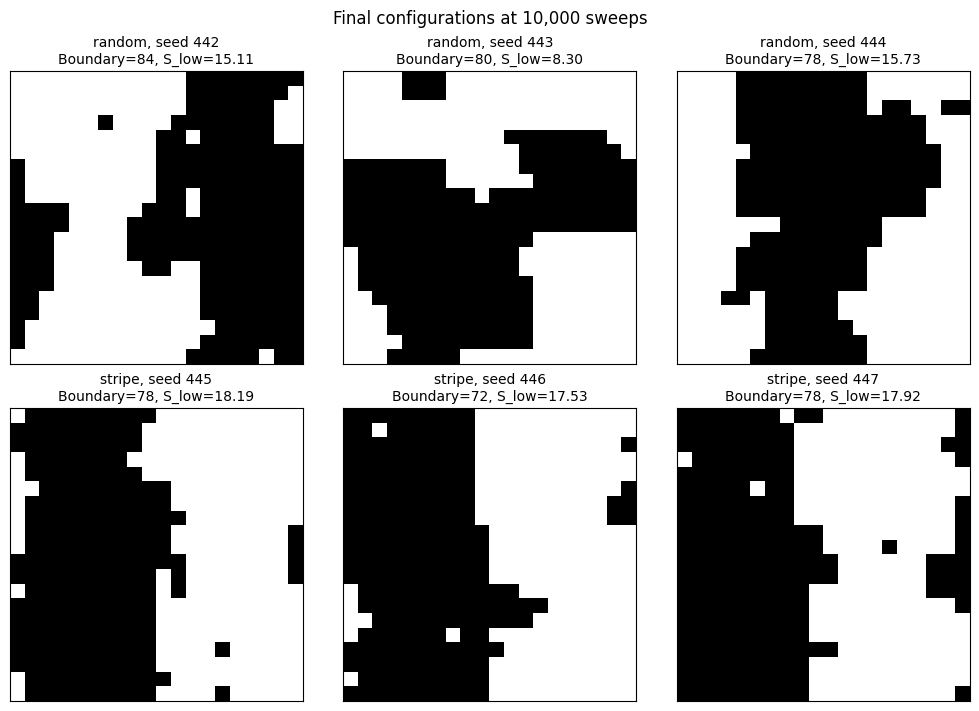

random 442 | boundary |  5001- 7500 | mean=85.024 | SEM(250/500)=1.701/1.936
random 442 | boundary |  7501-10000 | mean=84.600 | SEM(250/500)=1.980/2.610
random 442 | S_low    |  5001- 7500 | mean=14.030 | SEM(250/500)=0.251/0.364
random 442 | S_low    |  7501-10000 | mean=15.139 | SEM(250/500)=0.376/0.540
random 443 | boundary |  5001- 7500 | mean=97.120 | SEM(250/500)=2.077/2.304
random 443 | boundary |  7501-10000 | mean=98.328 | SEM(250/500)=2.636/1.947
random 443 | S_low    |  5001- 7500 | mean=8.606 | SEM(250/500)=0.333/0.398
random 443 | S_low    |  7501-10000 | mean=8.178 | SEM(250/500)=0.277/0.332
random 444 | boundary |  5001- 7500 | mean=83.328 | SEM(250/500)=1.217/1.413
random 444 | boundary |  7501-10000 | mean=78.040 | SEM(250/500)=1.544/1.125
random 444 | S_low    |  5001- 7500 | mean=14.718 | SEM(250/500)=0.176/0.235
random 444 | S_low    |  7501-10000 | mean=15.583 | SEM(250/500)=0.359/0.476
stripe 445 | boundary |  5001- 7500 | mean=84.104 | SEM(250/500)=1.897/2.546
s

In [37]:
import matplotlib.pyplot as plt
import numpy as np
import json

colors = {"random": "tab:blue", "stripe": "tab:orange"}
styles = ["-", "--", ":"]

# 1. Compare the complete trajectories.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for initial, seeds in comparison_config["seeds"].items():
    for style, seed in zip(styles, seeds):
        run = comparison_runs[(initial, seed)]
        for ax, key in zip(axes, ("boundary", "S_low")):
            ax.plot(
                run["record_sweeps"], run[key],
                color=colors[initial], linestyle=style,
                linewidth=0.9, alpha=0.8,
                label=f"{initial}, seed {seed}",
            )

for ax, ylabel in zip(
    axes, ("Occupied-empty boundary bonds", "Lowest-mode structure factor")
):
    ax.axvline(5000, color="gray", linestyle=":", linewidth=1)
    ax.axvline(7500, color="gray", linestyle=":", linewidth=1)
    ax.set(xlabel="MC sweeps", ylabel=ylabel)
    ax.grid(alpha=0.2)
    ax.legend(fontsize=7)

fig.suptitle("Initial-state comparison: fixed N=200, T=0.4")
fig.tight_layout()
fig.savefig(comparison_dir / "observable_comparison.png", dpi=180)
plt.show()

# 2. Inspect all six final configurations.
fig, axes = plt.subplots(2, 3, figsize=(10, 7), layout="constrained")

for row, (initial, seeds) in enumerate(
    comparison_config["seeds"].items()
):
    for col, seed in enumerate(seeds):
        run = comparison_runs[(initial, seed)]
        ax = axes[row, col]
        ax.imshow(
            run["final_state"], cmap="binary",
            vmin=0, vmax=1, interpolation="nearest",
        )
        ax.set_title(
            f"{initial}, seed {seed}\n"
            f"Boundary={run['boundary'][-1]}, "
            f"S_low={run['S_low'][-1]:.2f}",
            fontsize=10,
        )
        ax.set_xticks([])
        ax.set_yticks([])

fig.suptitle("Final configurations at 10,000 sweeps")
fig.savefig(comparison_dir / "final_configurations.png", dpi=180)
plt.show()

# 3. Use the predefined windows and block lengths.
def diagnostic_block_sem(values, block_points):
    """SEM from non-overlapping block means; not a convergence test."""
    values = np.asarray(values, dtype=float)
    assert len(values) % block_points == 0
    means = values.reshape(-1, block_points).mean(axis=1)
    assert len(means) >= 2
    return float(means.std(ddof=1) / np.sqrt(len(means)))


window_summary = []
spacing = comparison_config["record_every"]

for (initial, seed), run in comparison_runs.items():
    for key in ("boundary", "S_low"):
        for start, end in comparison_config["analysis_windows"]:
            mask = (
                (run["record_sweeps"] >= start)
                & (run["record_sweeps"] <= end)
            )
            values = run[key][mask]
            row = {
                "initial": initial,
                "seed": seed,
                "observable": key,
                "window": [start, end],
                "recorded_points": int(len(values)),
                "mean": float(values.mean()),
            }

            for block_sweeps in comparison_config[
                "diagnostic_block_lengths_sweeps"
            ]:
                assert block_sweeps % spacing == 0
                row[f"sem_block_{block_sweeps}"] = diagnostic_block_sem(
                    values, block_sweeps // spacing
                )

            window_summary.append(row)
            print(
                f"{initial:6s} {seed} | {key:8s} | "
                f"{start:5d}-{end:5d} | mean={row['mean']:.3f} | "
                f"SEM(250/500)="
                f"{row['sem_block_250']:.3f}/"
                f"{row['sem_block_500']:.3f}"
            )

(comparison_dir / "window_summary.json").write_text(
    json.dumps(window_summary, indent=2), encoding="utf-8"
)

print("\nAnalysis saved to:", comparison_dir.resolve())
print("Block SEM estimates do not establish equilibrium.")

## Kawasaki Exchange: Initial-State Sensitivity

### Question and setup

Within a fixed computational budget, do random and stripe initial
configurations produce compatible structural statistics?

- Model: attractive square-lattice gas with periodic boundaries.
- Parameters: L = 20, N = 200, density = 0.5, T = 0.4, epsilon = 1.
- Dynamics: nearest-neighbor Kawasaki exchange with Metropolis acceptance.
- One sweep: L² random bond proposals, including rejected and no-change moves.
- Initial conditions:
  - Random: seeds 442, 443, 444.
  - Stripe: seeds 445, 446, 447.
- Budget: 10,000 sweeps per trajectory; six trajectories in total.
- Analysis windows: sweeps 5001–7500 and 7501–10000.
- Observables: occupied–empty boundary bonds and the structure factor
  averaged over the four lowest nonzero axial wavevectors, S_low.

### Implementation checks

All six trajectories completed. Particle-number conservation and
energy bookkeeping checks passed during execution.

At fixed particle number,

$$
U = -2\epsilon N + \frac{\epsilon}{2}B_{\mathrm{boundary}}.
$$

Energy and boundary count therefore contain equivalent information
and are not independent structural checks. S_low provides complementary
information about structure on the scale of the simulation box.

### Results

Time averages over sweeps 7501–10000:

| Initial condition | Seed | Mean boundary | Mean S_low |
|---|---:|---:|---:|
| Random | 442 | 84.600 | 15.139 |
| Random | 443 | 98.328 | 8.178 |
| Random | 444 | 78.040 | 15.583 |
| Stripe | 445 | 77.608 | 16.712 |
| Stripe | 446 | 73.392 | 17.671 |
| Stripe | 447 | 73.008 | 18.015 |

Boundary-count ranges overlap across trajectories, but differences
remain in their time averages and large-scale structural statistics.
In particular, random seed 443 has a lower mean S_low than the other
trajectories in the final analysis window.

Some trajectories also show changes between the two analysis windows.
For stripe seed 445, the mean boundary count decreases from 84.104 to
77.608, while mean S_low increases from 14.919 to 16.712.

### Interpretation and limitations

This experiment completes a fixed-budget initial-state sensitivity
diagnostic. It demonstrates that apparently similar boundary counts
or energies can coexist with differences in large-scale structure.

The available evidence is insufficient to treat the six trajectories
as a validated equilibrium reference. It does not prove that every
trajectory is out of equilibrium, that stripe configurations are the
correct equilibrium morphology, or that seed 443 is erroneous.

Block SEM estimates describe uncertainty within the sampled trajectories.
They do not rule out slow structural evolution, insufficient exploration
of configuration space, or persistent initial-state effects. Each window
contains only ten 250-sweep blocks or five 500-sweep blocks.

No numerical convergence acceptance threshold was specified in advance.
These results are therefore interpreted as diagnostic evidence rather
than a formal convergence PASS or FAIL.

### Decision and preserved outputs

The experiment ends at the planned budget of 10,000 sweeps per trajectory.
All seeds are retained.

The results are preserved as finite-time structural evolution data and
sampling-consistency diagnostics. An equilibrium reference and phase
boundaries have not been established.

Saved outputs include:

- Simulation parameters.
- Observable trajectories and configuration snapshots.
- Final configurations and final random-number-generator states.
- Observable comparison and final-configuration figures.
- Window statistics in `window_summary.json`.

## Exact Canonical Reference for Kawasaki Validation

### Objective

Construct an exact equilibrium reference for a small fixed-particle-number
lattice gas. This reference will subsequently be used to validate the
Kawasaki transition rule and assess Monte Carlo sampling.

### Fixed setup

- Square lattice: L = 4, with periodic boundaries.
- Particle number: N = 8; density = 0.5.
- Temperature: T = 0.4, with k_B = 1.
- Interaction strength: epsilon = 1.
- Number of allowed configurations: C(16, 8) = 12,870.
- Absolute tolerance for deterministic consistency checks: 1e-12.

The canonical probability of configuration n is

$$
\pi(n)=\frac{\exp[-U(n)/T]}{Z_N},
\qquad
Z_N=\sum_{n:\,\sum_i n_i=N}\exp[-U(n)/T],
$$

where

$$
U(n)=-\epsilon\sum_{\langle i,j\rangle}n_i n_j.
$$

Each undirected nearest-neighbor bond is counted once.
The chemical-potential term is constant at fixed N and cancels
from the normalized probabilities.

### Exact reference and checks

Enumerate all allowed configurations and calculate their probabilities,
together with the equilibrium means and standard deviations of:

- Interaction energy U.
- Occupied–empty boundary count.
- Lowest-mode structure factor S_low, using the same definition
  as in the 20×20 experiment.

Check particle number, probability normalization, agreement between
two energy implementations, and the identity

$$
4N = 2B_{11}+B_{\mathrm{boundary}}.
$$

### Scope

This cell performs deterministic enumeration, not Monte Carlo sampling.
The reported equilibrium standard deviations describe fluctuations
across configurations; they are not standard errors of estimated means.

Passing these checks establishes internal consistency of the reference.
Validation of the Kawasaki transition rule and finite-run sampling
is a separate subsequent step.

Results for this small system do not establish equilibration of
the 20×20 system.

In [38]:
from itertools import combinations
from math import comb
import numpy as np

# Fixed canonical reference: no Monte Carlo sampling in this cell.
exact_config = {
    "L": 4,
    "N": 8,
    "temperature": 0.4,
    "epsilon": 1.0,
    "atol": 1e-12,
}

ref_L = exact_config["L"]
ref_M = ref_L**2
ref_N = exact_config["N"]
ref_T = exact_config["temperature"]
ref_eps = exact_config["epsilon"]
ref_tol = exact_config["atol"]

# Enumerate every configuration with exactly N occupied sites.
occupied_sets = np.array(
    list(combinations(range(ref_M), ref_N)), dtype=np.int64
)
states_flat = np.zeros((len(occupied_sets), ref_M), dtype=np.int8)
states_flat[np.arange(len(occupied_sets))[:, None], occupied_sets] = 1
states_4x4 = states_flat.reshape(-1, ref_L, ref_L)

assert len(states_4x4) == comb(ref_M, ref_N) == 12870
assert np.all(states_flat.sum(axis=1) == ref_N)

# Explicit edge list: count each undirected periodic bond once.
# This provides an alternative to the np.roll energy implementation.
edges = []
for i in range(ref_L):
    for j in range(ref_L):
        site = i * ref_L + j
        edges.append((site, ((i + 1) % ref_L) * ref_L + j))
        edges.append((site, i * ref_L + (j + 1) % ref_L))

edges = np.asarray(edges, dtype=np.int64)
left = states_flat[:, edges[:, 0]]
right = states_flat[:, edges[:, 1]]

occupied_bonds = (left * right).sum(axis=1)
boundary = (left != right).sum(axis=1)
energy = -ref_eps * occupied_bonds

# Compare against the existing energy function for every state.
existing_energy = np.array([
    lattice_energy(state, epsilon=ref_eps, mu=0.0)
    for state in states_4x4
])
max_energy_error = float(np.max(np.abs(energy - existing_energy)))
assert max_energy_error < ref_tol
assert np.all(4 * ref_N == 2 * occupied_bonds + boundary)

# Exact normalized canonical probabilities.
log_weights = -energy / ref_T
weights = np.exp(log_weights - log_weights.max())
probabilities = weights / weights.sum()
assert abs(probabilities.sum() - 1.0) < ref_tol

# Match the S_low definition used in the 20x20 experiment.
fluctuations = states_4x4.astype(float) - ref_N / ref_M
spectrum = np.abs(
    np.fft.fft2(fluctuations, axes=(-2, -1))
)**2 / ref_M

s_low = (
    spectrum[:, 1, 0] + spectrum[:, -1, 0]
    + spectrum[:, 0, 1] + spectrum[:, 0, -1]
) / 4.0

exact_canonical_4x4 = {
    "config": exact_config.copy(),
    "states": states_4x4,
    "probabilities": probabilities,
    "U": energy,
    "boundary": boundary,
    "S_low": s_low,
}

print(f"Enumerated states: {len(states_4x4)}")
print(f"Probability sum: {probabilities.sum():.15f}")
print(f"Maximum energy disagreement: {max_energy_error:.3e}")

for name in ("U", "boundary", "S_low"):
    values = exact_canonical_4x4[name]
    mean = float(probabilities @ values)
    variance = float(probabilities @ ((values - mean)**2))
    print(
        f"{name:8s} | exact mean={mean:.8f} "
        f"| equilibrium SD={np.sqrt(variance):.8f}"
    )

print("PASS: enumeration, energy consistency, and normalization.")
print("Kawasaki transition-rule and sampling validation are still pending.")

Enumerated states: 12870
Probability sum: 1.000000000000000
Maximum energy disagreement: 0.000e+00
U        | exact mean=-11.02873992 | equilibrium SD=1.14454662
boundary | exact mean=9.94252015 | equilibrium SD=2.28909323
S_low    | exact mean=0.82445154 | equilibrium SD=0.21263678
PASS: enumeration, energy consistency, and normalization.
Kawasaki transition-rule and sampling validation are still pending.


In [39]:
# Exhaustive checks of the single-attempt Kawasaki transition rule.
# Uses all states and probabilities from the exact reference above.

reference = exact_canonical_4x4
check_states = reference["states"]
check_energy = reference["U"]
check_pi = reference["probabilities"]
check_L = reference["config"]["L"]
check_T = reference["config"]["temperature"]
check_eps = reference["config"]["epsilon"]
check_tol = reference["config"]["atol"]

n_states = len(check_states)
n_bonds = 2 * check_L**2
proposal_probability = 1.0 / n_bonds

state_index = {
    state.tobytes(): index
    for index, state in enumerate(check_states)
}

# Each column represents one uniformly proposed undirected bond.
targets = np.empty((n_states, n_bonds), dtype=np.int64)
acceptance = np.empty((n_states, n_bonds), dtype=float)
max_delta_error = 0.0

for a, state in enumerate(check_states):
    edge_id = 0

    for i in range(check_L):
        for j in range(check_L):
            for axis in (0, 1):
                k = (i + 1) % check_L if axis == 0 else i
                l = j if axis == 0 else (j + 1) % check_L

                changed = state.copy()
                changed[i, j] = state[k, l]
                changed[k, l] = state[i, j]
                b = state_index[changed.tobytes()]

                delta_local = swap_energy_change(
                    state, i, j, axis, check_eps
                )
                delta_exact = check_energy[b] - check_energy[a]

                max_delta_error = max(
                    max_delta_error,
                    abs(delta_local - delta_exact),
                )

                targets[a, edge_id] = b
                acceptance[a, edge_id] = np.exp(
                    -max(delta_local, 0.0) / check_T
                )
                edge_id += 1

assert max_delta_error < check_tol
assert np.all((acceptance >= 0.0) & (acceptance <= 1.0))

# Applying the same swap twice must return to the original state.
source_indices = np.arange(n_states)
max_balance_relative_error = 0.0

for edge_id in range(n_bonds):
    destination = targets[:, edge_id]
    assert np.array_equal(
        targets[destination, edge_id], source_indices
    )

    forward_flux = (
        check_pi * proposal_probability * acceptance[:, edge_id]
    )
    reverse_flux = (
        check_pi[destination]
        * proposal_probability
        * acceptance[destination, edge_id]
    )

    relative_error = np.abs(forward_flux - reverse_flux) / (
        forward_flux + reverse_flux
    )
    max_balance_relative_error = max(
        max_balance_relative_error,
        float(relative_error.max()),
    )

# Rejections leave the state unchanged.
# Equal-occupation swaps also leave it unchanged and are included.
rejection_probability = (
    proposal_probability * (1.0 - acceptance).sum(axis=1)
)
row_sums = (
    proposal_probability * acceptance.sum(axis=1)
    + rejection_probability
)
max_row_error = float(np.max(np.abs(row_sums - 1.0)))

# Compute pi @ P without constructing a dense transition matrix.
pi_after = check_pi * rejection_probability

for edge_id in range(n_bonds):
    np.add.at(
        pi_after,
        targets[:, edge_id],
        check_pi * proposal_probability * acceptance[:, edge_id],
    )

stationarity_l1_error = float(np.abs(pi_after - check_pi).sum())

assert max_row_error < check_tol
assert max_balance_relative_error < check_tol
assert stationarity_l1_error < check_tol

kawasaki_kernel_checks = {
    "states": n_states,
    "bond_proposals_checked": n_states * n_bonds,
    "max_delta_error": float(max_delta_error),
    "max_row_error": max_row_error,
    "max_detailed_balance_relative_error": max_balance_relative_error,
    "stationarity_l1_error": stationarity_l1_error,
    "tolerance": check_tol,
}

for name, value in kawasaki_kernel_checks.items():
    print(f"{name}: {value}")

print("PASS: exhaustive single-attempt transition-rule checks.")
print("Finite-run sampling validation is still pending.")

states: 12870
bond_proposals_checked: 411840
max_delta_error: 0.0
max_row_error: 2.220446049250313e-16
max_detailed_balance_relative_error: 8.94833115719821e-17
stationarity_l1_error: 2.3177474514325966e-16
tolerance: 1e-12
PASS: exhaustive single-attempt transition-rule checks.
Finite-run sampling validation is still pending.


### Finite-Run Kawasaki Sampling Check

Question: How accurately does the implemented Kawasaki sampler recover
the exact 4×4 canonical statistics within a fixed sampling budget?

Fixed protocol:

- L = 4, N = 8, T = 0.4, epsilon = 1.
- Random initial states: seeds 542, 543, 544.
- Stripe initial states: seeds 545, 546, 547.
- Initial exclusion: 2,000 sweeps.
- Measurement: 20,000 additional sweeps, recording every sweep.
- Block lengths for SEM diagnostics: 500 and 1,000 sweeps.
- Compare the two equal halves of the measurement window.
- Preserve all trajectories, including rejected/no-change updates.

The initial exclusion is a protocol choice, not proof of equilibration.
Report deviations from exact means, block SEM estimates, and observable
distributions. This is a diagnostic comparison without a formal
statistical PASS threshold.

Stop after the prescribed budget. Do not replace seeds or extend runs
based on their observed agreement with the reference.

In [40]:
from pathlib import Path
from datetime import datetime
import json
import platform
import time
import numpy as np

canonical_sampling_config = {
    "L": 4,
    "N": 8,
    "temperature": 0.4,
    "epsilon": 1.0,
    "initial_exclusion": 2000,
    "measurement_sweeps": 20000,
    "seeds": {
        "random": [542, 543, 544],
        "stripe": [545, 546, 547],
    },
    "sem_block_lengths": [500, 1000],
    "measurement_windows": [[2001, 12000], [12001, 22000]],
    "sweep_definition": "L**2 uniform bond proposals with replacement",
    "python_version": platform.python_version(),
    "numpy_version": np.__version__,
    "status": "Fixed-budget sampling diagnostic; assessment pending",
}

canonical_sampling_dir = (
    Path.cwd()
    / "results"
    / datetime.now().strftime("canonical_4x4_%Y%m%d_%H%M%S_%f")
)
canonical_sampling_dir.mkdir(parents=True, exist_ok=False)

(canonical_sampling_dir / "config.json").write_text(
    json.dumps(canonical_sampling_config, indent=2),
    encoding="utf-8",
)
(canonical_sampling_dir / "kernel_checks.json").write_text(
    json.dumps(kawasaki_kernel_checks, indent=2),
    encoding="utf-8",
)

ref = exact_canonical_4x4
assert all(
    canonical_sampling_config[key] == ref["config"][key]
    for key in ("L", "N", "temperature", "epsilon")
)

np.savez_compressed(
    canonical_sampling_dir / "exact_reference.npz",
    states=ref["states"],
    probabilities=ref["probabilities"],
    U=ref["U"],
    boundary=ref["boundary"],
    S_low=ref["S_low"],
)

# Lookup maps an observed configuration to its exact observables.
# It does not choose configurations or modify the sampling dynamics.
canonical_state_index = {
    state.astype(np.int8).tobytes(): index
    for index, state in enumerate(ref["states"])
}

def canonical_block_sem(values, block_size):
    values = np.asarray(values, dtype=float)
    assert len(values) % block_size == 0
    blocks = values.reshape(-1, block_size).mean(axis=1)
    assert len(blocks) >= 2
    return float(blocks.std(ddof=1) / np.sqrt(len(blocks)))

cfg = canonical_sampling_config
burn = cfg["initial_exclusion"]
total_sweeps = burn + cfg["measurement_sweeps"]
canonical_sampling_runs = {}
canonical_sampling_summary = []
sampling_started = time.perf_counter()

for initial, seeds in cfg["seeds"].items():
    for seed in seeds:
        run_rng = np.random.default_rng(seed)

        state = np.zeros((cfg["L"], cfg["L"]), dtype=np.int8)
        if initial == "random":
            state.flat[:cfg["N"]] = 1
            run_rng.shuffle(state.reshape(-1))
        else:
            state[:, :cfg["L"] // 2] = 1

        initial_state = state.copy()
        state_ids = np.empty(total_sweeps + 1, dtype=np.int64)
        moves = np.empty(total_sweeps, dtype=float)

        state_ids[0] = canonical_state_index[state.tobytes()]
        tracked_u = lattice_energy(
            state, epsilon=cfg["epsilon"], mu=0.0
        )

        for sweep in range(1, total_sweeps + 1):
            move_fraction, delta_u = kawasaki_sweep(
                state,
                temperature=cfg["temperature"],
                rng=run_rng,
                epsilon=cfg["epsilon"],
            )
            tracked_u += delta_u
            moves[sweep - 1] = move_fraction

            assert int(state.sum()) == cfg["N"]
            assert np.isin(state, [0, 1]).all()

            idx = canonical_state_index[state.tobytes()]
            state_ids[sweep] = idx
            assert np.isclose(
                tracked_u, ref["U"][idx], rtol=0.0, atol=1e-12
            )

        run = {
            "sweeps": np.arange(total_sweeps + 1),
            "state_index": state_ids,
            "U": ref["U"][state_ids],
            "boundary": ref["boundary"][state_ids],
            "S_low": ref["S_low"][state_ids],
            "move_fraction": moves,
            "initial_state": initial_state,
            "final_state": state.copy(),
        }
        canonical_sampling_runs[(initial, seed)] = run

        # Save each completed trajectory immediately.
        prefix = f"{initial}_seed_{seed}"
        np.savez_compressed(
            canonical_sampling_dir / f"{prefix}.npz", **run
        )
        (canonical_sampling_dir / f"{prefix}_rng.json").write_text(
            json.dumps(run_rng.bit_generator.state, indent=2),
            encoding="utf-8",
        )

        print(f"\n{initial}, seed={seed}")

        for observable in ("U", "boundary", "S_low"):
            # Retain sweeps 2001 through 22000, including no-change sweeps.
            values = np.asarray(run[observable][burn + 1:], dtype=float)
            assert len(values) == cfg["measurement_sweeps"]

            exact_mean = float(ref["probabilities"] @ ref[observable])
            midpoint = len(values) // 2
            row = {
                "initial": initial,
                "seed": seed,
                "observable": observable,
                "mean": float(values.mean()),
                "exact_mean": exact_mean,
                "error": float(values.mean() - exact_mean),
                "sem_500": canonical_block_sem(values, 500),
                "sem_1000": canonical_block_sem(values, 1000),
                "first_half_mean": float(values[:midpoint].mean()),
                "second_half_mean": float(values[midpoint:].mean()),
            }
            canonical_sampling_summary.append(row)

            print(
                f"{observable:8s} | mean={row['mean']:.6f} "
                f"| exact={exact_mean:.6f} "
                f"| error={row['error']:+.6f} "
                f"| SEM(500/1000)="
                f"{row['sem_500']:.6f}/{row['sem_1000']:.6f}"
            )

        (canonical_sampling_dir / "mean_summary.json").write_text(
            json.dumps(canonical_sampling_summary, indent=2),
            encoding="utf-8",
        )

elapsed = time.perf_counter() - sampling_started
print(f"\nFinished: {len(canonical_sampling_runs)} runs in {elapsed:.1f} s.")
print("PASS: particle conservation and energy bookkeeping.")
print("Sampling agreement requires assessment of the saved results.")
print("Saved to:", canonical_sampling_dir.resolve())


random, seed=542
U        | mean=-11.043900 | exact=-11.028740 | error=-0.015160 | SEM(500/1000)=0.144690/0.170967
boundary | mean=9.912200 | exact=9.942520 | error=-0.030320 | SEM(500/1000)=0.289381/0.341934
S_low    | mean=0.826547 | exact=0.824452 | error=+0.002095 | SEM(500/1000)=0.026460/0.031149

random, seed=543
U        | mean=-11.416050 | exact=-11.028740 | error=-0.387310 | SEM(500/1000)=0.105395/0.131661
boundary | mean=9.167900 | exact=9.942520 | error=-0.774620 | SEM(500/1000)=0.210789/0.263322
S_low    | mean=0.894403 | exact=0.824452 | error=+0.069952 | SEM(500/1000)=0.019213/0.024000

random, seed=544
U        | mean=-10.878300 | exact=-11.028740 | error=+0.150440 | SEM(500/1000)=0.135283/0.143143
boundary | mean=10.243400 | exact=9.942520 | error=+0.300880 | SEM(500/1000)=0.270566/0.286286
S_low    | mean=0.797881 | exact=0.824452 | error=-0.026570 | SEM(500/1000)=0.024491/0.025791

stripe, seed=545
U        | mean=-11.000000 | exact=-11.028740 | error=+0.028740 | SEM

Errors relative to exact means; half changes = second - first.
Initial seed | U error | S error | U half change | S half change
random 542 | -0.01516 | +0.00210 | -0.50620 | +0.09146
random 543 | -0.38731 | +0.06995 | +0.11970 | -0.02117
random 544 | +0.15044 | -0.02657 | -0.61520 | +0.10826
stripe 545 | +0.02874 | -0.00455 | -0.44800 | +0.07857
stripe 546 | +0.00729 | -0.00090 | +0.20470 | -0.03554
stripe 547 | -0.12801 | +0.02265 | -0.16010 | +0.02715


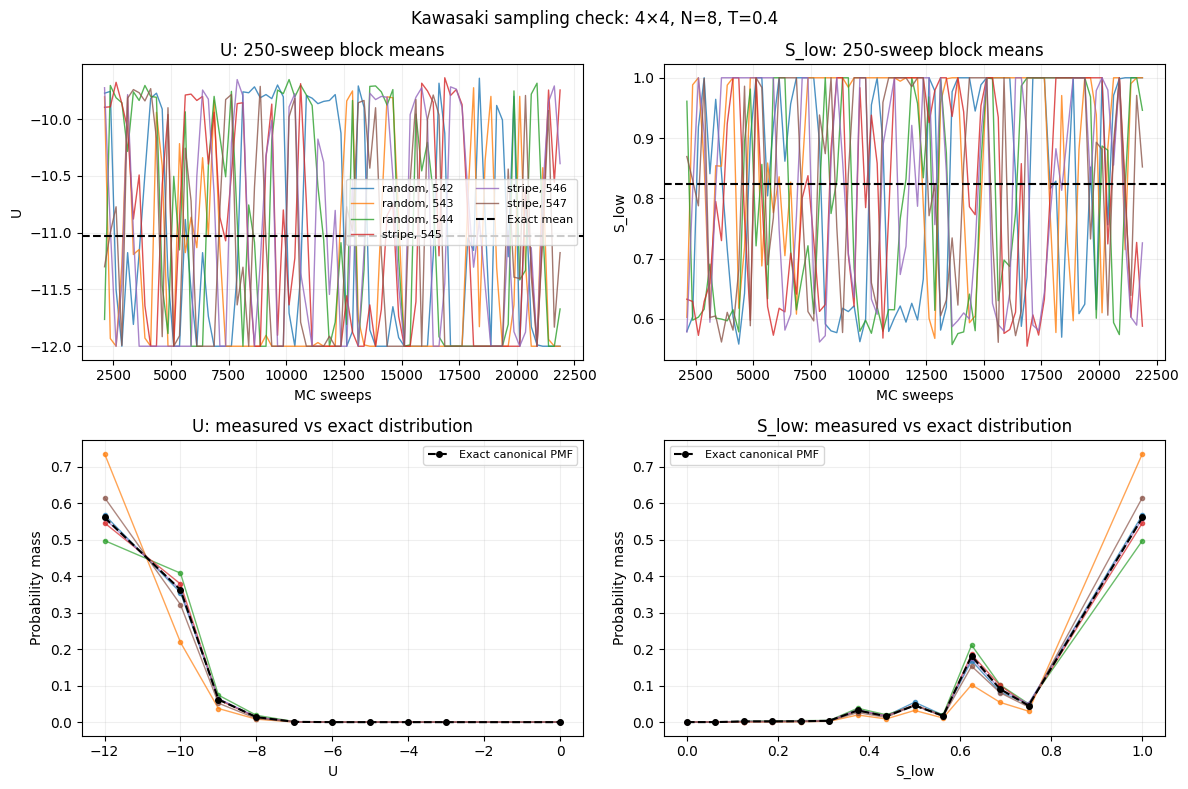


Observable PMF total variation distances (descriptive):
random 542 | U: 0.0084 | S_low: 0.0234
random 543 | U: 0.1748 | S_low: 0.1748
random 544 | U: 0.0632 | S_low: 0.0636
stripe 545 | U: 0.0163 | S_low: 0.0170
stripe 546 | U: 0.0027 | S_low: 0.0084
stripe 547 | U: 0.0547 | S_low: 0.0558

Analysis saved to: C:\Users\user\Documents\GitHub\active-matter-reproductions\lattice-gas\results\canonical_4x4_20261103_204015_003067


In [41]:
import matplotlib.pyplot as plt

# Analyze existing trajectories only.
ref = exact_canonical_4x4
burn = canonical_sampling_config["initial_exclusion"]
keys = list(canonical_sampling_runs)
colors = plt.cm.tab10(np.arange(len(keys)))

print("Errors relative to exact means; half changes = second - first.")
print("Initial seed | U error | S error | U half change | S half change")

for initial, seed in keys:
    rows = {
        row["observable"]: row
        for row in canonical_sampling_summary
        if row["initial"] == initial and row["seed"] == seed
    }
    u = rows["U"]
    s = rows["S_low"]
    print(
        f"{initial:6s} {seed} | "
        f"{u['error']:+.5f} | {s['error']:+.5f} | "
        f"{u['second_half_mean'] - u['first_half_mean']:+.5f} | "
        f"{s['second_half_mean'] - s['first_half_mean']:+.5f}"
    )

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
distribution_summary = []

for col, observable in enumerate(("U", "S_low")):
    exact_mean = float(ref["probabilities"] @ ref[observable])

    # Merge values that differ only through floating-point roundoff.
    support, state_to_bin = np.unique(
        np.round(ref[observable], 12), return_inverse=True
    )
    exact_pmf = np.bincount(
        state_to_bin,
        weights=ref["probabilities"],
        minlength=len(support),
    )

    for color, (initial, seed) in zip(colors, keys):
        run = canonical_sampling_runs[(initial, seed)]
        values = np.asarray(run[observable][burn + 1:], dtype=float)
        sweeps = run["sweeps"][burn + 1:]
        label = f"{initial}, {seed}"

        # Nonoverlapping block means for visualization.
        block_size = 250
        axes[0, col].plot(
            sweeps.reshape(-1, block_size).mean(axis=1),
            values.reshape(-1, block_size).mean(axis=1),
            color=color, linewidth=1, alpha=0.8, label=label,
        )

        sampled_ids = run["state_index"][burn + 1:]
        counts = np.bincount(
            state_to_bin[sampled_ids], minlength=len(support)
        )
        empirical_pmf = counts / counts.sum()

        axes[1, col].plot(
            support, empirical_pmf,
            ".-", color=color, linewidth=1, alpha=0.7,
        )

        # Descriptive discrepancy, not a significance test.
        tv = float(0.5 * np.abs(empirical_pmf - exact_pmf).sum())
        distribution_summary.append({
            "initial": initial,
            "seed": seed,
            "observable": observable,
            "total_variation_distance": tv,
        })

    axes[0, col].axhline(
        exact_mean, color="black", linestyle="--",
        linewidth=1.5, label="Exact mean",
    )
    axes[0, col].set(
        title=f"{observable}: 250-sweep block means",
        xlabel="MC sweeps", ylabel=observable,
    )

    axes[1, col].plot(
        support, exact_pmf, "ko--",
        linewidth=1.5, markersize=4, label="Exact canonical PMF",
    )
    axes[1, col].set(
        title=f"{observable}: measured vs exact distribution",
        xlabel=observable, ylabel="Probability mass",
    )
    axes[1, col].legend(fontsize=8)

axes[0, 0].legend(fontsize=8, ncol=2)
for ax in axes.flat:
    ax.grid(alpha=0.2)

fig.suptitle("Kawasaki sampling check: 4×4, N=8, T=0.4")
fig.tight_layout()
fig.savefig(
    canonical_sampling_dir / "sampling_vs_exact.png", dpi=180
)
plt.show()

(canonical_sampling_dir / "distribution_summary.json").write_text(
    json.dumps(distribution_summary, indent=2), encoding="utf-8"
)

print("\nObservable PMF total variation distances (descriptive):")
for initial, seed in keys:
    distances = {
        row["observable"]: row["total_variation_distance"]
        for row in distribution_summary
        if row["initial"] == initial and row["seed"] == seed
    }
    print(
        f"{initial:6s} {seed} | "
        f"U: {distances['U']:.4f} | "
        f"S_low: {distances['S_low']:.4f}"
    )

print("\nAnalysis saved to:", canonical_sampling_dir.resolve())

## Nonlocal Exchange: Candidate Equilibrium Sampler

### Purpose

Investigate a candidate sampler for constructing the 20×20 canonical
equilibrium reference. The target distribution and particle number
remain unchanged.

A proposal selects two distinct lattice sites uniformly and exchanges
their occupations. The sites need not be nearest neighbors.

The proposal is symmetric. Metropolis acceptance is therefore

$$
a(n\to n')=\min\{1,\exp[-(U(n')-U(n))/T]\}.
$$

Equal-occupation proposals leave the configuration unchanged and still
count as attempts.

### First validation step

Check the proposed local energy-difference formula against exact
enumerated energies for all 12,870 configurations and all 120 unordered
site pairs of the 4×4, N=8 system.

- Total checks: 1,544,400.
- Absolute tolerance: 1e-12.
- No Monte Carlo trajectories are generated in this step.
- Stop and investigate any discrepancy before implementing sampling.

Passing this check establishes energy-difference consistency only.
Sampling correctness and efficiency require subsequent assessment.

Nonlocal updates are an equilibrium sampling tool; their trajectories
are not interpreted as nearest-neighbor Kawasaki dynamics.

In [42]:
from itertools import combinations
import time
import numpy as np

def nonlocal_swap_energy_change(n, i, j, k, l, epsilon=1.0):
    """Interaction-energy change for exchanging two arbitrary sites."""
    rows, cols = n.shape
    if min(rows, cols) < 3:
        raise ValueError("Both lattice dimensions must be >= 3.")

    if (i, j) == (k, l):
        return 0.0

    a = int(n[i, j])
    b = int(n[k, l])
    if a == b:
        return 0.0

    def neighbor_sum(r, c):
        return (
            int(n[(r - 1) % rows, c])
            + int(n[(r + 1) % rows, c])
            + int(n[r, (c - 1) % cols])
            + int(n[r, (c + 1) % cols])
        )

    adjacent = (
        (j == l and ((i - k) % rows in (1, rows - 1)))
        or
        (i == k and ((j - l) % cols in (1, cols - 1)))
    )

    # A shared bond has unchanged product a*b after the exchange.
    # Exclude it from both neighbor sums when the sites are adjacent.
    neighbors_a = neighbor_sum(i, j) - int(adjacent) * b
    neighbors_b = neighbor_sum(k, l) - int(adjacent) * a

    return float(epsilon * (a - b) * (neighbors_a - neighbors_b))


# Exhaustive comparison with the existing exact reference.
reference = exact_canonical_4x4
validation_states = reference["states"]
validation_energies = reference["U"]
validation_L = reference["config"]["L"]
validation_eps = reference["config"]["epsilon"]
validation_tol = 1e-12

pair_list = list(combinations(range(validation_L**2), 2))
index_by_state = {
    state.astype(np.int8).tobytes(): index
    for index, state in enumerate(validation_states)
}

max_swap_error = 0.0
checked_pairs = 0
validation_started = time.perf_counter()

for state_id, state in enumerate(validation_states):
    for site_a, site_b in pair_list:
        i, j = divmod(site_a, validation_L)
        k, l = divmod(site_b, validation_L)

        delta_local = nonlocal_swap_energy_change(
            state, i, j, k, l, validation_eps
        )

        changed = state.copy()
        changed[i, j] = state[k, l]
        changed[k, l] = state[i, j]
        target_id = index_by_state[changed.astype(np.int8).tobytes()]

        delta_exact = (
            validation_energies[target_id]
            - validation_energies[state_id]
        )
        error = abs(delta_local - delta_exact)
        max_swap_error = max(max_swap_error, error)
        checked_pairs += 1

        if error >= validation_tol:
            raise AssertionError(
                f"Energy mismatch: state={state_id}, "
                f"sites=({site_a}, {site_b}), "
                f"local={delta_local}, exact={delta_exact}"
            )

assert checked_pairs == 12870 * 120

nonlocal_energy_checks = {
    "states": len(validation_states),
    "pairs_per_state": len(pair_list),
    "total_checks": checked_pairs,
    "max_energy_difference_error": float(max_swap_error),
    "tolerance": validation_tol,
}

for key, value in nonlocal_energy_checks.items():
    print(f"{key}: {value}")

print(f"Elapsed: {time.perf_counter() - validation_started:.1f} s")
print("PASS: exhaustive nonlocal swap energy-difference checks.")
print("No sampling or efficiency claim is made by this check.")

states: 12870
pairs_per_state: 120
total_checks: 1544400
max_energy_difference_error: 0.0
tolerance: 1e-12
Elapsed: 3.9 s
PASS: exhaustive nonlocal swap energy-difference checks.
No sampling or efficiency claim is made by this check.


In [43]:
def nonlocal_sweep(n, temperature, rng, epsilon=1.0):
    """Attempt n.size uniformly proposed nonlocal exchanges."""
    if not np.isfinite(temperature) or temperature <= 0:
        raise ValueError("Temperature must be finite and positive.")

    rows, cols = n.shape
    if min(rows, cols) < 3:
        raise ValueError("Both lattice dimensions must be >= 3.")

    num_sites = n.size
    moved = 0
    total_delta = 0.0

    for _ in range(num_sites):
        # Uniform ordered pair of distinct sites.
        site_a = int(rng.integers(num_sites))
        site_b = int(rng.integers(num_sites - 1))
        if site_b >= site_a:
            site_b += 1

        i, j = divmod(site_a, cols)
        k, l = divmod(site_b, cols)

        # Equal occupations produce a no-change attempt.
        if n[i, j] == n[k, l]:
            continue

        delta_u = nonlocal_swap_energy_change(
            n, i, j, k, l, epsilon
        )

        if delta_u <= 0 or rng.random() < np.exp(-delta_u / temperature):
            a, b = int(n[i, j]), int(n[k, l])
            n[i, j], n[k, l] = b, a
            moved += 1
            total_delta += delta_u

    # Changed configurations / all attempts, not just unlike pairs.
    return moved / num_sites, total_delta


# Short implementation checks at both relevant lattice sizes.
# These runs are not equilibrium measurements or efficiency benchmarks.
nonlocal_smoke_checks = []

for check_L, check_seed in ((4, 642), (20, 643)):
    check_rng = np.random.default_rng(check_seed)
    check_N = check_L**2 // 2

    check_flat = np.zeros(check_L**2, dtype=np.int64)
    check_flat[:check_N] = 1
    check_rng.shuffle(check_flat)
    check_state = check_flat.reshape(check_L, check_L)

    tracked_u = lattice_energy(check_state, epsilon=1.0, mu=0.0)
    max_tracking_error = 0.0

    for sweep in range(1, 21):
        move_fraction, delta_u = nonlocal_sweep(
            check_state,
            temperature=0.4,
            rng=check_rng,
            epsilon=1.0,
        )
        tracked_u += delta_u

        direct_u = lattice_energy(
            check_state, epsilon=1.0, mu=0.0
        )
        error = abs(tracked_u - direct_u)
        max_tracking_error = max(max_tracking_error, error)

        assert int(check_state.sum()) == check_N
        assert np.isin(check_state, [0, 1]).all()
        assert error < 1e-12

        if sweep in (1, 20):
            print(
                f"L={check_L:2d}, sweep={sweep:2d} | "
                f"N={int(check_state.sum())} | "
                f"U={direct_u:.1f} | "
                f"move fraction={move_fraction:.3f}"
            )

    nonlocal_smoke_checks.append({
        "L": check_L,
        "N": check_N,
        "seed": check_seed,
        "sweeps": 20,
        "max_energy_tracking_error": float(max_tracking_error),
    })

print("PASS: particle conservation, binary states, and energy tracking.")
print("These short checks do not assess equilibrium sampling.")

L= 4, sweep= 1 | N=8 | U=-8.0 | move fraction=0.312
L= 4, sweep=20 | N=8 | U=-10.0 | move fraction=0.125
L=20, sweep= 1 | N=200 | U=-257.0 | move fraction=0.263
L=20, sweep=20 | N=200 | U=-338.0 | move fraction=0.025
PASS: particle conservation, binary states, and energy tracking.
These short checks do not assess equilibrium sampling.


### Matched-Proposal Comparison: Local vs Nonlocal Exchange

Compare both samplers against the exact 4×4 canonical reference.

- L=4, N=8, T=0.4, epsilon=1.
- Random starts: seeds 742–744; stripe starts: seeds 745–747.
- Identical starting configurations for each paired comparison.
- Separate RNG streams for initialization and each sampler.
- 2,000 initial sweeps excluded; 20,000 measurement sweeps retained.
- One sweep contains 16 proposals, including no-change attempts.
- Record every sweep and preserve all runs.
- Measure wall time including identical recording/checking overhead,
  but excluding file writing and summary calculations.

Primary descriptive comparisons:
median and worst-run observable-PMF total variation distance across
the six runs, reported separately for U and S_low.

Screening criterion:
nonlocal exchange must have lower median and worst-run TV for both
observables to receive the label "improvement at the fixed proposal budget".
Otherwise, report mixed/no improvement.

This screen does not establish statistical significance, matched-time
speedup, full-state convergence, or transfer to the 20×20 system.
Stop at the prescribed budget without replacing seeds or extending runs.

In [44]:
from pathlib import Path
from datetime import datetime
import json
import platform
import time
import numpy as np

exchange_benchmark_config = {
    "L": 4,
    "N": 8,
    "temperature": 0.4,
    "epsilon": 1.0,
    "initial_exclusion": 2000,
    "measurement_sweeps": 20000,
    "seeds": {"random": [742, 743, 744], "stripe": [745, 746, 747]},
    "rng_streams": {"initialization": 0, "local": 1, "nonlocal": 2},
    "screen": "Lower median and maximum TV for both U and S_low",
    "timing": "Simulation plus recording/checks; excludes file writing",
    "python_version": platform.python_version(),
    "numpy_version": np.__version__,
}

exchange_benchmark_dir = (
    Path.cwd() / "results"
    / datetime.now().strftime("exchange_comparison_%Y%m%d_%H%M%S_%f")
)
exchange_benchmark_dir.mkdir(parents=True, exist_ok=False)

(exchange_benchmark_dir / "config.json").write_text(
    json.dumps(exchange_benchmark_config, indent=2), encoding="utf-8"
)
(exchange_benchmark_dir / "nonlocal_checks.json").write_text(
    json.dumps({
        "energy_checks": nonlocal_energy_checks,
        "smoke_checks": nonlocal_smoke_checks,
    }, indent=2),
    encoding="utf-8",
)

ref = exact_canonical_4x4
cfg = exchange_benchmark_config
for name in ("L", "N", "temperature", "epsilon"):
    assert cfg[name] == ref["config"][name]

np.savez_compressed(
    exchange_benchmark_dir / "exact_reference.npz",
    states=ref["states"], probabilities=ref["probabilities"],
    U=ref["U"], boundary=ref["boundary"], S_low=ref["S_low"],
)

lookup = {
    state.astype(np.int8).tobytes(): idx
    for idx, state in enumerate(ref["states"])
}

# Exact observable distributions.
pmf_reference = {}
for observable in ("U", "S_low"):
    support, bins = np.unique(
        np.round(ref[observable], 12), return_inverse=True
    )
    pmf_reference[observable] = {
        "support": support,
        "bins": bins,
        "pmf": np.bincount(
            bins, weights=ref["probabilities"], minlength=len(support)
        ),
    }

burn = cfg["initial_exclusion"]
total = burn + cfg["measurement_sweeps"]
methods = {"local": kawasaki_sweep, "nonlocal": nonlocal_sweep}
exchange_benchmark_runs = {}
exchange_benchmark_summary = []

print("Method   Initial Seed | seconds | TV(U)  | TV(S_low)")

for initial, seeds in cfg["seeds"].items():
    for seed in seeds:
        init_rng = np.random.default_rng(
            np.random.SeedSequence([seed, 0])
        )
        start = np.zeros((cfg["L"], cfg["L"]), dtype=np.int8)

        if initial == "random":
            start.flat[:cfg["N"]] = 1
            init_rng.shuffle(start.reshape(-1))
        else:
            start[:, :cfg["L"] // 2] = 1

        # Alternate execution order to reduce a fixed order effect.
        order = ("local", "nonlocal") if seed % 2 == 0 else (
            "nonlocal", "local"
        )

        for method in order:
            state = start.copy()
            rng = np.random.default_rng(np.random.SeedSequence([
                seed, cfg["rng_streams"][method]
            ]))
            sweep_function = methods[method]

            ids = np.empty(total + 1, dtype=np.int64)
            moves = np.empty(total, dtype=float)
            ids[0] = lookup[state.tobytes()]
            tracked_u = float(ref["U"][ids[0]])

            started = time.perf_counter()
            for sweep in range(1, total + 1):
                moves[sweep - 1], delta_u = sweep_function(
                    state, temperature=cfg["temperature"],
                    rng=rng, epsilon=cfg["epsilon"],
                )
                tracked_u += delta_u

                assert int(state.sum()) == cfg["N"]
                assert np.isin(state, [0, 1]).all()
                ids[sweep] = lookup[state.tobytes()]
                assert abs(tracked_u - ref["U"][ids[sweep]]) < 1e-12

            elapsed = time.perf_counter() - started

            run = {
                "sweeps": np.arange(total + 1),
                "state_index": ids,
                "U": ref["U"][ids],
                "boundary": ref["boundary"][ids],
                "S_low": ref["S_low"][ids],
                "move_fraction": moves,
                "initial_state": start.copy(),
                "final_state": state.copy(),
                "elapsed_seconds": elapsed,
            }
            exchange_benchmark_runs[(method, initial, seed)] = run

            prefix = f"{method}_{initial}_seed_{seed}"
            np.savez_compressed(
                exchange_benchmark_dir / f"{prefix}.npz", **run
            )
            (exchange_benchmark_dir / f"{prefix}_rng.json").write_text(
                json.dumps(rng.bit_generator.state, indent=2),
                encoding="utf-8",
            )

            row = {
                "method": method, "initial": initial, "seed": seed,
                "elapsed_seconds": elapsed,
                "proposal_count": total * cfg["L"]**2,
            }

            for observable in ("U", "S_low"):
                info = pmf_reference[observable]
                sampled_ids = ids[burn + 1:]
                counts = np.bincount(
                    info["bins"][sampled_ids],
                    minlength=len(info["support"]),
                )
                empirical = counts / counts.sum()
                values = run[observable][burn + 1:]
                midpoint = len(values) // 2

                row[f"{observable}_tv"] = float(
                    0.5 * np.abs(empirical - info["pmf"]).sum()
                )
                row[f"{observable}_mean_error"] = float(
                    values.mean() - ref["probabilities"] @ ref[observable]
                )
                row[f"{observable}_half_change"] = float(
                    values[midpoint:].mean() - values[:midpoint].mean()
                )

            exchange_benchmark_summary.append(row)
            (exchange_benchmark_dir / "summary.json").write_text(
                json.dumps(exchange_benchmark_summary, indent=2),
                encoding="utf-8",
            )

            print(
                f"{method:8s} {initial:6s} {seed} | "
                f"{elapsed:7.2f} | "
                f"{row['U_tv']:.4f} | {row['S_low_tv']:.4f}"
            )

# Apply the screening rule specified before execution.
aggregate = {}
for method in methods:
    rows = [
        row for row in exchange_benchmark_summary
        if row["method"] == method
    ]
    aggregate[method] = {
        "total_seconds": float(sum(r["elapsed_seconds"] for r in rows))
    }
    for observable in ("U", "S_low"):
        distances = [r[f"{observable}_tv"] for r in rows]
        aggregate[method][f"{observable}_median_tv"] = float(
            np.median(distances)
        )
        aggregate[method][f"{observable}_max_tv"] = float(
            np.max(distances)
        )

improved = all(
    aggregate["nonlocal"][f"{obs}_{stat}_tv"]
    < aggregate["local"][f"{obs}_{stat}_tv"]
    for obs in ("U", "S_low")
    for stat in ("median", "max")
)

screening = {
    "aggregate": aggregate,
    "decision": (
        "Improvement at the fixed proposal budget"
        if improved else "Mixed/no improvement under the specified screen"
    ),
    "scope": "Descriptive small-system screen; not equilibrium qualification",
}

(exchange_benchmark_dir / "screening.json").write_text(
    json.dumps(screening, indent=2), encoding="utf-8"
)

print("\n", json.dumps(screening, indent=2))
print("\nSaved to:", exchange_benchmark_dir.resolve())

Method   Initial Seed | seconds | TV(U)  | TV(S_low)
local    random 742 |    1.56 | 0.0388 | 0.0386
nonlocal random 742 |    1.32 | 0.0055 | 0.0064
nonlocal random 743 |    1.34 | 0.0135 | 0.0140
local    random 743 |    1.49 | 0.0212 | 0.0231
local    random 744 |    1.49 | 0.0267 | 0.0347
nonlocal random 744 |    1.32 | 0.0039 | 0.0083
nonlocal stripe 745 |    1.33 | 0.0168 | 0.0177
local    stripe 745 |    1.51 | 0.1026 | 0.1027
local    stripe 746 |    1.48 | 0.0511 | 0.0518
nonlocal stripe 746 |    1.32 | 0.0097 | 0.0106
nonlocal stripe 747 |    1.33 | 0.0106 | 0.0109
local    stripe 747 |    1.50 | 0.0337 | 0.0384

 {
  "aggregate": {
    "local": {
      "total_seconds": 9.028214499994647,
      "U_median_tv": 0.036260298057883056,
      "U_max_tv": 0.10260730065489093,
      "S_low_median_tv": 0.03854067479114659,
      "S_low_max_tv": 0.1026652605209716
    },
    "nonlocal": {
      "total_seconds": 7.95842579996679,
      "U_median_tv": 0.010162101694196485,
      "U_max_tv

## Nonlocal Exchange on the 20×20 Lattice: Initial-State Comparison

### Question
At a fixed simulation budget, does nonlocal exchange reduce dependence
on the initial configuration in energy and large-scale spatial structure?

### Fixed protocol
- Periodic square lattice: L = 20, N = 200.
- Temperature T = 0.4; interaction strength epsilon = 1.
- Uniform proposals between two distinct sites, with Metropolis acceptance.
- One sweep consists of L² proposals, including rejected and null moves.
- Three initial conditions: random, vertical stripe, horizontal stripe.
- Three independent runs per initial condition.
- Total length: 20,000 sweeps per run.
- Prespecified initial exclusion: 5,000 sweeps.
- Record observables every 10 sweeps and configurations every 100 sweeps.
- Compare measurement windows 5,001–12,500 and 12,501–20,000.

### Observables
Record interaction energy U, occupied–empty boundary bonds,
the lowest-mode structure factor S_low, and its two directional components.

The directional components are retained separately because their average
can conceal differences between horizontal and vertical structures.

### Interpretation and stopping rule
This is a bounded diagnostic experiment, not automatic reference qualification.
Initial exclusion is a fixed analysis choice, not an assertion of equilibration.

Persistent drift or disagreement between initial-condition groups will block
reference qualification at this budget. Apparent agreement will motivate
assessment of autocorrelation, uncertainty, and the scope of the reference.

Stop after the specified nine runs. Do not replace seeds or extend individual
trajectories in response to their observed results.

Nonlocal trajectories are used for equilibrium sampling, not as a model of
local particle-transport dynamics.

In [45]:
from pathlib import Path
from datetime import datetime
import json
import time
import platform

import numpy as np


# Freeze the protocol before running.
nl20_config = {
    "L": 20,
    "N": 200,
    "temperature": 0.4,
    "epsilon": 1.0,
    "sweeps": 20000,
    "initial_exclusion": 5000,
    "record_every": 10,
    "configuration_every": 100,
    "analysis_windows": [[5001, 12500], [12501, 20000]],
    "seeds": {
        "random": [842, 843, 844],
        "vertical": [845, 846, 847],
        "horizontal": [848, 849, 850],
    },
    "rng_streams": {"initialization": 0, "updates": 1},
    "status": "Candidate data; equilibrium assessment pending",
    "python_version": platform.python_version(),
    "numpy_version": np.__version__,
}

nl20_dir = (
    Path.cwd()
    / "results"
    / datetime.now().strftime("nonlocal_20x20_%Y%m%d_%H%M%S_%f")
)
nl20_dir.mkdir(parents=True, exist_ok=False)

(nl20_dir / "config.json").write_text(
    json.dumps(nl20_config, indent=2), encoding="utf-8"
)


def nl20_observables(state):
    """Directional labels refer to NumPy array axes."""
    fluctuation = state.astype(float) - state.mean()
    spectrum = np.abs(np.fft.fft2(fluctuation))**2 / state.size

    s_axis0 = float((spectrum[1, 0] + spectrum[-1, 0]) / 2)
    s_axis1 = float((spectrum[0, 1] + spectrum[0, -1]) / 2)

    boundary = int(
        np.count_nonzero(state != np.roll(state, -1, axis=0))
        + np.count_nonzero(state != np.roll(state, -1, axis=1))
    )

    return {
        "U": lattice_energy(
            state, epsilon=nl20_config["epsilon"], mu=0.0
        ),
        "boundary": boundary,
        "S_axis0": s_axis0,
        "S_axis1": s_axis1,
        "S_low": (s_axis0 + s_axis1) / 2,
    }


nl20_runs = {}
nl20_started = time.perf_counter()

L = nl20_config["L"]
N = nl20_config["N"]
total_sweeps = nl20_config["sweeps"]

for initial, seeds in nl20_config["seeds"].items():
    for seed in seeds:
        init_rng = np.random.default_rng(
            np.random.SeedSequence([seed, 0])
        )
        run_rng = np.random.default_rng(
            np.random.SeedSequence([seed, 1])
        )

        state = np.zeros((L, L), dtype=np.int64)

        if initial == "random":
            state.flat[:N] = 1
            init_rng.shuffle(state.reshape(-1))
        elif initial == "vertical":
            state[:, :L // 2] = 1
        elif initial == "horizontal":
            state[:L // 2, :] = 1

        assert int(state.sum()) == N
        initial_state = state.copy()

        record_sweeps = np.arange(
            0, total_sweeps + 1, nl20_config["record_every"]
        )
        configuration_sweeps = np.arange(
            0, total_sweeps + 1,
            nl20_config["configuration_every"]
        )

        first = nl20_observables(state)
        traces = {
            name: np.empty(len(record_sweeps), dtype=float)
            for name in first
        }
        for name, value in first.items():
            traces[name][0] = value

        configurations = [state.astype(np.int8).copy()]
        moves = np.empty(total_sweeps)
        tracked_u = first["U"]
        run_started = time.perf_counter()

        for sweep in range(1, total_sweeps + 1):
            move_fraction, delta_u = nonlocal_sweep(
                state,
                temperature=nl20_config["temperature"],
                rng=run_rng,
                epsilon=nl20_config["epsilon"],
            )
            moves[sweep - 1] = move_fraction
            tracked_u += delta_u

            if sweep % nl20_config["record_every"] == 0:
                measured = nl20_observables(state)

                assert int(state.sum()) == N
                assert np.isin(state, [0, 1]).all()
                assert np.isclose(
                    tracked_u, measured["U"],
                    rtol=0.0, atol=1e-10,
                )
                assert np.isclose(
                    measured["boundary"],
                    4 * N + 2 * measured["U"]
                    / nl20_config["epsilon"],
                    rtol=0.0, atol=1e-10,
                )

                index = sweep // nl20_config["record_every"]
                for name, value in measured.items():
                    traces[name][index] = value

            if sweep % nl20_config["configuration_every"] == 0:
                configurations.append(state.astype(np.int8).copy())

            if sweep % 5000 == 0:
                print(
                    f"{initial:10s}, seed={seed} | "
                    f"{sweep:5d}/{total_sweeps} | "
                    f"U={measured['U']:.0f} | "
                    f"S0={measured['S_axis0']:.2f} | "
                    f"S1={measured['S_axis1']:.2f}",
                    flush=True,
                )

        run = {
            "record_sweeps": record_sweeps,
            **traces,
            "move_fraction": moves,
            "configuration_sweeps": configuration_sweeps,
            "configurations": np.stack(configurations),
            "initial_state": initial_state,
            "final_state": state.copy(),
            "elapsed_seconds": time.perf_counter() - run_started,
        }
        nl20_runs[(initial, seed)] = run

        stem = f"{initial}_seed_{seed}"
        np.savez_compressed(nl20_dir / f"{stem}.npz", **run)
        (nl20_dir / f"{stem}_rng.json").write_text(
            json.dumps(run_rng.bit_generator.state, indent=2),
            encoding="utf-8",
        )

print(f"\nFinished {len(nl20_runs)} runs.")
print(f"Elapsed: {time.perf_counter() - nl20_started:.1f} s")
print("PASS: conservation and energy checks at recorded times.")
print("Equilibrium assessment remains pending.")
print("Saved to:", nl20_dir.resolve())

random    , seed=842 |  5000/20000 | U=-360 | S0=1.09 | S1=33.24
random    , seed=842 | 10000/20000 | U=-360 | S0=0.59 | S1=33.28
random    , seed=842 | 15000/20000 | U=-371 | S0=1.35 | S1=35.16
random    , seed=842 | 20000/20000 | U=-368 | S0=0.49 | S1=36.56
random    , seed=843 |  5000/20000 | U=-366 | S0=34.93 | S1=0.70
random    , seed=843 | 10000/20000 | U=-358 | S0=34.30 | S1=0.83
random    , seed=843 | 15000/20000 | U=-367 | S0=36.60 | S1=0.30
random    , seed=843 | 20000/20000 | U=-366 | S0=36.85 | S1=0.05
random    , seed=844 |  5000/20000 | U=-360 | S0=21.47 | S1=4.57
random    , seed=844 | 10000/20000 | U=-361 | S0=31.75 | S1=2.89
random    , seed=844 | 15000/20000 | U=-360 | S0=31.80 | S1=2.40
random    , seed=844 | 20000/20000 | U=-361 | S0=29.35 | S1=2.02
vertical  , seed=845 |  5000/20000 | U=-361 | S0=0.70 | S1=33.85
vertical  , seed=845 | 10000/20000 | U=-356 | S0=1.24 | S1=29.99
vertical  , seed=845 | 15000/20000 | U=-363 | S0=33.46 | S1=0.33
vertical  , seed=845 | 20

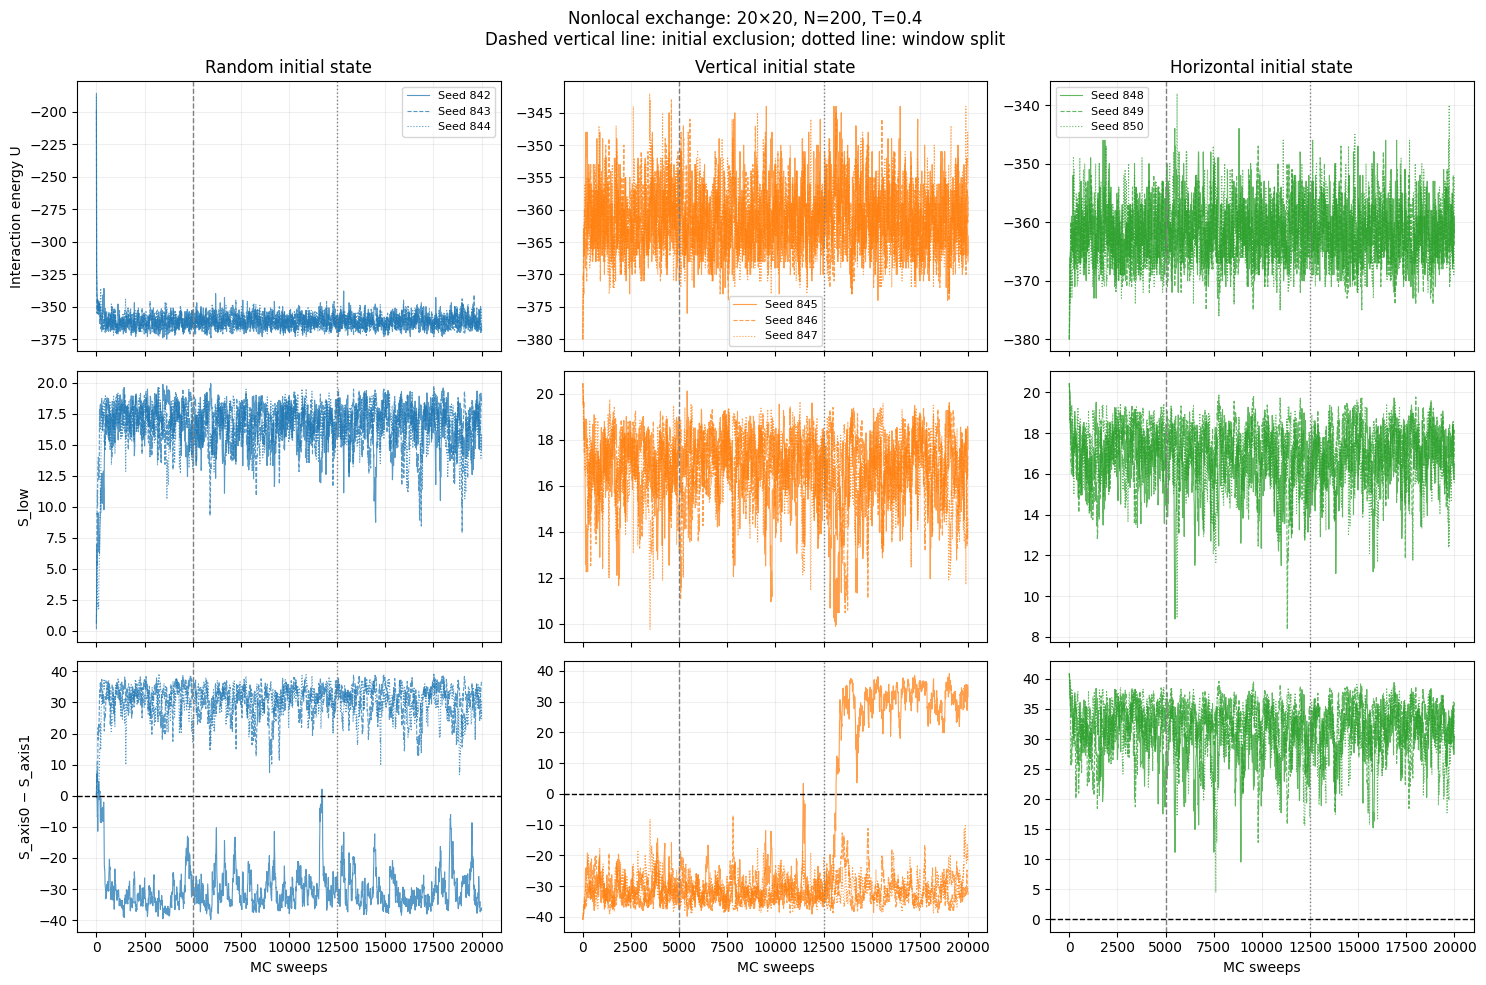

Window means: 5001–12500 / 12501–20000
Initial     Seed |       U       |    S_low    |    S0 - S1
random     842 | -361.51/-361.22 |   16.53/  16.56 |  -29.90/ -30.36
random     843 | -361.08/-361.77 |   16.48/  16.64 |   30.01/  31.12
random     844 | -361.39/-361.07 |   16.83/  16.52 |   31.41/  29.84
vertical   845 | -361.94/-360.67 |   16.77/  16.32 |  -31.05/  25.05
vertical   846 | -361.61/-361.88 |   16.93/  16.67 |  -31.98/ -31.11
vertical   847 | -362.13/-361.55 |   17.07/  16.60 |  -32.16/ -30.66
horizontal 848 | -360.72/-362.01 |   16.25/  16.79 |   29.55/  31.57
horizontal 849 | -362.59/-362.57 |   17.16/  17.21 |   32.53/  32.43
horizontal 850 | -361.28/-361.25 |   16.63/  16.75 |   30.82/  30.96

Descriptive window means; uncertainty assessment is pending.
Saved to: C:\Users\user\Documents\GitHub\active-matter-reproductions\lattice-gas\results\nonlocal_20x20_20261103_204046_897070


In [46]:
import matplotlib.pyplot as plt

colors = {
    "random": "tab:blue",
    "vertical": "tab:orange",
    "horizontal": "tab:green",
}
styles = ["-", "--", ":"]

fig, axes = plt.subplots(
    3, 3, figsize=(15, 10), sharex=True, squeeze=False
)

window_rows = []

for col, initial in enumerate(nl20_config["seeds"]):
    for index, seed in enumerate(nl20_config["seeds"][initial]):
        run = nl20_runs[(initial, seed)]
        t = np.asarray(run["record_sweeps"])

        # Signed directional difference.
        # Axis-exchange symmetry implies an equilibrium mean of zero.
        directional_difference = run["S_axis0"] - run["S_axis1"]

        observables = {
            "U": np.asarray(run["U"]),
            "S_low": np.asarray(run["S_low"]),
            "S_axis0_minus_S_axis1": directional_difference,
        }

        for row, (name, values) in enumerate(observables.items()):
            ax = axes[row, col]
            ax.plot(
                t, values,
                color=colors[initial],
                linestyle=styles[index],
                linewidth=0.8,
                alpha=0.75,
                label=f"Seed {seed}",
            )

            for start, end in nl20_config["analysis_windows"]:
                mask = (t >= start) & (t <= end)
                window_rows.append({
                    "initial": initial,
                    "seed": seed,
                    "observable": name,
                    "start": start,
                    "end": end,
                    "recorded_points": int(mask.sum()),
                    "mean": float(values[mask].mean()),
                })

    axes[0, col].set_title(f"{initial.capitalize()} initial state")
    axes[0, col].legend(fontsize=8)
    axes[2, col].axhline(
        0, color="black", linestyle="--", linewidth=1
    )
    axes[2, col].set_xlabel("MC sweeps")

for row, label in enumerate(
    ["Interaction energy U", "S_low", "S_axis0 − S_axis1"]
):
    axes[row, 0].set_ylabel(label)

for ax in axes.flat:
    ax.axvline(
        nl20_config["initial_exclusion"],
        color="gray", linestyle="--", linewidth=1,
    )
    ax.axvline(
        nl20_config["analysis_windows"][0][1],
        color="gray", linestyle=":", linewidth=1,
    )
    ax.grid(alpha=0.2)

fig.suptitle(
    "Nonlocal exchange: 20×20, N=200, T=0.4\n"
    "Dashed vertical line: initial exclusion; dotted line: window split"
)
fig.tight_layout()
fig.savefig(nl20_dir / "initial_state_diagnostics.png", dpi=180)
plt.show()


# Compact table: each entry shows first-window / second-window means.
lookup = {
    (r["initial"], r["seed"], r["observable"], r["start"]): r["mean"]
    for r in window_rows
}
start1, start2 = [
    window[0] for window in nl20_config["analysis_windows"]
]

print("Window means: 5001–12500 / 12501–20000")
print("Initial     Seed |       U       |    S_low    |    S0 - S1")

for initial, seeds in nl20_config["seeds"].items():
    for seed in seeds:
        entries = []
        for name in ("U", "S_low", "S_axis0_minus_S_axis1"):
            first = lookup[(initial, seed, name, start1)]
            second = lookup[(initial, seed, name, start2)]
            entries.append(f"{first:7.2f}/{second:7.2f}")

        print(f"{initial:10s} {seed} | " + " | ".join(entries))

(nl20_dir / "window_means.json").write_text(
    json.dumps(window_rows, indent=2), encoding="utf-8"
)

print("\nDescriptive window means; uncertainty assessment is pending.")
print("Saved to:", nl20_dir.resolve())


U: after excluding 5000 sweeps
Initial     Seed | Mean     | SEM: B=250 / 500 / 1500 | Window change
random     842 | -361.366 | 0.2741 / 0.2758 / 0.1947 | +0.289
random     843 | -361.424 | 0.2905 / 0.3409 / 0.4133 | -0.683
random     844 | -361.233 | 0.2300 / 0.2676 / 0.3246 | +0.319
vertical   845 | -361.305 | 0.3156 / 0.3713 / 0.4108 | +1.271
vertical   846 | -361.743 | 0.2758 / 0.2514 / 0.3167 | -0.271
vertical   847 | -361.843 | 0.2055 / 0.1875 / 0.1787 | +0.579
horizontal 848 | -361.364 | 0.2558 / 0.2904 / 0.3424 | -1.285
horizontal 849 | -362.581 | 0.2762 / 0.2720 / 0.2736 | +0.019
horizontal 850 | -361.262 | 0.2241 / 0.1850 / 0.1609 | +0.033

S_low: after excluding 5000 sweeps
Initial     Seed | Mean     | SEM: B=250 / 500 / 1500 | Window change
random     842 |   16.544 | 0.1307 / 0.1291 / 0.1243 | +0.036
random     843 |   16.562 | 0.1374 / 0.1628 / 0.1714 | +0.157
random     844 |   16.674 | 0.1156 / 0.1333 / 0.1700 | -0.317
vertical   845 |   16.545 | 0.1520 / 0.1934 / 0.

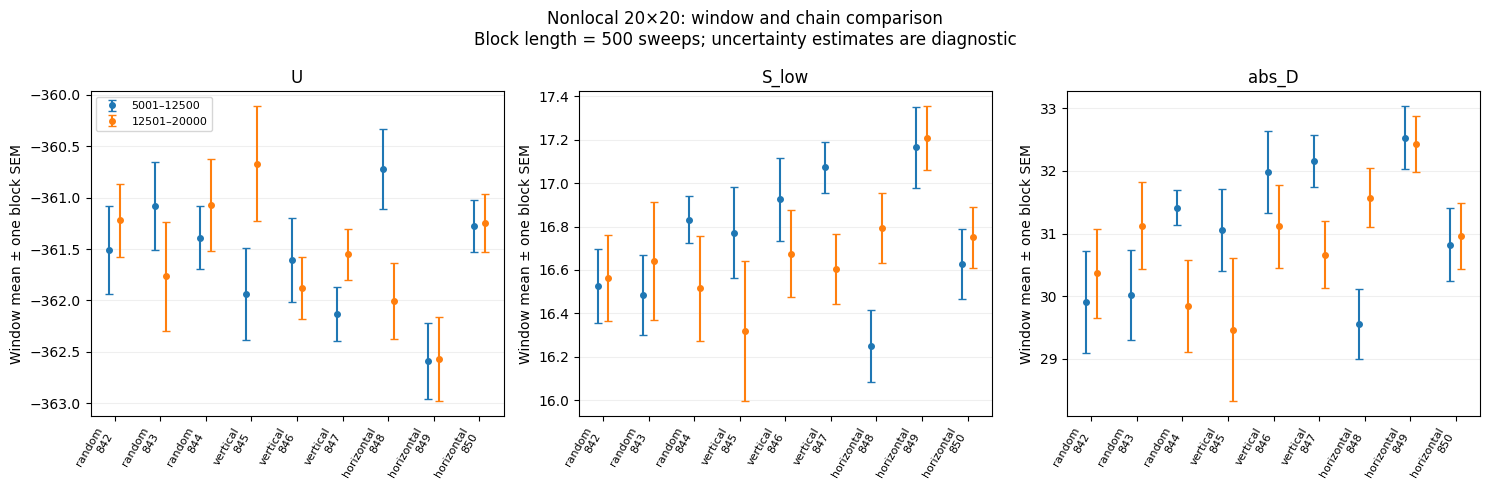

Analysis saved to: C:\Users\user\Documents\GitHub\active-matter-reproductions\lattice-gas\results\nonlocal_20x20_20261103_204046_897070


In [47]:
# Diagnostic analysis of existing trajectories only.
# No equilibrium PASS threshold is introduced here.

import numpy as np
import matplotlib.pyplot as plt
import json

nl20_uncertainty_config = {
    "observables": ["U", "S_low", "abs_D"],
    "initial_exclusion": nl20_config["initial_exclusion"],
    "windows": nl20_config["analysis_windows"],
    "block_lengths_sweeps": [250, 500, 1500],
    "plot_block_length_sweeps": 500,
    "error_bars": "One block SEM; not a guaranteed confidence interval",
    "scope": "Exploratory uncertainty and consistency diagnostics",
}


def nl20_block_stats(values, block_points):
    values = np.asarray(values, dtype=float)

    if len(values) % block_points != 0:
        raise ValueError("Block length must divide the data length.")

    block_means = values.reshape(-1, block_points).mean(axis=1)
    if len(block_means) < 2:
        raise ValueError("At least two blocks are required.")

    sem = block_means.std(ddof=1) / np.sqrt(len(block_means))
    return float(sem), int(len(block_means))


nl20_uncertainty_rows = []
nl20_window_estimates = {}
run_keys = list(nl20_runs)
spacing = nl20_config["record_every"]

for initial, seed in run_keys:
    run = nl20_runs[(initial, seed)]
    t = np.asarray(run["record_sweeps"])
    assert np.all(np.diff(t) == spacing)

    series = {
        "U": np.asarray(run["U"]),
        "S_low": np.asarray(run["S_low"]),
        "abs_D": np.abs(run["S_axis0"] - run["S_axis1"]),
    }

    for name, values in series.items():
        retained = values[t > nl20_config["initial_exclusion"]]

        row = {
            "initial": initial,
            "seed": seed,
            "observable": name,
            "mean": float(retained.mean()),
            "block_estimates": {},
            "windows": [],
        }

        for block_sweeps in nl20_uncertainty_config[
            "block_lengths_sweeps"
        ]:
            assert block_sweeps % spacing == 0
            sem, n_blocks = nl20_block_stats(
                retained, block_sweeps // spacing
            )
            row["block_estimates"][str(block_sweeps)] = {
                "sem": sem,
                "n_blocks": n_blocks,
            }

        for start, end in nl20_config["analysis_windows"]:
            selected = values[(t >= start) & (t <= end)]
            sem, n_blocks = nl20_block_stats(
                selected,
                nl20_uncertainty_config[
                    "plot_block_length_sweeps"
                ] // spacing,
            )
            row["windows"].append({
                "start": start,
                "end": end,
                "mean": float(selected.mean()),
                "sem": sem,
                "n_blocks": n_blocks,
            })

        row["second_minus_first"] = (
            row["windows"][1]["mean"] - row["windows"][0]["mean"]
        )
        nl20_uncertainty_rows.append(row)
        nl20_window_estimates[(initial, seed, name)] = row["windows"]


# Print one compact table per observable.
for name in nl20_uncertainty_config["observables"]:
    print(f"\n{name}: after excluding 5000 sweeps")
    print(
        "Initial     Seed | Mean     | "
        "SEM: B=250 / 500 / 1500 | Window change"
    )

    for row in nl20_uncertainty_rows:
        if row["observable"] != name:
            continue

        sem_text = " / ".join(
            f"{row['block_estimates'][str(b)]['sem']:.4f}"
            for b in nl20_uncertainty_config["block_lengths_sweeps"]
        )
        print(
            f"{row['initial']:10s} {row['seed']} | "
            f"{row['mean']:8.3f} | {sem_text} | "
            f"{row['second_minus_first']:+.3f}"
        )

print("\nFull measurement interval: 60 / 30 / 10 blocks.")
print("Each plotted window: 15 blocks of 500 sweeps.")


# Compare the two prespecified windows for each trajectory.
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
positions = np.arange(len(run_keys))
labels = [f"{initial}\n{seed}" for initial, seed in run_keys]

for ax, name in zip(axes, nl20_uncertainty_config["observables"]):
    for window_index, offset in enumerate((-0.12, 0.12)):
        estimates = [
            nl20_window_estimates[(initial, seed, name)][window_index]
            for initial, seed in run_keys
        ]
        start, end = nl20_config["analysis_windows"][window_index]

        ax.errorbar(
            positions + offset,
            [item["mean"] for item in estimates],
            yerr=[item["sem"] for item in estimates],
            fmt="o", markersize=4, capsize=3,
            label=f"{start}–{end}",
        )

    ax.set_xticks(positions)
    ax.set_xticklabels(labels, rotation=60, ha="right", fontsize=8)
    ax.set_title(name)
    ax.set_ylabel("Window mean ± one block SEM")
    ax.grid(axis="y", alpha=0.2)

axes[0].legend(fontsize=8)
fig.suptitle(
    "Nonlocal 20×20: window and chain comparison\n"
    "Block length = 500 sweeps; uncertainty estimates are diagnostic"
)
fig.tight_layout()
fig.savefig(nl20_dir / "invariant_window_uncertainty.png", dpi=180)
plt.show()

(nl20_dir / "invariant_uncertainty.json").write_text(
    json.dumps({
        "analysis_config": nl20_uncertainty_config,
        "results": nl20_uncertainty_rows,
    }, indent=2),
    encoding="utf-8",
)

print("Analysis saved to:", nl20_dir.resolve())

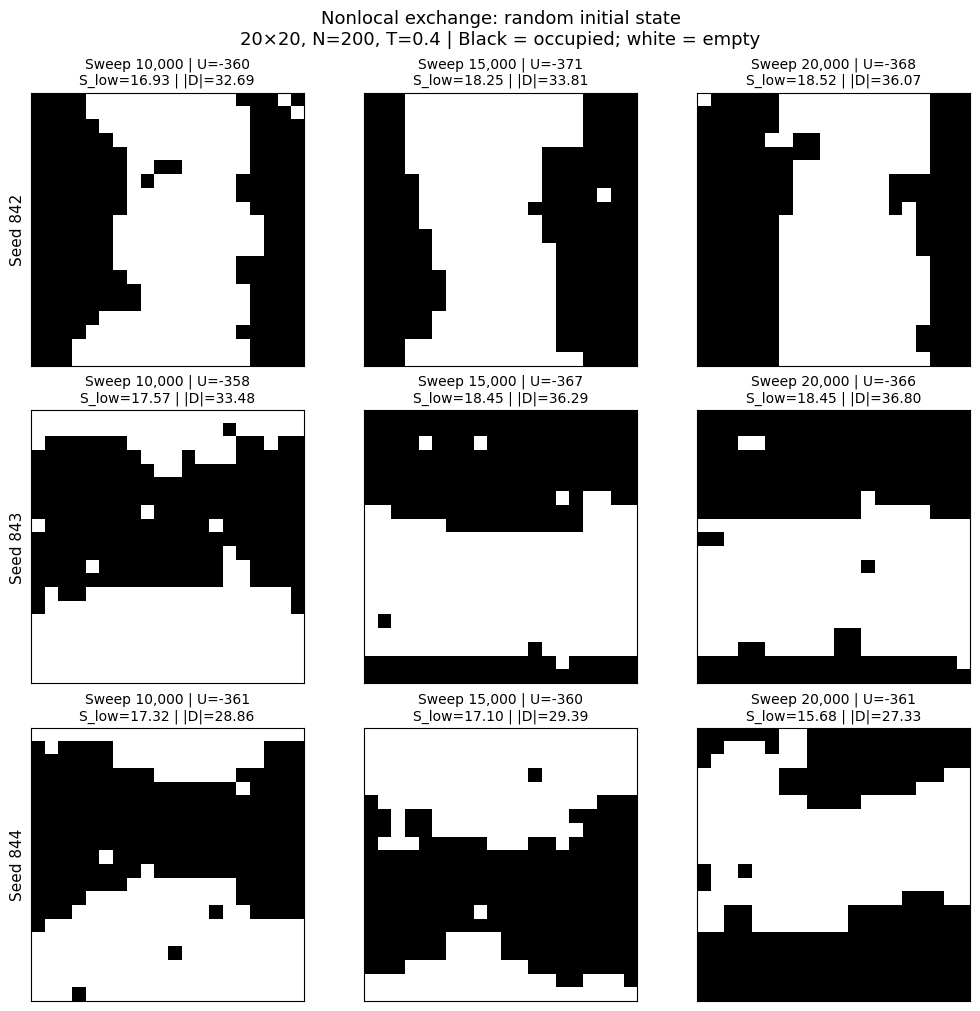

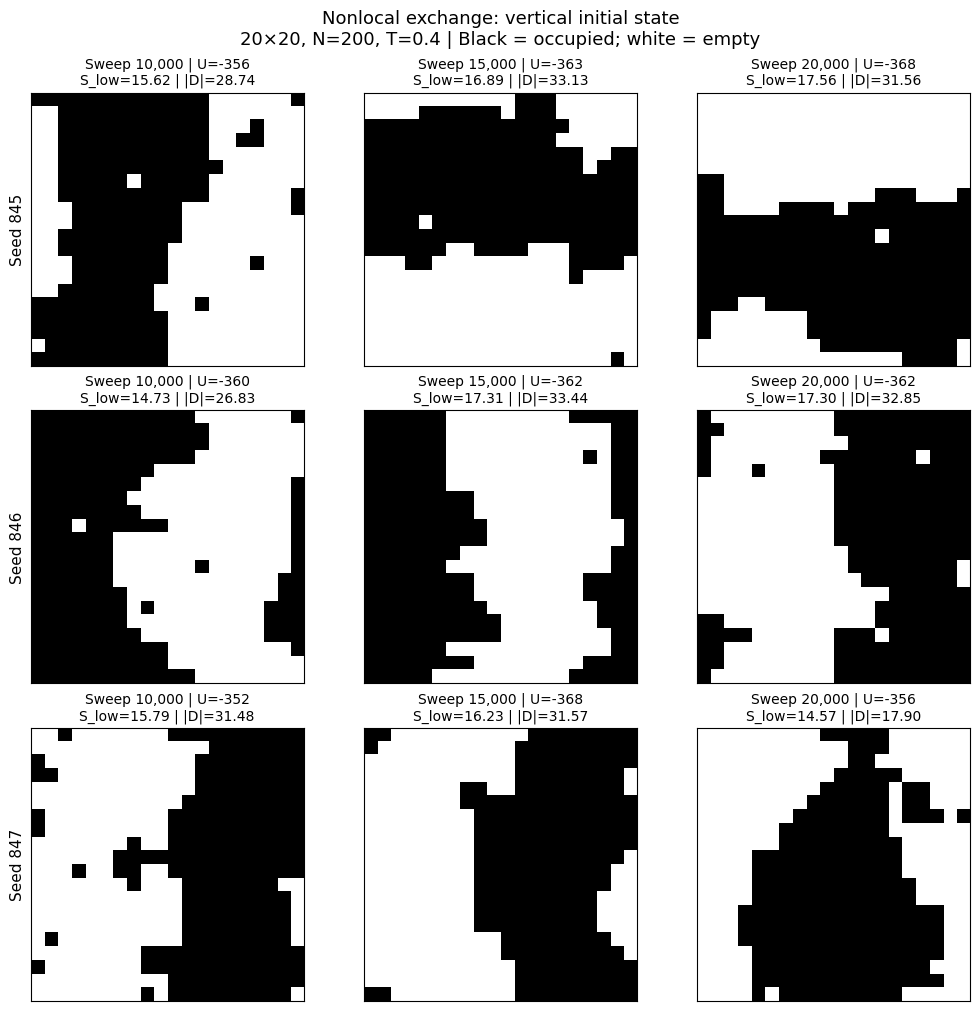

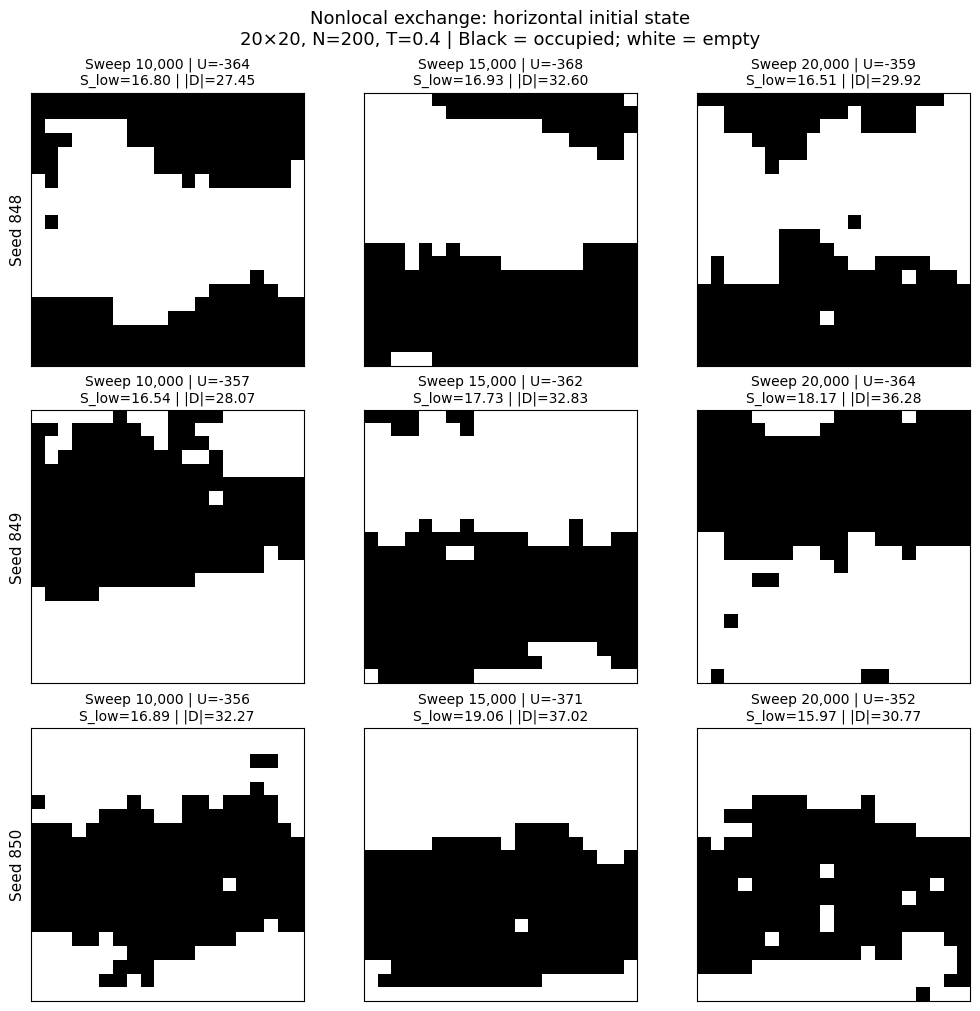

PASS: saved configurations match recorded observables.
Saved to: C:\Users\user\Documents\GitHub\active-matter-reproductions\lattice-gas\results\nonlocal_20x20_20261103_204046_897070


In [48]:
import numpy as np
import matplotlib.pyplot as plt
import json

inspection_sweeps = [10000, 15000, 20000]
inspection_rows = []

for initial, seeds in nl20_config["seeds"].items():
    fig, axes = plt.subplots(
        len(seeds), len(inspection_sweeps),
        figsize=(10, 10), squeeze=False,
        constrained_layout=True,
    )

    for row, seed in enumerate(seeds):
        run = nl20_runs[(initial, seed)]
        saved_sweeps = np.asarray(run["configuration_sweeps"])
        recorded_sweeps = np.asarray(run["record_sweeps"])

        for col, sweep in enumerate(inspection_sweeps):
            snapshot_matches = np.flatnonzero(saved_sweeps == sweep)
            record_matches = np.flatnonzero(recorded_sweeps == sweep)

            assert len(snapshot_matches) == 1
            assert len(record_matches) == 1

            state = run["configurations"][snapshot_matches[0]]
            record_index = record_matches[0]

            # Recompute observables from the saved configuration.
            measured = nl20_observables(state)
            assert int(state.sum()) == nl20_config["N"]

            for name in ("U", "S_low", "S_axis0", "S_axis1"):
                assert np.isclose(
                    measured[name], run[name][record_index],
                    rtol=0.0, atol=1e-10,
                )

            abs_d = abs(
                measured["S_axis0"] - measured["S_axis1"]
            )

            ax = axes[row, col]
            ax.imshow(
                state,
                cmap="binary",
                vmin=0, vmax=1,
                interpolation="nearest",
                origin="upper",
            )
            ax.set_title(
                f"Sweep {sweep:,} | U={measured['U']:.0f}\n"
                f"S_low={measured['S_low']:.2f} | |D|={abs_d:.2f}",
                fontsize=10,
            )
            ax.set_xticks([])
            ax.set_yticks([])

            if col == 0:
                ax.set_ylabel(f"Seed {seed}", fontsize=11)

            inspection_rows.append({
                "initial": initial,
                "seed": seed,
                "sweep": sweep,
                **measured,
                "abs_D": float(abs_d),
            })

    fig.suptitle(
        f"Nonlocal exchange: {initial} initial state\n"
        "20×20, N=200, T=0.4 | Black = occupied; white = empty",
        fontsize=13,
    )
    fig.savefig(
        nl20_dir / f"configuration_inspection_{initial}.png",
        dpi=180,
    )
    plt.show()
    plt.close(fig)

(nl20_dir / "configuration_inspection.json").write_text(
    json.dumps(inspection_rows, indent=2), encoding="utf-8"
)

print("PASS: saved configurations match recorded observables.")
print("Saved to:", nl20_dir.resolve())

## Bounded Continuation to 100,000 Sweeps

### Objective
Assess whether longer nonlocal trajectories support a preliminary
reference for the means of U, S_low, and |D|, where D = S_axis0 - S_axis1.
Assess directional sampling separately.

### Fixed execution protocol
- Continue all nine existing trajectories from sweep 20,000 to 100,000.
- Restore each saved final configuration and RNG state.
- Keep the model, temperature, particle number, and update rule unchanged.
- Record observables every 10 sweeps and configurations every 100 sweeps.
- Save a checkpoint every 20,000 additional sweeps.
- Preserve the original pilot data.

### Fixed analysis
Use only the continuation interval, sweeps 20,001–100,000, for the
primary assessment. This choice does not assert equilibration at 20,000.

Compare windows 20,001–60,000 and 60,001–100,000.
Estimate block SEM using block lengths of 1,000, 2,000, and 4,000 sweeps.
For the precision screen, use the largest of the three full-interval SEMs.

| Observable | Maximum range of chain means | Maximum absolute window change per chain | Maximum SEM per chain |
|---|---:|---:|---:|
| U | 1.0 | 1.0 | 0.25 |
| S_low | 0.5 | 0.5 | 0.125 |
| abs_D | 2.0 | 2.0 | 0.5 |

These are prospective practical diagnostic tolerances, not bounds on
unknown equilibrium bias. Report every criterion without replacing seeds.

For directional sampling, report D traces, chain means, and the fractions
of recorded times with D > 0, D < 0, and D = 0. Do not impose symmetry
by rotating configurations during this experiment.

### Decision and stopping
Stop all chains at 100,000 sweeps regardless of the diagnostic outcome.

Failure of any mean-reference screen leaves that observable unqualified
under this protocol. Passing all screens supports a provisional,
observable-specific reference assessment; it does not establish accuracy
of the full configuration distribution or exclude unvisited states.

Persistent directional imbalance remains a limitation of the raw
configuration samples. No automatic further extension is authorized
by this protocol.

In [49]:
from pathlib import Path
from datetime import datetime
import json
import time
import numpy as np

# Use the existing pilot output directory.
nl100_source = Path(nl20_dir).resolve()
source_config = json.loads(
    (nl100_source / "config.json").read_text(encoding="utf-8")
)

assert source_config["sweeps"] == 20000
assert source_config["L"] == 20
assert source_config["N"] == 200

nl100_config = {
    "source_directory": str(nl100_source),
    "model_config": source_config,
    "start_sweep": 20000,
    "end_sweep": 100000,
    "checkpoint_interval": 20000,
    "record_every": 10,
    "configuration_every": 100,
    "analysis_windows": [[20001, 60000], [60001, 100000]],
    "block_lengths_sweeps": [1000, 2000, 4000],
    "mean_screen": {
        "U": {"chain_range": 1.0, "window_change": 1.0, "sem": 0.25},
        "S_low": {
            "chain_range": 0.5, "window_change": 0.5, "sem": 0.125
        },
        "abs_D": {
            "chain_range": 2.0, "window_change": 2.0, "sem": 0.5
        },
    },
    "status": "Continuation data; reference assessment pending",
}

# Validate every starting checkpoint before beginning simulations.
nl100_starts = {}

for initial, seeds in source_config["seeds"].items():
    for seed in seeds:
        stem = f"{initial}_seed_{seed}"

        with np.load(
            nl100_source / f"{stem}.npz", allow_pickle=False
        ) as data:
            assert int(data["record_sweeps"][-1]) == 20000
            state = data["final_state"].astype(np.int64).copy()
            saved_u = float(data["U"][-1])

        rng_state = json.loads(
            (nl100_source / f"{stem}_rng.json").read_text(
                encoding="utf-8"
            )
        )
        assert rng_state["bit_generator"] == "PCG64"
        assert state.shape == (20, 20)
        assert int(state.sum()) == 200
        assert np.isin(state, [0, 1]).all()
        assert np.isclose(
            lattice_energy(state, source_config["epsilon"], 0.0),
            saved_u, rtol=0.0, atol=1e-10,
        )

        nl100_starts[(initial, seed)] = (state, rng_state)

nl100_dir = (
    nl100_source.parent
    / datetime.now().strftime("nonlocal_20x20_100k_%Y%m%d_%H%M%S_%f")
)
nl100_dir.mkdir(parents=True, exist_ok=False)

(nl100_dir / "config.json").write_text(
    json.dumps(nl100_config, indent=2), encoding="utf-8"
)


def nl100_measure(state):
    epsilon = source_config["epsilon"]
    spectrum = (
        np.abs(np.fft.fft2(state.astype(float) - state.mean()))**2
        / state.size
    )
    s0 = float((spectrum[1, 0] + spectrum[-1, 0]) / 2)
    s1 = float((spectrum[0, 1] + spectrum[0, -1]) / 2)

    return {
        "U": lattice_energy(state, epsilon=epsilon, mu=0.0),
        "boundary": int(
            np.count_nonzero(state != np.roll(state, -1, axis=0))
            + np.count_nonzero(state != np.roll(state, -1, axis=1))
        ),
        "S_axis0": s0,
        "S_axis1": s1,
        "S_low": (s0 + s1) / 2,
    }


nl100_started = time.perf_counter()

for (initial, seed), (saved_state, saved_rng) in nl100_starts.items():
    state = saved_state.copy()
    run_rng = np.random.Generator(np.random.PCG64())
    run_rng.bit_generator.state = saved_rng

    tracked_u = lattice_energy(
        state, epsilon=source_config["epsilon"], mu=0.0
    )

    for chunk_start in range(20000, 100000, 20000):
        chunk_end = chunk_start + 20000
        chunk_started = time.perf_counter()

        start_state = state.copy()
        start_rng_json = json.dumps(run_rng.bit_generator.state)

        record_sweeps = []
        configuration_sweeps = []
        configurations = []
        traces = {
            name: [] for name in
            ("U", "boundary", "S_axis0", "S_axis1", "S_low")
        }
        moves = np.empty(20000)

        for sweep in range(chunk_start + 1, chunk_end + 1):
            move_fraction, delta_u = nonlocal_sweep(
                state,
                temperature=source_config["temperature"],
                rng=run_rng,
                epsilon=source_config["epsilon"],
            )
            moves[sweep - chunk_start - 1] = move_fraction
            tracked_u += delta_u

            if sweep % nl100_config["record_every"] == 0:
                measured = nl100_measure(state)

                assert int(state.sum()) == source_config["N"]
                assert np.isin(state, [0, 1]).all()
                assert np.isclose(
                    tracked_u, measured["U"],
                    rtol=0.0, atol=1e-10,
                )
                assert np.isclose(
                    measured["boundary"],
                    4 * source_config["N"]
                    + 2 * measured["U"] / source_config["epsilon"],
                    rtol=0.0, atol=1e-10,
                )

                record_sweeps.append(sweep)
                for name in traces:
                    traces[name].append(measured[name])

            if sweep % nl100_config["configuration_every"] == 0:
                configuration_sweeps.append(sweep)
                configurations.append(state.astype(np.int8).copy())

            if sweep % 10000 == 0:
                print(
                    f"{initial:10s}, seed={seed} | "
                    f"{sweep:6d}/100000 | "
                    f"U={measured['U']:.0f}",
                    flush=True,
                )

        # Each file contains one segment and its matching RNG states.
        filename = (
            f"{initial}_seed_{seed}_"
            f"{chunk_start + 1:06d}_{chunk_end:06d}.npz"
        )
        np.savez_compressed(
            nl100_dir / filename,
            record_sweeps=np.asarray(record_sweeps),
            **{name: np.asarray(values)
               for name, values in traces.items()},
            move_fraction=moves,
            configuration_sweeps=np.asarray(configuration_sweeps),
            configurations=np.stack(configurations),
            start_sweep=chunk_start,
            end_sweep=chunk_end,
            initial_state=start_state,
            final_state=state.copy(),
            rng_state_start_json=start_rng_json,
            rng_state_end_json=json.dumps(run_rng.bit_generator.state),
            elapsed_seconds=time.perf_counter() - chunk_started,
        )
        print(f"  Saved checkpoint at sweep {chunk_end}.", flush=True)

print(
    f"\nFinished all nine continuations in "
    f"{time.perf_counter() - nl100_started:.1f} s."
)
print("PASS: conservation and energy checks at recorded times.")
print("Reference assessment remains pending.")
print("Saved to:", nl100_dir.resolve())

random    , seed=842 |  30000/100000 | U=-363
random    , seed=842 |  40000/100000 | U=-364
  Saved checkpoint at sweep 40000.
random    , seed=842 |  50000/100000 | U=-353
random    , seed=842 |  60000/100000 | U=-355
  Saved checkpoint at sweep 60000.
random    , seed=842 |  70000/100000 | U=-356
random    , seed=842 |  80000/100000 | U=-360
  Saved checkpoint at sweep 80000.
random    , seed=842 |  90000/100000 | U=-360
random    , seed=842 | 100000/100000 | U=-361
  Saved checkpoint at sweep 100000.
random    , seed=843 |  30000/100000 | U=-364
random    , seed=843 |  40000/100000 | U=-370
  Saved checkpoint at sweep 40000.
random    , seed=843 |  50000/100000 | U=-368
random    , seed=843 |  60000/100000 | U=-368
  Saved checkpoint at sweep 60000.
random    , seed=843 |  70000/100000 | U=-354
random    , seed=843 |  80000/100000 | U=-366
  Saved checkpoint at sweep 80000.
random    , seed=843 |  90000/100000 | U=-362
random    , seed=843 | 100000/100000 | U=-362
  Saved checkpoint

Loaded 36 segments; continuation coverage and joins checked.

U
Initial     Seed | Mean     | Max SEM | Window change
random     842 | -361.834 |  0.1135 | +0.0785
random     843 | -361.654 |  0.1146 | +0.2280
random     844 | -361.551 |  0.1290 | +0.0493
vertical   845 | -361.722 |  0.1369 | +0.1838
vertical   846 | -361.626 |  0.1687 | +0.1490
vertical   847 | -361.683 |  0.1255 | -0.0410
horizontal 848 | -361.674 |  0.1287 | +0.0118
horizontal 849 | -361.998 |  0.1294 | -0.2303
horizontal 850 | -361.904 |  0.1329 | -0.0133
  chain_range  : 0.4468 <= 1.0000 : PASS
  window_change: 0.2303 <= 1.0000 : PASS
  sem          : 0.1687 <= 0.2500 : PASS

S_low
Initial     Seed | Mean     | Max SEM | Window change
random     842 |   16.823 |  0.0656 | -0.0612
random     843 |   16.791 |  0.0577 | -0.1196
random     844 |   16.691 |  0.0941 | -0.1073
vertical   845 |   16.729 |  0.0633 | +0.0191
vertical   846 |   16.730 |  0.0694 | +0.0559
vertical   847 |   16.812 |  0.0754 | -0.0920
horizont

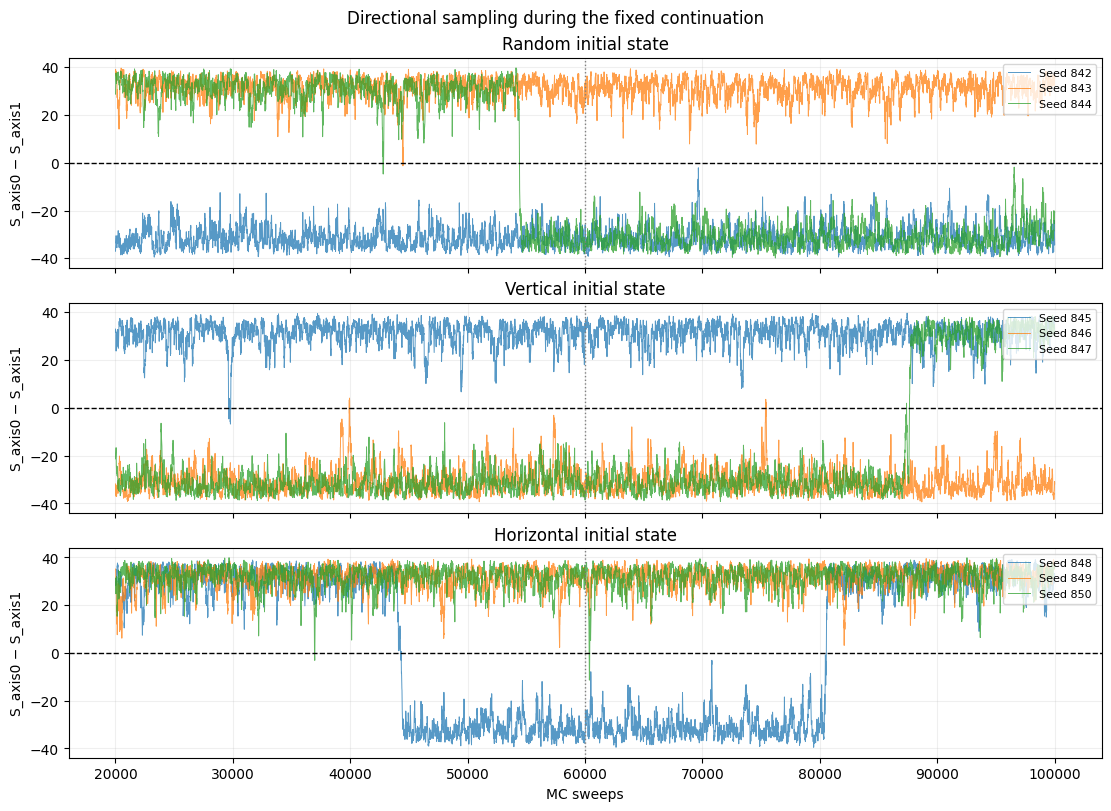


All mean screens passed: True
Directional sampling requires separate assessment.
These screens do not establish full-distribution accuracy.
Saved to: C:\Users\user\Documents\GitHub\active-matter-reproductions\lattice-gas\results\nonlocal_20x20_100k_20261103_204437_450793


In [50]:
import json
import numpy as np
import matplotlib.pyplot as plt

# Read the frozen protocol from disk.
assessment_config = json.loads(
    (nl100_dir / "config.json").read_text(encoding="utf-8")
)
model_config = assessment_config["model_config"]
spacing = assessment_config["record_every"]

nl100_runs = {}
loaded_segments = 0

# Assemble each trajectory in chronological order.
for initial, seeds in model_config["seeds"].items():
    for seed in seeds:
        parts = []
        previous_final = None
        previous_rng = None

        for start in range(
            assessment_config["start_sweep"],
            assessment_config["end_sweep"],
            assessment_config["checkpoint_interval"],
        ):
            end = start + assessment_config["checkpoint_interval"]
            path = nl100_dir / (
                f"{initial}_seed_{seed}_{start + 1:06d}_{end:06d}.npz"
            )

            with np.load(path, allow_pickle=False) as data:
                assert int(data["start_sweep"]) == start
                assert int(data["end_sweep"]) == end
                assert np.array_equal(
                    data["record_sweeps"],
                    np.arange(start + spacing, end + 1, spacing),
                )

                if previous_final is not None:
                    assert np.array_equal(
                        previous_final, data["initial_state"]
                    )
                    assert previous_rng == json.loads(
                        data["rng_state_start_json"].item()
                    )

                previous_final = data["final_state"].copy()
                previous_rng = json.loads(
                    data["rng_state_end_json"].item()
                )

                parts.append({
                    name: data[name].copy()
                    for name in (
                        "record_sweeps", "U", "S_low",
                        "S_axis0", "S_axis1",
                    )
                })
                loaded_segments += 1

        run = {
            name: np.concatenate([part[name] for part in parts])
            for name in parts[0]
        }
        run["D"] = run["S_axis0"] - run["S_axis1"]
        run["abs_D"] = np.abs(run["D"])

        assert all(np.isfinite(values).all() for values in run.values())
        nl100_runs[(initial, seed)] = run

assert len(nl100_runs) == 9
assert loaded_segments == 36
print("Loaded 36 segments; continuation coverage and joins checked.")


def continuation_block_sem(values, block_sweeps):
    values = np.asarray(values, dtype=float)
    assert block_sweeps % spacing == 0
    points = block_sweeps // spacing
    assert len(values) % points == 0

    block_means = values.reshape(-1, points).mean(axis=1)
    assert len(block_means) >= 2
    return float(
        block_means.std(ddof=1) / np.sqrt(len(block_means))
    )


assessment_rows = []
direction_rows = []

for (initial, seed), run in nl100_runs.items():
    t = run["record_sweeps"]

    for observable in assessment_config["mean_screen"]:
        values = run[observable]
        sems = {
            str(block): continuation_block_sem(values, block)
            for block in assessment_config["block_lengths_sweeps"]
        }

        window_means = [
            float(values[(t >= start) & (t <= end)].mean())
            for start, end in assessment_config["analysis_windows"]
        ]

        assessment_rows.append({
            "initial": initial,
            "seed": seed,
            "observable": observable,
            "mean": float(values.mean()),
            "sem_by_block_sweeps": sems,
            "largest_sem": max(sems.values()),
            "window_means": window_means,
            "window_change": window_means[1] - window_means[0],
        })

    d = run["D"]
    direction_rows.append({
        "initial": initial,
        "seed": seed,
        "mean_D": float(d.mean()),
        "fraction_positive": float(np.mean(d > 0)),
        "fraction_negative": float(np.mean(d < 0)),
        "fraction_zero": float(np.mean(d == 0)),
    })


# Apply exactly the prespecified practical screens.
screen_results = {}

for observable, limits in assessment_config["mean_screen"].items():
    rows = [
        row for row in assessment_rows
        if row["observable"] == observable
    ]

    measured = {
        "chain_range": float(np.ptp([row["mean"] for row in rows])),
        "window_change": max(abs(row["window_change"]) for row in rows),
        "sem": max(row["largest_sem"] for row in rows),
    }
    checks = {
        criterion: measured[criterion] <= limits[criterion]
        for criterion in limits
    }

    screen_results[observable] = {
        "measured": measured,
        "limits": limits,
        "checks": checks,
        "all_pass": all(checks.values()),
    }

    print(f"\n{observable}")
    print("Initial     Seed | Mean     | Max SEM | Window change")
    for row in rows:
        print(
            f"{row['initial']:10s} {row['seed']} | "
            f"{row['mean']:8.3f} | "
            f"{row['largest_sem']:7.4f} | "
            f"{row['window_change']:+.4f}"
        )

    for criterion in limits:
        status = "PASS" if checks[criterion] else "NOT MET"
        print(
            f"  {criterion:13s}: {measured[criterion]:.4f} "
            f"<= {limits[criterion]:.4f} : {status}"
        )


print("\nDirectional sampling: recorded-time fractions")
print("Initial     Seed | Mean D  | P(D>0) | P(D<0) | P(D=0)")
for row in direction_rows:
    print(
        f"{row['initial']:10s} {row['seed']} | "
        f"{row['mean_D']:7.2f} | "
        f"{row['fraction_positive']:6.3f} | "
        f"{row['fraction_negative']:6.3f} | "
        f"{row['fraction_zero']:6.3f}"
    )


fig, axes = plt.subplots(
    3, 1, figsize=(11, 8), sharex=True, sharey=True,
    constrained_layout=True,
)

for ax, (initial, seeds) in zip(
    axes, model_config["seeds"].items()
):
    for seed in seeds:
        run = nl100_runs[(initial, seed)]
        ax.plot(
            run["record_sweeps"], run["D"],
            linewidth=0.7, alpha=0.75,
            label=f"Seed {seed}",
        )

    ax.axhline(0, color="black", linestyle="--", linewidth=1)
    ax.axvline(60000, color="gray", linestyle=":", linewidth=1)
    ax.set_title(f"{initial.capitalize()} initial state")
    ax.set_ylabel("S_axis0 − S_axis1")
    ax.legend(fontsize=8, loc="upper right")
    ax.grid(alpha=0.2)

axes[-1].set_xlabel("MC sweeps")
fig.suptitle("Directional sampling during the fixed continuation")
fig.savefig(nl100_dir / "directional_sampling.png", dpi=180)
plt.show()

all_mean_screens_pass = all(
    result["all_pass"] for result in screen_results.values()
)

assessment = {
    "analysis_windows": assessment_config["analysis_windows"],
    "block_lengths_sweeps": assessment_config["block_lengths_sweeps"],
    "per_chain": assessment_rows,
    "mean_screens": screen_results,
    "directional_sampling": direction_rows,
    "all_mean_screens_pass": all_mean_screens_pass,
    "scope": (
        "Prespecified observable-mean diagnostic screens. "
        "No bound on equilibrium bias or full-distribution qualification."
    ),
}

(nl100_dir / "reference_assessment.json").write_text(
    json.dumps(assessment, indent=2), encoding="utf-8"
)

print("\nAll mean screens passed:", all_mean_screens_pass)
print("Directional sampling requires separate assessment.")
print("These screens do not establish full-distribution accuracy.")
print("Saved to:", nl100_dir.resolve())

In [51]:
import json
import numpy as np

# Summarize the existing assessment; no new simulation.
assessment = json.loads(
    (nl100_dir / "reference_assessment.json").read_text(
        encoding="utf-8"
    )
)

assert assessment["all_mean_screens_pass"], (
    "The prespecified mean screens did not all pass."
)

reference_rows = []

for observable in ("U", "S_low", "abs_D"):
    rows = [
        row for row in assessment["per_chain"]
        if row["observable"] == observable
    ]
    assert len(rows) == 9
    assert len({(row["initial"], row["seed"]) for row in rows}) == 9

    means = np.array([row["mean"] for row in rows], dtype=float)
    chain_sems = np.array(
        [row["largest_sem"] for row in rows], dtype=float
    )
    n_chains = len(rows)

    reference_rows.append({
        "observable": observable,
        "mean": float(means.mean()),
        "between_chain_sem": float(
            means.std(ddof=1) / np.sqrt(n_chains)
        ),
        "combined_block_sem": float(
            np.sqrt(np.sum(chain_sems**2)) / n_chains
        ),
        "chain_mean_min": float(means.min()),
        "chain_mean_max": float(means.max()),
        "n_chains": n_chains,
    })

table_lines = [
    "| Observable | Mean | Between-chain SEM | Combined block SEM |",
    "|---|---:|---:|---:|",
]

for row in reference_rows:
    table_lines.append(
        f"| {row['observable']} "
        f"| {row['mean']:.6f} "
        f"| {row['between_chain_sem']:.6f} "
        f"| {row['combined_block_sem']:.6f} |"
    )

table = "\n".join(table_lines)

markdown = f"""## Bounded continuation: reference assessment

### System and measurement interval

- Periodic square lattice: L = 20, N = 200.
- Temperature: T = 0.4; interaction strength: epsilon = 1.
- Sampler: nonlocal Metropolis exchange at fixed particle number.
- Nine trajectories: three random, three vertical-stripe, and
  three horizontal-stripe initial states.
- Each trajectory was continued to 100,000 sweeps.
- Summary estimates use recorded samples after sweep 20,000,
  through sweep 100,000, with equal weight for each trajectory.

### Provisional observable-mean reference

{table}

Between-chain SEM is the sample standard deviation of the nine
trajectory means divided by sqrt(9). Combined block SEM is
sqrt(sum(s_i^2))/9, where s_i is the largest block SEM obtained
for trajectory i using block lengths of 1,000, 2,000, and 4,000
sweeps. The latter calculation assumes independent trajectories
and adequate within-trajectory uncertainty estimates.

These are diagnostic estimates of statistical uncertainty.
Neither estimates common equilibration bias, and they are not
combined into a certified confidence interval.

### Decision

All prespecified mean screens passed for U, S_low, and abs_D:
between-chain mean range, change between the two measurement
windows, and maximum within-chain block SEM.

Retain these estimates as a provisional observable-mean reference
for this specific system and parameter set. Passing the screens
does not establish an upper bound on equilibrium bias.

Directional sampling remains limited: several trajectories spend
most of the measurement interval in one orientation, and persistent
orientation changes are infrequent. Full-configuration equilibrium
sampling is therefore not qualified by this investigation.

The bounded continuation is complete. No further extension is
included in this task. Nonlocal exchange is used here for sampling;
its trajectories are not interpreted as local Kawasaki dynamics.

### Provenance

The numerical assessment and frozen criteria are retained in
`reference_assessment.json` and `config.json` in this directory.
The trajectory segments and RNG checkpoints are retained unchanged.
"""

summary = {
    "status": "PROVISIONAL_OBSERVABLE_MEAN_REFERENCE",
    "reference_rows": reference_rows,
    "mean_screens": assessment["mean_screens"],
    "full_configuration_equilibrium_qualified": False,
    "uncertainty_scope": (
        "Diagnostic statistical uncertainty; "
        "common equilibrium bias is not quantified."
    ),
    "source_assessment": "reference_assessment.json",
}

(nl100_dir / "provisional_reference_summary.json").write_text(
    json.dumps(summary, indent=2, allow_nan=False),
    encoding="utf-8",
)
(nl100_dir / "REFERENCE_DECISION.md").write_text(
    markdown, encoding="utf-8"
)

print(table)
print("\nDecision: PROVISIONAL_OBSERVABLE_MEAN_REFERENCE")
print("Bounded continuation complete; no additional simulation.")
print("Saved to:", nl100_dir.resolve())

| Observable | Mean | Between-chain SEM | Combined block SEM |
|---|---:|---:|---:|
| U | -361.738375 | 0.048010 | 0.043971 |
| S_low | 16.794813 | 0.026793 | 0.023187 |
| abs_D | 31.228528 | 0.097942 | 0.078962 |

Decision: PROVISIONAL_OBSERVABLE_MEAN_REFERENCE
Bounded continuation complete; no additional simulation.
Saved to: C:\Users\user\Documents\GitHub\active-matter-reproductions\lattice-gas\results\nonlocal_20x20_100k_20261103_204437_450793


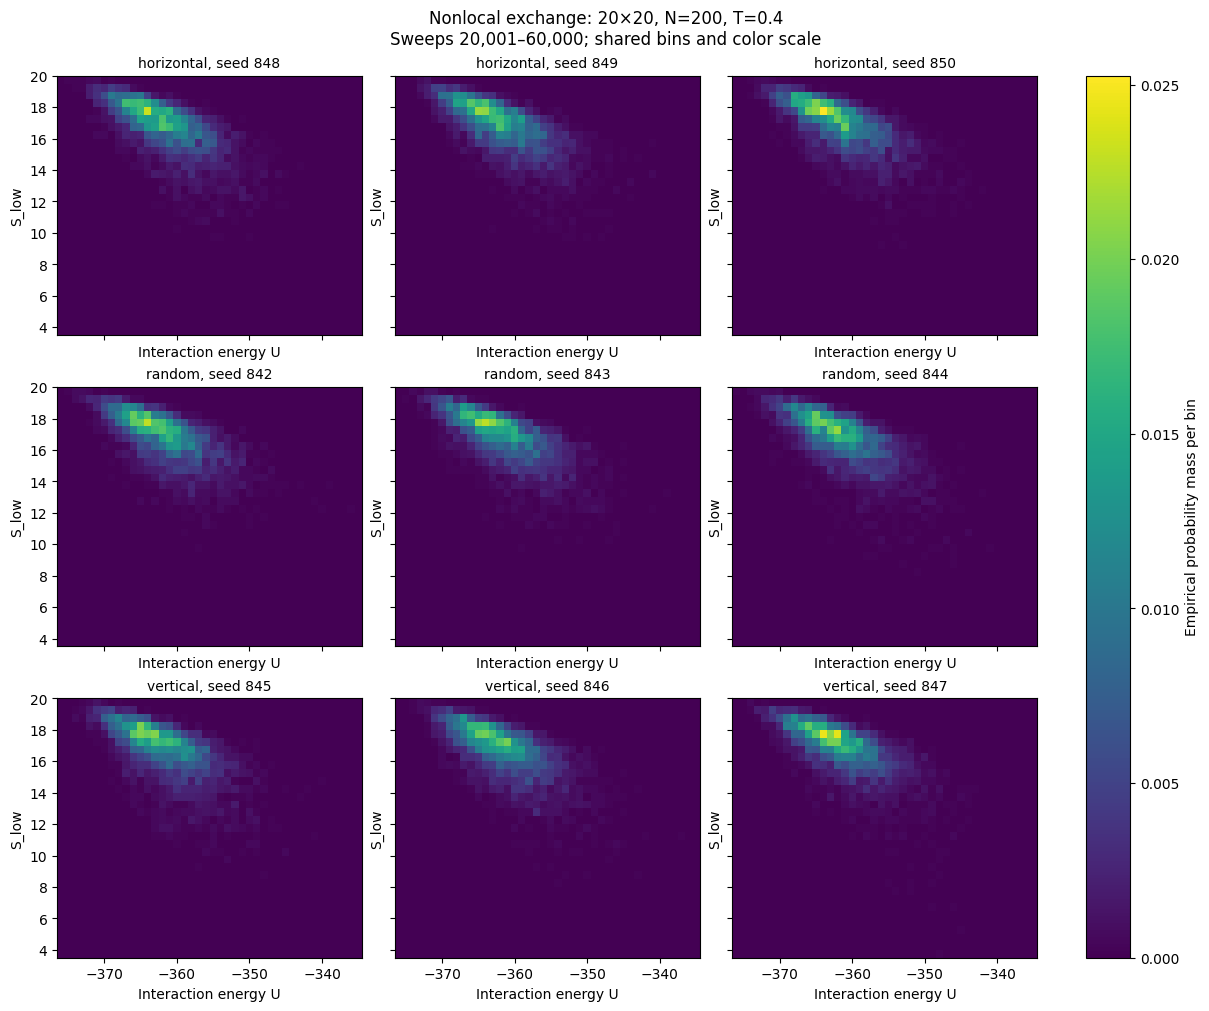

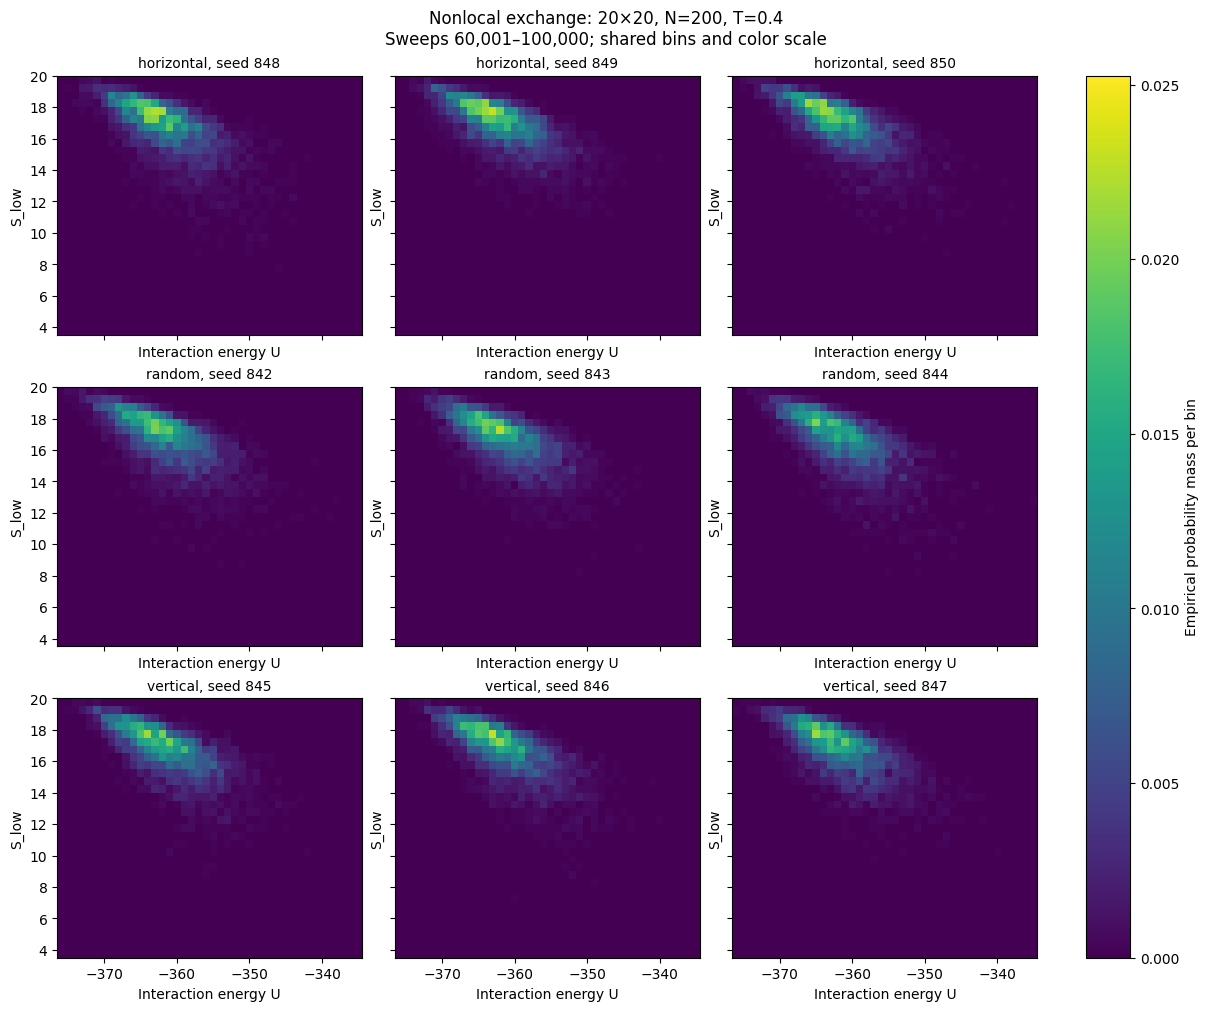

Within-chain TV: first versus second measurement window
horizontal 848 | TV = 0.1443
horizontal 849 | TV = 0.1387
horizontal 850 | TV = 0.1505
random     842 | TV = 0.1310
random     843 | TV = 0.1357
random     844 | TV = 0.1365
vertical   845 | TV = 0.1443
vertical   846 | TV = 0.1263
vertical   847 | TV = 0.1502

Between-chain TV over the full measurement interval:
min=0.0869, median=0.0994, max=0.1186

Exploratory diagnostic only; no PASS/FAIL decision.
Saved to: C:\Users\user\Documents\GitHub\active-matter-reproductions\lattice-gas\results\nonlocal_20x20_100k_20261103_204437_450793\joint_distribution_diagnostic


In [52]:
import json
import numpy as np
import matplotlib.pyplot as plt

# Existing trajectories only; no new simulation.
keys = sorted(nl100_runs)
assert len(keys) == 9

windows = [(20001, 60000), (60001, 100000)]
joint_dir = nl100_dir / "joint_distribution_diagnostic"
joint_dir.mkdir(exist_ok=True)

# Shared bins for every chain and both windows.
# U has integer spacing for epsilon = 1; S_low bin width is 0.5.
all_u = np.concatenate([nl100_runs[k]["U"] for k in keys])
all_s = np.concatenate([nl100_runs[k]["S_low"] for k in keys])

assert np.isfinite(all_u).all() and np.isfinite(all_s).all()
assert np.allclose(all_u, np.rint(all_u), rtol=0, atol=1e-10)

u_edges = np.arange(
    np.floor(all_u.min()) - 0.5,
    np.ceil(all_u.max()) + 1.0,
    1.0,
)
s_width = 0.5
s_edges = s_width * np.arange(
    int(np.floor(all_s.min() / s_width)),
    int(np.floor(all_s.max() / s_width)) + 2,
)

pmfs = np.zeros((
    len(keys), len(windows),
    len(u_edges) - 1, len(s_edges) - 1,
))
sample_counts = np.zeros((len(keys), len(windows)), dtype=int)

for i, key in enumerate(keys):
    run = nl100_runs[key]
    steps = np.asarray(run["record_sweeps"])
    u = np.asarray(run["U"])
    s = np.asarray(run["S_low"])

    for w, (start, end) in enumerate(windows):
        mask = (steps >= start) & (steps <= end)
        expected_steps = np.arange(start + 9, end + 1, 10)
        assert np.array_equal(steps[mask], expected_steps)

        counts, _, _ = np.histogram2d(
            u[mask], s[mask], bins=(u_edges, s_edges)
        )
        assert counts.sum() == mask.sum()

        sample_counts[i, w] = int(mask.sum())
        pmfs[i, w] = counts / counts.sum()

# Common color scale across all 18 panels.
vmax = float(pmfs.max())

for w, (start, end) in enumerate(windows):
    fig, axes = plt.subplots(
        3, 3, figsize=(12, 10),
        sharex=True, sharey=True, layout="constrained",
    )

    for i, ((initial, seed), ax) in enumerate(zip(keys, axes.flat)):
        mesh = ax.pcolormesh(
            u_edges, s_edges, pmfs[i, w].T,
            shading="auto", cmap="viridis", vmin=0, vmax=vmax,
        )
        ax.set_title(f"{initial}, seed {seed}", fontsize=10)
        ax.set_xlabel("Interaction energy U")
        ax.set_ylabel("S_low")

    fig.colorbar(
        mesh, ax=axes.ravel().tolist(),
        label="Empirical probability mass per bin",
    )
    fig.suptitle(
        f"Nonlocal exchange: 20×20, N=200, T=0.4\n"
        f"Sweeps {start:,}–{end:,}; shared bins and color scale"
    )
    fig.savefig(
        joint_dir / f"joint_U_Slow_{start}_{end}.png", dpi=180
    )
    plt.show()

# Descriptive distances; no significance test or PASS threshold.
def empirical_tv(p, q):
    return float(0.5 * np.abs(p - q).sum())

window_rows = []
print("Within-chain TV: first versus second measurement window")

for i, (initial, seed) in enumerate(keys):
    distance = empirical_tv(pmfs[i, 0], pmfs[i, 1])
    window_rows.append({
        "initial": initial,
        "seed": int(seed),
        "window_tv": distance,
    })
    print(f"{initial:10s} {seed} | TV = {distance:.4f}")

# Equal window lengths: their average is the full-interval PMF.
assert np.all(sample_counts == 4000)
full_pmfs = pmfs.mean(axis=1)
pairwise_tv = np.zeros((len(keys), len(keys)))

for i in range(len(keys)):
    for j in range(i + 1, len(keys)):
        pairwise_tv[i, j] = pairwise_tv[j, i] = empirical_tv(
            full_pmfs[i], full_pmfs[j]
        )

distances = pairwise_tv[np.triu_indices(len(keys), k=1)]
print("\nBetween-chain TV over the full measurement interval:")
print(
    f"min={distances.min():.4f}, "
    f"median={np.median(distances):.4f}, "
    f"max={distances.max():.4f}"
)

np.savez_compressed(
    joint_dir / "joint_histograms.npz",
    labels=np.array([f"{initial}_{seed}" for initial, seed in keys]),
    windows=np.array(windows),
    sample_counts=sample_counts,
    u_edges=u_edges,
    s_edges=s_edges,
    window_pmfs=pmfs,
    full_pmfs=full_pmfs,
    pairwise_tv=pairwise_tv,
)

report = {
    "status": "EXPLORATORY_DIAGNOSTIC",
    "windows": windows,
    "U_bin_width": 1.0,
    "S_low_bin_width": s_width,
    "within_chain": window_rows,
    "between_chain_tv": {
        "min": float(distances.min()),
        "median": float(np.median(distances)),
        "max": float(distances.max()),
    },
    "limitations": [
        "TV depends on binning and finite-sample fluctuations.",
        "Recorded samples are autocorrelated.",
        "Pairwise distances share trajectories and are not independent.",
        "Within-chain and between-chain comparisons use different sample sizes.",
        "No uncertainty calibration or equilibrium qualification is performed.",
    ],
}
(joint_dir / "joint_diagnostic.json").write_text(
    json.dumps(report, indent=2, allow_nan=False), encoding="utf-8"
)

print("\nExploratory diagnostic only; no PASS/FAIL decision.")
print("Saved to:", joint_dir.resolve())

In [53]:
import json
import numpy as np

# Diagnostic calibration using existing data only.
perm_config = {
    "block_sweeps": [1000, 2000, 4000],
    "repetitions": 999,
    "seed": 942,
    "record_every": 10,
    "measurement_interval": [20001, 100000],
    "window_split": 60000,
    "statistic": "Maximum within-chain window TV across all nine chains",
    "status": "EXPLORATORY_BLOCK_PERMUTATION",
}

# Reuse the exact binning from the preceding diagnostic.
with np.load(
    joint_dir / "joint_histograms.npz", allow_pickle=False
) as saved:
    u_bins = saved["u_edges"].copy()
    s_bins = saved["s_edges"].copy()
    saved_labels = saved["labels"].copy()
    saved_pmfs = saved["window_pmfs"].copy()

chain_keys = sorted(nl100_runs)
labels = [f"{initial}_{seed}" for initial, seed in chain_keys]
assert labels == saved_labels.tolist()

observed_tv = 0.5 * np.abs(
    saved_pmfs[:, 0] - saved_pmfs[:, 1]
).sum(axis=(1, 2))
observed_max = float(observed_tv.max())

# Freeze settings before generating permutations.
(joint_dir / "block_permutation_config.json").write_text(
    json.dumps(perm_config, indent=2), encoding="utf-8"
)

results = []
draws_to_save = {}

for block_sweeps in perm_config["block_sweeps"]:
    block_points = block_sweeps // perm_config["record_every"]
    rng = np.random.default_rng(
        np.random.SeedSequence([perm_config["seed"], block_sweeps])
    )
    simulated_tv = np.empty((
        perm_config["repetitions"], len(chain_keys)
    ))

    for i, key in enumerate(chain_keys):
        run = nl100_runs[key]
        steps = np.asarray(run["record_sweeps"])
        mask = (steps > 20000) & (steps <= 100000)

        assert np.array_equal(
            steps[mask], np.arange(20010, 100001, 10)
        )
        u = np.asarray(run["U"])[mask]
        s = np.asarray(run["S_low"])[mask]

        assert len(u) % block_points == 0
        n_blocks = len(u) // block_points
        assert n_blocks % 2 == 0
        half = n_blocks // 2

        # Each row retains the histogram of one contiguous time block.
        block_counts = []
        for start in range(0, len(u), block_points):
            counts, _, _ = np.histogram2d(
                u[start:start + block_points],
                s[start:start + block_points],
                bins=(u_bins, s_bins),
            )
            assert counts.sum() == block_points
            block_counts.append(counts.ravel())

        block_counts = np.asarray(block_counts)
        total_counts = block_counts.sum(axis=0)
        samples_per_window = half * block_points

        first_counts = block_counts[:half].sum(axis=0)
        reconstructed_tv = 0.5 * np.abs(
            first_counts - (total_counts - first_counts)
        ).sum() / samples_per_window
        assert np.isclose(
            reconstructed_tv, observed_tv[i], rtol=0, atol=1e-12
        )

        for repeat in range(perm_config["repetitions"]):
            selected = rng.permutation(n_blocks)[:half]
            group_a = block_counts[selected].sum(axis=0)
            group_b = total_counts - group_a
            simulated_tv[repeat, i] = (
                0.5 * np.abs(group_a - group_b).sum()
                / samples_per_window
            )

    # Compare the same maximum-over-nine statistic in every draw.
    simulated_max = simulated_tv.max(axis=1)
    q50, q95 = np.quantile(simulated_max, [0.50, 0.95])
    upper_tail_fraction = (
        1 + np.count_nonzero(simulated_max >= observed_max)
    ) / (perm_config["repetitions"] + 1)

    results.append({
        "block_sweeps": block_sweeps,
        "blocks_per_chain": n_blocks,
        "observed_max_window_tv": observed_max,
        "permuted_max_tv_median": float(q50),
        "permuted_max_tv_q95": float(q95),
        "upper_tail_fraction": float(upper_tail_fraction),
    })
    draws_to_save[f"tv_block_{block_sweeps}"] = simulated_tv

print("Statistic: maximum window TV across nine chains")
print("Block | Blocks/chain | Observed | Perm median | Perm q95 | Tail")
for row in results:
    print(
        f"{row['block_sweeps']:5d} | "
        f"{row['blocks_per_chain']:12d} | "
        f"{row['observed_max_window_tv']:.4f} | "
        f"{row['permuted_max_tv_median']:.4f} | "
        f"{row['permuted_max_tv_q95']:.4f} | "
        f"{row['upper_tail_fraction']:.4f}"
    )

report = {
    "config": perm_config,
    "labels": labels,
    "observed_window_tv": observed_tv.tolist(),
    "results": results,
    "limitations": [
        "Approximate block exchangeability is not established.",
        "Dependence between blocks may remain.",
        "Tail fractions are diagnostic, not certified p-values.",
        "The 95th percentile is descriptive, not a qualification threshold.",
        "This assesses temporal differences, not between-chain equality.",
        "Shared equilibrium bias and unvisited states cannot be excluded.",
    ],
}
(joint_dir / "block_permutation_summary.json").write_text(
    json.dumps(report, indent=2, allow_nan=False), encoding="utf-8"
)
np.savez_compressed(
    joint_dir / "block_permutation_draws.npz",
    labels=np.array(labels),
    observed_window_tv=observed_tv,
    **draws_to_save,
)

print("\nDiagnostic only; no equilibrium PASS/FAIL.")
print("Saved to:", joint_dir.resolve())

Statistic: maximum window TV across nine chains
Block | Blocks/chain | Observed | Perm median | Perm q95 | Tail
 1000 |           80 | 0.1505 | 0.1512 | 0.1655 | 0.5590
 2000 |           40 | 0.1505 | 0.1512 | 0.1660 | 0.5370
 4000 |           20 | 0.1505 | 0.1515 | 0.1678 | 0.5810

Diagnostic only; no equilibrium PASS/FAIL.
Saved to: C:\Users\user\Documents\GitHub\active-matter-reproductions\lattice-gas\results\nonlocal_20x20_100k_20261103_204437_450793\joint_distribution_diagnostic


### Joint-distribution diagnostics: conclusion

The empirical joint distributions of interaction energy U and
lowest-mode structure factor S_low were compared across nine
trajectories and two measurement windows:
20,001–60,000 and 60,001–100,000 sweeps.

The histograms showed qualitatively similar probability regions
and energy–structure dependence across initial states and windows.

The maximum within-chain window TV distance was 0.1505.
Block permutation diagnostics gave:

| Block length (sweeps) | Permutation median | 95th percentile | Upper-tail fraction |
|---:|---:|---:|---:|
| 1,000 | 0.1512 | 0.1655 | 0.559 |
| 2,000 | 0.1512 | 0.1660 | 0.537 |
| 4,000 | 0.1515 | 0.1678 | 0.581 |

The observed maximum was close to the permutation medians.
This diagnostic did not identify an unusually large temporal
window difference, with similar results across the three
examined block lengths.

These results are conditional on the block-permutation
approximation. Block exchangeability has not been established,
and the tail fractions are not certified p-values or probabilities
of equilibrium.

### Decision and scope

Retain the provisional mean reference for U, S_low, and abs_D.
The joint-distribution diagnostics provide additional supporting
evidence, but do not qualify the full configuration distribution.

Directional sampling remains limited. Common sampling bias,
unvisited configurations, and between-chain distribution
differences are not excluded by this temporal diagnostic.

This analysis is complete. Further reference development should
prioritize independently validated sampling cross-checks rather
than additional similar diagnostics on the same trajectories.

In [54]:
import numpy as np


def replica_exchange_log_acceptance(U_a, U_b, T_a, T_b):
    """Log acceptance for a symmetric configuration-swap proposal."""
    values = np.asarray([U_a, U_b, T_a, T_b], dtype=float)
    if not np.isfinite(values).all():
        raise ValueError("Energies and temperatures must be finite.")
    if T_a <= 0 or T_b <= 0:
        raise ValueError("Temperatures must be positive.")

    log_ratio = (1.0 / T_a - 1.0 / T_b) * (U_a - U_b)
    return float(min(0.0, log_ratio))


# Hand-calculated examples.
log_a = replica_exchange_log_acceptance(-362, -358, 0.4, 0.5)
assert np.isclose(log_a, -2.0, rtol=0, atol=1e-12)

# Reverse exchange, equal temperatures, and equal energies.
assert replica_exchange_log_acceptance(-358, -362, 0.4, 0.5) == 0.0
assert replica_exchange_log_acceptance(-362, -358, 0.4, 0.4) == 0.0
assert replica_exchange_log_acceptance(-362, -362, 0.4, 0.5) == 0.0

print(f"Example acceptance: exp({log_a:.1f}) = {np.exp(log_a):.6f}")


# Check every pair of distinct energy levels from exact enumeration.
# These temperature pairs are test cases, not a production ladder.
energy_levels = np.unique(exact_canonical_4x4["U"])
temperature_pairs = [
    (0.4, 0.4),
    (0.4, 0.5),
    (0.5, 0.4),
    (0.4, 1.0),
]

max_log_flux_error = 0.0
checked = 0

for T_a, T_b in temperature_pairs:
    for U_a in energy_levels:
        for U_b in energy_levels:
            log_forward = replica_exchange_log_acceptance(
                U_a, U_b, T_a, T_b
            )
            log_reverse = replica_exchange_log_acceptance(
                U_b, U_a, T_a, T_b
            )

            # Independent calculation of joint target weights.
            # Normalization constants and symmetric proposal factors cancel.
            log_weight_before = -U_a / T_a - U_b / T_b
            log_weight_after = -U_b / T_a - U_a / T_b

            error = abs(
                (log_weight_before + log_forward)
                - (log_weight_after + log_reverse)
            )
            max_log_flux_error = max(max_log_flux_error, error)
            checked += 1

assert max_log_flux_error < 1e-10

print(f"Energy-pair / temperature-pair cases checked: {checked}")
print(f"Maximum log-flux disagreement: {max_log_flux_error:.3e}")
print("PASS: acceptance examples and swap detailed-balance checks.")
print("Replica-exchange execution and sampling validation remain pending.")

Example acceptance: exp(-2.0) = 0.135335
Energy-pair / temperature-pair cases checked: 400
Maximum log-flux disagreement: 0.000e+00
PASS: acceptance examples and swap detailed-balance checks.
Replica-exchange execution and sampling validation remain pending.


In [55]:
def attempt_replica_exchange(
    states, energies, replica_ids, temperatures, a, b, rng
):
    """Swap configurations between fixed temperature slots in place.

    states must be a list of independent lattice arrays.
    energies and replica_ids must be one-dimensional NumPy arrays.
    """
    if not isinstance(states, list):
        raise TypeError("states must be a list of lattice arrays.")
    if a == b:
        raise ValueError("Choose two different temperature slots.")

    log_acceptance = replica_exchange_log_acceptance(
        float(energies[a]),
        float(energies[b]),
        float(temperatures[a]),
        float(temperatures[b]),
    )

    if log_acceptance == 0.0:
        accepted = True
    else:
        uniform = float(rng.random())
        accepted = (
            uniform == 0.0 or np.log(uniform) < log_acceptance
        )

    if accepted:
        states[a], states[b] = states[b], states[a]
        energies[[a, b]] = energies[[b, a]]
        replica_ids[[a, b]] = replica_ids[[b, a]]

    return accepted


# A deterministic RNG stub to exercise both acceptance branches.
# For production, use np.random.default_rng instead.
class FixedUniform:
    def __init__(self, value):
        if not 0 <= value < 1:
            raise ValueError("Uniform value must lie in [0, 1).")
        self.value = value

    def random(self):
        return self.value


# Use two actual fixed-N configurations with different energies.
ref = exact_canonical_4x4
low_index = int(np.argmin(ref["U"]))
high_index = int(np.argmax(ref["U"]))

original_states = [
    ref["states"][low_index].copy(),
    ref["states"][high_index].copy(),
]
original_energies = np.array([
    lattice_energy(state, epsilon=1.0, mu=0.0)
    for state in original_states
])
assert original_energies[0] < original_energies[1]

states = [state.copy() for state in original_states]
energies = original_energies.copy()
replica_ids = np.array([0, 1])
temperatures = np.array([0.4, 0.5])
original_temperatures = temperatures.copy()

assert not np.shares_memory(states[0], states[1])


def check_exchange_bookkeeping():
    assert np.array_equal(temperatures, original_temperatures)
    assert sorted(replica_ids.tolist()) == [0, 1]

    for slot, replica_id in enumerate(replica_ids):
        assert np.array_equal(
            states[slot], original_states[replica_id]
        )
        assert int(states[slot].sum()) == 8
        direct_energy = lattice_energy(
            states[slot], epsilon=1.0, mu=0.0
        )
        assert np.isclose(
            energies[slot], direct_energy, rtol=0, atol=1e-12
        )


# 1. Reject an unfavorable exchange.
probability = np.exp(replica_exchange_log_acceptance(
    *energies, *temperatures
))
assert 0 < probability < 1
reject_uniform = (1.0 + probability) / 2.0

accepted = attempt_replica_exchange(
    states, energies, replica_ids, temperatures,
    0, 1, FixedUniform(reject_uniform),
)
assert not accepted
assert np.array_equal(replica_ids, [0, 1])
check_exchange_bookkeeping()

# 2. Accept the same unfavorable exchange with a smaller draw.
accepted = attempt_replica_exchange(
    states, energies, replica_ids, temperatures,
    0, 1, FixedUniform(probability / 2.0),
)
assert accepted
assert np.array_equal(replica_ids, [1, 0])
check_exchange_bookkeeping()

# 3. The reverse exchange must be accepted with probability one.
accepted = attempt_replica_exchange(
    states, energies, replica_ids, temperatures,
    0, 1, FixedUniform(0.999),
)
assert accepted
assert np.array_equal(replica_ids, [0, 1])
check_exchange_bookkeeping()

print("PASS: rejection leaves the configuration assignment unchanged.")
print("PASS: accepted swaps move states, energies, and replica IDs together.")
print("PASS: temperatures remain fixed and particle numbers are conserved.")
print("No MC trajectory was generated; sampling validation remains pending.")

PASS: rejection leaves the configuration assignment unchanged.
PASS: accepted swaps move states, energies, and replica IDs together.
PASS: temperatures remain fixed and particle numbers are conserved.
No MC trajectory was generated; sampling validation remains pending.


In [56]:
def replica_exchange_cycle(
    states, energies, replica_ids, temperatures, rng, epsilon=1.0
):
    """One within-slot sweep followed by even/odd adjacent exchanges."""
    n_slots = len(temperatures)

    # Update each configuration at its current slot temperature.
    for slot, temperature in enumerate(temperatures):
        _, delta_u = nonlocal_sweep(
            states[slot],
            temperature=float(temperature),
            rng=rng,
            epsilon=epsilon,
        )
        energies[slot] += delta_u

    # Each adjacent edge is attempted once per cycle.
    accepted_edges = np.zeros(n_slots - 1, dtype=bool)

    for parity in (0, 1):
        for a in range(parity, n_slots - 1, 2):
            accepted_edges[a] = attempt_replica_exchange(
                states, energies, replica_ids, temperatures,
                a, a + 1, rng,
            )

    return accepted_edges


# Fixed implementation-check settings; not a production ladder.
pt_check_temperatures = np.array([0.4, 0.5, 0.7, 1.0])
pt_check_cycles = 100
pt_check_rng = np.random.default_rng(1042)
pt_check_states = []

for _ in pt_check_temperatures:
    flat = np.zeros(16, dtype=np.int64)
    flat[:8] = 1
    pt_check_rng.shuffle(flat)
    pt_check_states.append(flat.reshape(4, 4).copy())

pt_check_energies = np.array([
    lattice_energy(state, epsilon=1.0, mu=0.0)
    for state in pt_check_states
])
pt_check_ids = np.arange(len(pt_check_temperatures))
pt_check_original_temperatures = pt_check_temperatures.copy()

# Rows represent cycles; columns represent fixed temperature slots.
pt_check_slot_u = np.empty((pt_check_cycles, 4))
pt_check_slot_ids = np.empty((pt_check_cycles, 4), dtype=int)
pt_check_swap_counts = np.zeros(3, dtype=int)

for cycle in range(pt_check_cycles):
    pt_check_swap_counts += replica_exchange_cycle(
        pt_check_states,
        pt_check_energies,
        pt_check_ids,
        pt_check_temperatures,
        pt_check_rng,
    )

    # Independently recompute energies after updates AND exchanges.
    direct_u = np.array([
        lattice_energy(state, epsilon=1.0, mu=0.0)
        for state in pt_check_states
    ])
    assert np.allclose(
        pt_check_energies, direct_u, rtol=0, atol=1e-12
    )
    assert np.array_equal(
        pt_check_temperatures, pt_check_original_temperatures
    )
    assert np.array_equal(np.sort(pt_check_ids), np.arange(4))

    for state in pt_check_states:
        assert int(state.sum()) == 8
        assert np.isin(state, [0, 1]).all()

    for a in range(4):
        for b in range(a + 1, 4):
            assert not np.shares_memory(
                pt_check_states[a], pt_check_states[b]
            )

    # Record every cycle, including cycles with rejected exchanges.
    pt_check_slot_u[cycle] = pt_check_energies
    pt_check_slot_ids[cycle] = pt_check_ids

print("PASS: complete PT loop bookkeeping over 100 cycles.")
print("Within-slot proposals: 6400; replica-exchange attempts: 300.")

for edge, accepted in enumerate(pt_check_swap_counts):
    print(
        f"T={pt_check_temperatures[edge]:.1f}"
        f" <-> T={pt_check_temperatures[edge + 1]:.1f}: "
        f"{accepted}/{pt_check_cycles} exchanges accepted"
    )

print("Replica IDs occupying T=0.4 during the first 20 cycles:")
print(pt_check_slot_ids[:20, 0])
print("Implementation check only; equilibrium sampling is not assessed.")

PASS: complete PT loop bookkeeping over 100 cycles.
Within-slot proposals: 6400; replica-exchange attempts: 300.
T=0.4 <-> T=0.5: 73/100 exchanges accepted
T=0.5 <-> T=0.7: 71/100 exchanges accepted
T=0.7 <-> T=1.0: 66/100 exchanges accepted
Replica IDs occupying T=0.4 during the first 20 cycles:
[1 3 3 2 1 1 0 2 3 0 2 2 2 2 2 0 2 2 1 3]
Implementation check only; equilibrium sampling is not assessed.


## Fixed-Budget PT Validation against the Exact 4×4 Reference

### Question

At a fixed within-slot proposal budget, how accurately does parallel
tempering reproduce the exact canonical distributions of U and S_low
at T = 0.4?

Single-temperature nonlocal exchange provides a matched-proposal
baseline. Accuracy and relative efficiency are assessed separately.

### Fixed system and algorithms

- Periodic 4×4 lattice, N = 8, epsilon = 1, and k_B = 1.
- Target temperature: T = 0.4.
- PT temperatures: [0.4, 0.5, 0.7, 1.0].
- Within-slot updates: the existing nonlocal exchange kernel.
- One PT cycle: one sweep per slot, followed by even and odd
  adjacent-temperature exchange stages.
- Baseline: nonlocal exchange at T = 0.4.

### Runs and initialization

Six independent runs per method:

- Random initialization: seeds 1142, 1143, 1144.
- Vertical-stripe initialization: seeds 1145, 1146, 1147.

For each seed, the baseline and PT target slot share the same initial
configuration. Other PT slots use independently generated random
half-filled configurations for random starts, and copies of the
vertical stripe for stripe starts.

Initialization and each method use separate RNG streams.

### Fixed budget and recording

| Method | Burn-in | Measurement | Total within-slot proposals |
|---|---:|---:|---:|
| Four-temperature PT | 500 cycles | 5,000 cycles | 352,000 |
| Single-temperature nonlocal | 2,000 sweeps | 20,000 sweeps | 352,000 |

PT additionally attempts 16,500 replica exchanges per run.
Elapsed sampling time is recorded separately.

Record the T = 0.4 slot after every measurement cycle for PT and
after every measurement sweep for the baseline, including rejected
updates. Samples are correlated; record counts are not effective
sample sizes.

### Assessment fixed before execution

Use the existing exact enumeration as the reference.

For each run, report:

- Mean errors for U and S_low.
- Total variation (TV) distances for their discrete marginal PMFs.
- Block-based uncertainty diagnostics and measurement-half changes.
- PT exchange counts and replica movement between temperature slots.
- Proposal counts and elapsed time.

A practical marginal-accuracy screen is satisfied only if every PT
run has TV ≤ 0.05 for both U and S_low. This is a chosen numerical
tolerance, not a statistical significance test or a guarantee about
the full configuration distribution.

For each observable, compare the median and maximum TV across runs
between methods. Relative improvement does not establish absolute
accuracy or a wall-clock speed advantage.

### Stopping and scope

Stop after these twelve fixed-budget runs. Do not extend trajectories,
replace seeds, tune the temperature ladder, or relax the tolerance
after observing results.

If the accuracy screen is not satisfied, report that outcome.
If it is satisfied, retain the result as bounded small-system
sampling evidence.

This task does not qualify the 20×20 reference or validate physical
Kawasaki dynamics. PT and the baseline share the nonlocal update
implementation; the exact enumeration supplies the independent
distributional reference.

In [57]:
from pathlib import Path
from datetime import datetime
import json
import time
import numpy as np

# ---------- Frozen settings ----------
pt_validation_config = {
    "L": 4,
    "N": 8,
    "epsilon": 1.0,
    "target_temperature": 0.4,
    "temperatures": [0.4, 0.5, 0.7, 1.0],
    "pt_burn_in": 500,
    "pt_measurement": 5000,
    "baseline_burn_in": 2000,
    "baseline_measurement": 20000,
    "runs": [
        ["random", 1142], ["random", 1143], ["random", 1144],
        ["stripe", 1145], ["stripe", 1146], ["stripe", 1147],
    ],
    "marginal_tv_tolerance": 0.05,
    "rng_streams": {
        "shared_target_initialization": 0,
        "pt_updates": 1,
        "baseline_updates": 2,
        "other_pt_initializations": 3,
    },
    "timing_scope": "Updates, observations, and checks; excludes file saving.",
    "stopping_rule": "Run the fixed budget once; no automatic extension.",
}

# Check dependencies before creating the output directory.
assert callable(nonlocal_sweep)
assert callable(replica_exchange_cycle)

pt_ref = exact_canonical_4x4
pt_ref_states = np.asarray(pt_ref["states"])
pt_ref_u = np.asarray(pt_ref["U"], dtype=float)
pt_ref_s = np.asarray(pt_ref["S_low"], dtype=float)
pt_ref_p = np.asarray(pt_ref["probabilities"], dtype=float)

assert pt_ref_states.shape == (12870, 4, 4)
assert np.all(pt_ref_states.sum(axis=(1, 2)) == 8)

# Confirm that the stored reference weights correspond to T = 0.4.
pt_ref_logw = -pt_ref_u / 0.4
pt_ref_weights = np.exp(pt_ref_logw - pt_ref_logw.max())
pt_ref_weights /= pt_ref_weights.sum()
assert np.allclose(pt_ref_p, pt_ref_weights, rtol=1e-12, atol=1e-14)

pt_ref_index = {
    state.astype(np.int8).tobytes(): index
    for index, state in enumerate(pt_ref_states)
}

pt_validation_dir = (
    Path("results")
    / f"pt_validation_4x4_{datetime.now():%Y%m%d_%H%M%S_%f}"
)
pt_validation_dir.mkdir(parents=True, exist_ok=False)

(pt_validation_dir / "config.json").write_text(
    json.dumps(pt_validation_config, indent=2),
    encoding="utf-8",
)
np.savez_compressed(
    pt_validation_dir / "exact_reference.npz",
    states=pt_ref_states,
    U=pt_ref_u,
    S_low=pt_ref_s,
    probabilities=pt_ref_p,
)


def pt_validation_initial_state(kind, rng):
    if kind == "stripe":
        state = np.zeros((4, 4), dtype=np.int64)
        state[:, :2] = 1
        return state

    flat = np.zeros(16, dtype=np.int64)
    flat[:8] = 1
    rng.shuffle(flat)
    return flat.reshape(4, 4).copy()


def pt_validation_check_slots(states, energies):
    for state, tracked_u in zip(states, energies):
        assert int(state.sum()) == 8
        assert np.isin(state, [0, 1]).all()
        direct_u = lattice_energy(state, epsilon=1.0, mu=0.0)
        assert np.isclose(
            tracked_u, direct_u, rtol=0, atol=1e-12
        )


# ---------- Execute the fixed budget ----------
pt_validation_runs = {}
pt_validation_started = time.perf_counter()

for initial, seed in pt_validation_config["runs"]:
    init_rng = np.random.default_rng(
        np.random.SeedSequence([seed, 0])
    )
    shared_initial = pt_validation_initial_state(initial, init_rng)

    # Alternate execution order to reduce a systematic ordering effect.
    methods = (
        ("pt", "nonlocal") if seed % 2 == 0
        else ("nonlocal", "pt")
    )

    for method in methods:
        is_pt = method == "pt"
        run_rng = np.random.default_rng(
            np.random.SeedSequence([seed, 1 if is_pt else 2])
        )

        temperatures = np.array(
            pt_validation_config["temperatures"] if is_pt else [0.4]
        )
        states = [shared_initial.copy()]

        if is_pt:
            other_init_rng = np.random.default_rng(
                np.random.SeedSequence([seed, 3])
            )
            states.extend(
                pt_validation_initial_state(initial, other_init_rng)
                for _ in range(3)
            )

        initial_states = np.stack(states)
        energies = np.array([
            lattice_energy(state, epsilon=1.0, mu=0.0)
            for state in states
        ])
        replica_ids = np.arange(len(states))

        burn_in = 500 if is_pt else 2000
        measurement = 5000 if is_pt else 20000
        total_steps = burn_in + measurement

        u_trace = np.empty(measurement)
        s_trace = np.empty(measurement)

        # Includes initialization and burn-in for movement diagnostics.
        id_history = np.empty(
            (total_steps + 1, len(states)), dtype=np.int64
        )
        id_history[0] = replica_ids

        # Row 0: burn-in; row 1: measurement.
        swap_attempts = np.zeros((2, len(states) - 1), dtype=np.int64)
        swap_accepts = np.zeros_like(swap_attempts)
        rng_start_json = json.dumps(run_rng.bit_generator.state)

        run_started = time.perf_counter()

        for step in range(1, total_steps + 1):
            if is_pt:
                accepted = replica_exchange_cycle(
                    states, energies, replica_ids,
                    temperatures, run_rng, epsilon=1.0,
                )
                phase = int(step > burn_in)
                swap_attempts[phase] += 1
                swap_accepts[phase] += accepted
            else:
                _, delta_u = nonlocal_sweep(
                    states[0], temperature=0.4,
                    rng=run_rng, epsilon=1.0,
                )
                energies[0] += delta_u

            id_history[step] = replica_ids

            if step % 100 == 0 or step == total_steps:
                pt_validation_check_slots(states, energies)
                assert np.array_equal(
                    np.sort(replica_ids), np.arange(len(states))
                )

            if step > burn_in:
                # Slot 0 is always T = 0.4, regardless of replica ID.
                state_id = pt_ref_index[
                    states[0].astype(np.int8).tobytes()
                ]
                sample = step - burn_in - 1

                assert np.isclose(
                    energies[0], pt_ref_u[state_id],
                    rtol=0, atol=1e-12,
                )
                u_trace[sample] = pt_ref_u[state_id]
                s_trace[sample] = pt_ref_s[state_id]

        elapsed = time.perf_counter() - run_started

        run = {
            "method": method,
            "initial": initial,
            "seed": seed,
            "temperatures": temperatures,
            "burn_in": burn_in,
            "measurement_steps": np.arange(burn_in + 1, total_steps + 1),
            "U": u_trace,
            "S_low": s_trace,
            "replica_ids_by_slot": id_history,
            "swap_attempts_by_phase": swap_attempts,
            "swap_accepts_by_phase": swap_accepts,
            "initial_states": initial_states,
            "final_states": np.stack(states),
            "final_energies": energies.copy(),
            "rng_state_start_json": rng_start_json,
            "rng_state_end_json": json.dumps(run_rng.bit_generator.state),
            "within_slot_proposals": total_steps * len(states) * 16,
            "elapsed_seconds": elapsed,
        }

        assert run["within_slot_proposals"] == 352000
        if is_pt:
            assert int(swap_attempts.sum()) == 16500

        pt_validation_runs[(method, initial, seed)] = run
        np.savez_compressed(
            pt_validation_dir / f"{method}_{initial}_seed_{seed}.npz",
            **run,
        )

        print(
            f"{method:8s} | {initial:6s} | seed={seed} | "
            f"records={measurement:5d} | "
            f"U mean={u_trace.mean():.5f} | "
            f"S_low mean={s_trace.mean():.5f} | "
            f"{elapsed:.2f} s",
            flush=True,
        )

assert len(pt_validation_runs) == 12

print(
    f"\nFinished 12 runs in "
    f"{time.perf_counter() - pt_validation_started:.1f} s."
)
print("PASS: recorded implementation and budget checks.")
print("Exact-reference accuracy assessment remains pending.")
print("Saved to:", pt_validation_dir.resolve())

pt       | random | seed=1142 | records= 5000 | U mean=-10.93360 | S_low mean=0.80681 | 1.34 s
nonlocal | random | seed=1142 | records=20000 | U mean=-10.98395 | S_low mean=0.81634 | 1.44 s
nonlocal | random | seed=1143 | records=20000 | U mean=-11.01690 | S_low mean=0.82236 | 1.42 s
pt       | random | seed=1143 | records= 5000 | U mean=-11.00740 | S_low mean=0.82093 | 1.36 s
pt       | random | seed=1144 | records= 5000 | U mean=-11.03560 | S_low mean=0.82525 | 1.35 s
nonlocal | random | seed=1144 | records=20000 | U mean=-11.04325 | S_low mean=0.82666 | 1.41 s
nonlocal | stripe | seed=1145 | records=20000 | U mean=-11.09260 | S_low mean=0.83601 | 1.42 s
pt       | stripe | seed=1145 | records= 5000 | U mean=-11.04080 | S_low mean=0.82675 | 1.32 s
pt       | stripe | seed=1146 | records= 5000 | U mean=-11.01920 | S_low mean=0.82211 | 1.32 s
nonlocal | stripe | seed=1146 | records=20000 | U mean=-10.99730 | S_low mean=0.81853 | 1.41 s
nonlocal | stripe | seed=1147 | records=20000 | U 

Method   Initial Seed | TV(U)   TV(S_low) | U error   S_low error
pt       random 1142 | 0.0421  0.0425    | +0.09514  -0.01764
nonlocal random 1142 | 0.0201  0.0208    | +0.04479  -0.00811
pt       random 1143 | 0.0123  0.0142    | +0.02134  -0.00353
nonlocal random 1143 | 0.0086  0.0099    | +0.01184  -0.00210
pt       random 1144 | 0.0131  0.0137    | -0.00686  +0.00080
nonlocal random 1144 | 0.0052  0.0062    | -0.01451  +0.00221
pt       stripe 1145 | 0.0089  0.0130    | -0.01206  +0.00230
nonlocal stripe 1145 | 0.0273  0.0275    | -0.06386  +0.01156
pt       stripe 1146 | 0.0067  0.0155    | +0.00954  -0.00234
nonlocal stripe 1146 | 0.0132  0.0138    | +0.03144  -0.00592
pt       stripe 1147 | 0.0204  0.0242    | -0.04106  +0.00629
nonlocal stripe 1147 | 0.0099  0.0121    | +0.02294  -0.00492

Aggregate TV distances:
pt       U     | median=0.0127 | max=0.0421 | within tolerance=6/6
pt       S_low | median=0.0149 | max=0.0425 | within tolerance=6/6
nonlocal U     | median=0.0115 

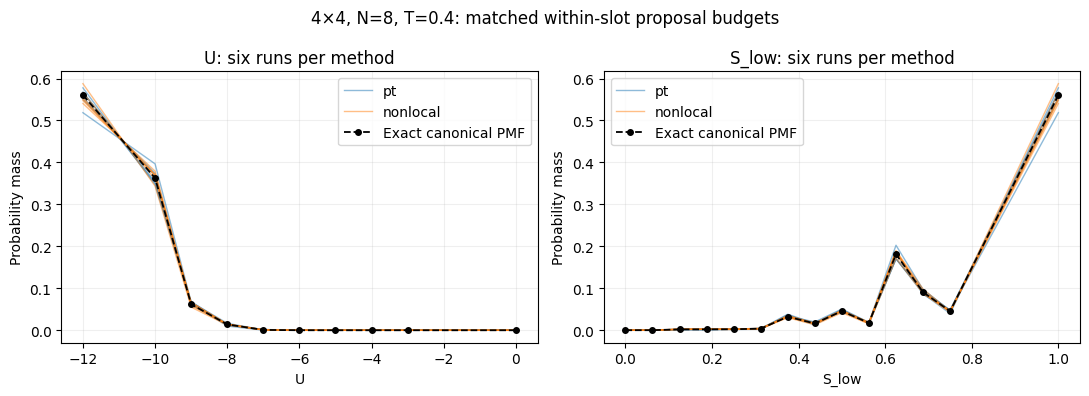

In [58]:
import json
import numpy as np
import matplotlib.pyplot as plt

# ---------- Read the saved configuration and exact reference ----------
with open(pt_validation_dir / "config.json", encoding="utf-8") as f:
    pt_assess_config = json.load(f)

with np.load(pt_validation_dir / "exact_reference.npz") as data:
    pt_assess_exact = {
        name: data[name].copy()
        for name in ("U", "S_low", "probabilities")
    }

pt_assess_tolerance = float(
    pt_assess_config["marginal_tv_tolerance"]
)

# Merge numerical representations of the same discrete observable value.
# Samples were obtained from this same exact-state lookup.
pt_assess_support = {}
pt_assess_exact_pmf = {}

for observable in ("U", "S_low"):
    values = np.round(pt_assess_exact[observable], 12)
    support, inverse = np.unique(values, return_inverse=True)
    pmf = np.bincount(
        inverse,
        weights=pt_assess_exact["probabilities"],
        minlength=len(support),
    )
    assert np.isclose(pmf.sum(), 1.0)
    pt_assess_support[observable] = support
    pt_assess_exact_pmf[observable] = pmf


def pt_assess_empirical_pmf(values, support):
    rounded = np.round(values, 12)
    indices = np.searchsorted(support, rounded)
    assert np.all(indices < len(support))
    assert np.array_equal(support[indices], rounded)
    return np.bincount(
        indices, minlength=len(support)
    ).astype(float) / len(values)


def pt_assess_block_sem(values, block_length):
    assert len(values) % block_length == 0
    block_means = values.reshape(-1, block_length).mean(axis=1)
    return float(
        block_means.std(ddof=1) / np.sqrt(len(block_means))
    )


def pt_assess_round_trips(ids_by_slot):
    """Count cold -> hot -> cold trips after each ID's first cold visit."""
    n_slots = ids_by_slot.shape[1]
    positions = np.argsort(ids_by_slot, axis=1)
    counts = []

    for replica in range(n_slots):
        stage = 0
        completed = 0

        for slot in positions[:, replica]:
            if stage == 0 and slot == 0:
                stage = 1
            elif stage == 1 and slot == n_slots - 1:
                stage = 2
            elif stage == 2 and slot == 0:
                completed += 1
                stage = 1

        counts.append(completed)

    return counts


# Diagnostic blocks have matched within-slot proposal budgets.
# Each setting gives 40, 20, or 10 blocks per measurement trace.
pt_assess_blocks = {
    "pt": [125, 250, 500],
    "nonlocal": [500, 1000, 2000],
}

pt_assess_rows = []
pt_assess_movement = []
pt_assess_pmfs = {}
pt_assess_times = {"pt": [], "nonlocal": []}

print("Method   Initial Seed | TV(U)   TV(S_low) | U error   S_low error")

for initial, seed in pt_assess_config["runs"]:
    for method in ("pt", "nonlocal"):
        path = pt_validation_dir / f"{method}_{initial}_seed_{seed}.npz"

        with np.load(path, allow_pickle=False) as data:
            run = {name: data[name].copy() for name in data.files}

        assert int(run["within_slot_proposals"].item()) == 352000
        pt_assess_times[method].append(
            float(run["elapsed_seconds"].item())
        )

        run_rows = {}

        for observable in ("U", "S_low"):
            values = np.asarray(run[observable], dtype=float)
            expected_records = (
                pt_assess_config["pt_measurement"]
                if method == "pt"
                else pt_assess_config["baseline_measurement"]
            )
            assert len(values) == expected_records

            exact_mean = float(
                pt_assess_exact["probabilities"]
                @ pt_assess_exact[observable]
            )
            empirical = pt_assess_empirical_pmf(
                values, pt_assess_support[observable]
            )
            tv = float(
                0.5 * np.abs(
                    empirical - pt_assess_exact_pmf[observable]
                ).sum()
            )
            midpoint = len(values) // 2

            row = {
                "method": method,
                "initial": initial,
                "seed": seed,
                "observable": observable,
                "mean": float(values.mean()),
                "exact_mean": exact_mean,
                "mean_error": float(values.mean() - exact_mean),
                "tv": tv,
                "within_tv_tolerance": bool(tv <= pt_assess_tolerance),
                "block_sem": {
                    str(block): pt_assess_block_sem(values, block)
                    for block in pt_assess_blocks[method]
                },
                "half_change": float(
                    values[midpoint:].mean()
                    - values[:midpoint].mean()
                ),
            }
            pt_assess_rows.append(row)
            run_rows[observable] = row
            pt_assess_pmfs[(method, initial, seed, observable)] = empirical

        print(
            f"{method:8s} {initial:6s} {seed} | "
            f"{run_rows['U']['tv']:.4f}  "
            f"{run_rows['S_low']['tv']:.4f}    | "
            f"{run_rows['U']['mean_error']:+.5f}  "
            f"{run_rows['S_low']['mean_error']:+.5f}"
        )

        if method == "pt":
            attempts = run["swap_attempts_by_phase"]
            accepts = run["swap_accepts_by_phase"]
            assert int(attempts.sum()) == 16500

            pt_assess_movement.append({
                "initial": initial,
                "seed": seed,
                "measurement_exchange_acceptance": (
                    accepts[1] / attempts[1]
                ).tolist(),
                "cold_hot_cold_round_trips_by_id": pt_assess_round_trips(
                    run["replica_ids_by_slot"]
                ),
                "round_trip_interval": "Full run, including burn-in.",
            })


# ---------- Apply the frozen marginal-accuracy screen ----------
pt_assess_aggregate = {}

for method in ("pt", "nonlocal"):
    pt_assess_aggregate[method] = {
        "total_elapsed_seconds": float(sum(pt_assess_times[method]))
    }

    for observable in ("U", "S_low"):
        distances = np.array([
            row["tv"] for row in pt_assess_rows
            if row["method"] == method
            and row["observable"] == observable
        ])
        assert len(distances) == 6
        pt_assess_aggregate[method][observable] = {
            "median_tv": float(np.median(distances)),
            "max_tv": float(distances.max()),
            "runs_within_tolerance": int(
                np.count_nonzero(distances <= pt_assess_tolerance)
            ),
        }

pt_assess_pass = all(
    row["within_tv_tolerance"]
    for row in pt_assess_rows
    if row["method"] == "pt"
)

pt_assess_report = {
    "config": pt_assess_config,
    "pmf_rounding_decimals": 12,
    "diagnostic_block_lengths": pt_assess_blocks,
    "per_run_observables": pt_assess_rows,
    "aggregate": pt_assess_aggregate,
    "replica_movement": pt_assess_movement,
    "pt_marginal_accuracy_screen_passed": pt_assess_pass,
    "decision": (
        "FIXED_BUDGET_MARGINAL_ACCURACY_SCREEN_PASSED"
        if pt_assess_pass
        else "FIXED_BUDGET_MARGINAL_ACCURACY_SCREEN_NOT_MET"
    ),
    "limitations": [
        "The screen concerns only U and S_low marginal distributions.",
        "Block SEM values are diagnostics, not certified error bounds.",
        "Round trips do not establish independent equilibrium samples.",
        "Recorded times include observations and implementation checks.",
        "No full-configuration or 20x20 qualification is made.",
    ],
    "stopping": "Fixed-budget experiment complete; no automatic extension.",
}

(pt_validation_dir / "accuracy_assessment.json").write_text(
    json.dumps(pt_assess_report, indent=2, allow_nan=False),
    encoding="utf-8",
)

print("\nAggregate TV distances:")
for method, summary in pt_assess_aggregate.items():
    for observable in ("U", "S_low"):
        result = summary[observable]
        print(
            f"{method:8s} {observable:5s} | "
            f"median={result['median_tv']:.4f} | "
            f"max={result['max_tv']:.4f} | "
            f"within tolerance={result['runs_within_tolerance']}/6"
        )

print("\nDecision:", pt_assess_report["decision"])
print("Saved:", pt_validation_dir / "accuracy_assessment.json")


# ---------- Show all individual marginal PMFs ----------
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, observable in zip(axes, ("U", "S_low")):
    support = pt_assess_support[observable]

    for method, color in (("pt", "tab:blue"), ("nonlocal", "tab:orange")):
        for index, (initial, seed) in enumerate(pt_assess_config["runs"]):
            ax.plot(
                support,
                pt_assess_pmfs[(method, initial, seed, observable)],
                color=color, alpha=0.5, linewidth=1,
                label=method if index == 0 else None,
            )

    ax.plot(
        support, pt_assess_exact_pmf[observable],
        "ko--", markersize=4, linewidth=1.3,
        label="Exact canonical PMF",
    )
    ax.set(
        xlabel=observable,
        ylabel="Probability mass",
        title=f"{observable}: six runs per method",
    )
    ax.legend()
    ax.grid(alpha=0.2)

fig.suptitle("4×4, N=8, T=0.4: matched within-slot proposal budgets")
fig.tight_layout()
fig.savefig(pt_validation_dir / "marginal_pmf_comparison.png", dpi=180)
plt.show()

### Decision

PT passed the prespecified marginal-accuracy screen: all six runs
had TV ≤ 0.05 for both U and S_low against the exact 4×4 reference.

The single-temperature nonlocal baseline also passed in all six runs.
At matched within-slot proposal budgets, it had lower median and
maximum TV for both observables. This experiment therefore provides
no evidence of a PT accuracy or efficiency advantage.

The result supports bounded small-system marginal sampling accuracy.
It does not establish full-configuration accuracy or qualify sampling
on the 20×20 lattice.

The fixed-budget validation is complete. No extension or retuning is
performed as part of this task.

## 20×20 PT Transport Pilot

### Question and scope

Can replicas complete repeated cold–hot–cold round trips within a
fixed 2,000-cycle budget using the proposed temperature ladder?

This is a transport diagnostic, not an equilibrium qualification or
an efficiency comparison.

### Fixed settings

- Periodic 20×20 lattice; N = 200; epsilon = 1.
- Temperatures: [0.40, 0.45, 0.50, 0.60, 0.80, 1.00].
- One nonlocal sweep per temperature slot per cycle.
- Even and odd adjacent-temperature exchange stages after each cycle.
- Three independent ensembles:
  random (seed 1242), vertical stripe (1243), horizontal stripe (1244).
- Random starts are independently generated across temperature slots.
- Stripe starts use independent array copies of the same stripe.
- Exactly 2,000 cycles per ensemble; no automatic extension or tuning.

### Diagnostics and interpretation

Record energies at every temperature, replica IDs by slot, accepted
exchanges on each adjacent edge, and target-slot U, S_low, and D.

Count cold–hot–cold round trips separately for each replica, beginning
at its first visit to the cold slot. Zero means no completed round
trip was observed; one is a single trip; two or more are repeated
trips within this pilot. Report all replicas, including zero counts.

All cycles, including the initial transient, enter these transport
diagnostics. No equilibrium averages are estimated.

Round trips do not establish decorrelation, morphology mixing, or
correct target-temperature sampling. The existing provisional
reference remains unchanged.

In [59]:
from pathlib import Path
from datetime import datetime
import json
import time
import numpy as np

pt20_pilot_config = {
    "L": 20,
    "N": 200,
    "epsilon": 1.0,
    "temperatures": [0.40, 0.45, 0.50, 0.60, 0.80, 1.00],
    "cycles": 2000,
    "runs": [
        ["random", 1242],
        ["vertical", 1243],
        ["horizontal", 1244],
    ],
    "rng_streams": {"initialization": 0, "updates": 1},
    "snapshot_interval": 100,
    "energy_check_interval": 100,
    "scope": "Transport pilot; all cycles include the initial transient.",
    "stopping": "Stop at the fixed budget; no automatic tuning or extension.",
}

assert callable(replica_exchange_cycle)
assert callable(pt_assess_round_trips)

pt20_pilot_dir = (
    Path("results")
    / f"pt_transport_20x20_{datetime.now():%Y%m%d_%H%M%S_%f}"
)
pt20_pilot_dir.mkdir(parents=True, exist_ok=False)
(pt20_pilot_dir / "config.json").write_text(
    json.dumps(pt20_pilot_config, indent=2),
    encoding="utf-8",
)


def pt20_pilot_initial(kind, rng):
    state = np.zeros((20, 20), dtype=np.int64)

    if kind == "vertical":
        state[:, :10] = 1
    elif kind == "horizontal":
        state[:10, :] = 1
    elif kind == "random":
        flat = state.ravel()
        flat[:200] = 1
        rng.shuffle(flat)
    else:
        raise ValueError(f"Unknown initialization: {kind}")

    return state


def pt20_pilot_structure(state):
    fluctuations = state.astype(float) - state.mean()
    spectrum = np.abs(np.fft.fft2(fluctuations))**2 / state.size
    s0 = float((spectrum[1, 0] + spectrum[-1, 0]) / 2)
    s1 = float((spectrum[0, 1] + spectrum[0, -1]) / 2)
    return (s0 + s1) / 2, s0 - s1


def pt20_pilot_run(kind, seed):
    cfg = pt20_pilot_config
    temperatures = np.array(cfg["temperatures"])
    n_slots = len(temperatures)
    cycles = cfg["cycles"]

    init_rng = np.random.default_rng(
        np.random.SeedSequence([seed, 0])
    )
    rng = np.random.default_rng(
        np.random.SeedSequence([seed, 1])
    )
    states = [
        pt20_pilot_initial(kind, init_rng)
        for _ in range(n_slots)
    ]
    initial_states = np.stack(states)
    rng_start = json.dumps(rng.bit_generator.state)

    energies = np.array([
        lattice_energy(state, epsilon=1.0, mu=0.0)
        for state in states
    ])
    ids = np.arange(n_slots)

    energy_history = np.empty((cycles + 1, n_slots))
    id_history = np.empty((cycles + 1, n_slots), dtype=np.int64)
    structure_history = np.empty((cycles + 1, 2))
    accepted_history = np.zeros((cycles, n_slots - 1), dtype=bool)

    energy_history[0] = energies
    id_history[0] = ids
    structure_history[0] = pt20_pilot_structure(states[0])

    snapshot_cycles = [0]
    # Save cold and hot configurations for later visual inspection.
    endpoint_snapshots = [
        np.stack([states[0], states[-1]]).astype(np.int8)
    ]
    started = time.perf_counter()

    for cycle in range(1, cycles + 1):
        accepted_history[cycle - 1] = replica_exchange_cycle(
            states, energies, ids, temperatures, rng,
            epsilon=cfg["epsilon"],
        )

        energy_history[cycle] = energies
        id_history[cycle] = ids
        structure_history[cycle] = pt20_pilot_structure(states[0])

        if cycle % cfg["energy_check_interval"] == 0:
            assert np.array_equal(temperatures, cfg["temperatures"])
            assert np.array_equal(np.sort(ids), np.arange(n_slots))

            for state, tracked_u in zip(states, energies):
                assert int(state.sum()) == cfg["N"]
                assert np.isin(state, [0, 1]).all()
                direct_u = lattice_energy(
                    state, epsilon=cfg["epsilon"], mu=0.0
                )
                assert np.isclose(
                    tracked_u, direct_u, rtol=0, atol=1e-12
                )

            for a in range(n_slots):
                for b in range(a + 1, n_slots):
                    assert not np.shares_memory(states[a], states[b])

        if cycle % cfg["snapshot_interval"] == 0:
            snapshot_cycles.append(cycle)
            endpoint_snapshots.append(
                np.stack([states[0], states[-1]]).astype(np.int8)
            )

        if cycle % 500 == 0:
            print(
                f"{kind:10s} seed={seed} | {cycle}/{cycles} | "
                f"cold U={energies[0]:.0f} | "
                f"cold D={structure_history[cycle, 1]:+.2f}",
                flush=True,
            )

    return {
        "initial": kind,
        "seed": seed,
        "temperatures": temperatures,
        "cycles": np.arange(cycles + 1),
        "energy_by_slot": energy_history,
        "replica_ids_by_slot": id_history,
        "target_U": energy_history[:, 0].copy(),
        "target_S_low": structure_history[:, 0],
        "target_D": structure_history[:, 1],
        "exchange_accepted": accepted_history,
        "snapshot_cycles": np.array(snapshot_cycles),
        "endpoint_snapshot_slots": np.array([0, n_slots - 1]),
        "endpoint_snapshots": np.stack(endpoint_snapshots),
        "initial_states": initial_states,
        "final_states": np.stack(states),
        "rng_state_start_json": rng_start,
        "rng_state_end_json": json.dumps(rng.bit_generator.state),
        "within_slot_proposals": cycles * n_slots * 400,
        "replica_exchange_attempts": cycles * (n_slots - 1),
        "elapsed_seconds": time.perf_counter() - started,
    }


pt20_pilot_runs = {}
pt20_pilot_summary = []

for kind, seed in pt20_pilot_config["runs"]:
    run = pt20_pilot_run(kind, seed)
    pt20_pilot_runs[(kind, seed)] = run

    # Save each completed ensemble immediately.
    np.savez_compressed(
        pt20_pilot_dir / f"{kind}_seed_{seed}.npz",
        **run,
    )

    summary = {
        "initial": kind,
        "seed": seed,
        "exchange_acceptance_by_edge": (
            run["exchange_accepted"].mean(axis=0).tolist()
        ),
        "cold_hot_cold_round_trips_by_id": pt_assess_round_trips(
            run["replica_ids_by_slot"]
        ),
        "elapsed_seconds": float(run["elapsed_seconds"]),
    }
    pt20_pilot_summary.append(summary)

    print("Acceptance by adjacent edge:",
          np.round(summary["exchange_acceptance_by_edge"], 3))
    print("Completed round trips by replica ID:",
          summary["cold_hot_cold_round_trips_by_id"])
    print()

assert sum(
    run["within_slot_proposals"]
    for run in pt20_pilot_runs.values()
) == 14_400_000
assert sum(
    run["replica_exchange_attempts"]
    for run in pt20_pilot_runs.values()
) == 30_000

(pt20_pilot_dir / "transport_summary.json").write_text(
    json.dumps(pt20_pilot_summary, indent=2, allow_nan=False),
    encoding="utf-8",
)

print("Fixed-budget transport pilot complete.")
print("PASS: recorded conservation, energy, and budget checks.")
print("Transport interpretation pending; no equilibrium qualification.")
print("Saved to:", pt20_pilot_dir.resolve())

random     seed=1242 | 500/2000 | cold U=-360 | cold D=-33.84
random     seed=1242 | 1000/2000 | cold U=-357 | cold D=-24.76
random     seed=1242 | 1500/2000 | cold U=-365 | cold D=+34.72
random     seed=1242 | 2000/2000 | cold U=-364 | cold D=-36.16
Acceptance by adjacent edge: [0.245 0.25  0.036 0.006 0.123]
Completed round trips by replica ID: [0, 1, 0, 0, 0, 0]

vertical   seed=1243 | 500/2000 | cold U=-362 | cold D=-34.83
vertical   seed=1243 | 1000/2000 | cold U=-363 | cold D=-33.20
vertical   seed=1243 | 1500/2000 | cold U=-363 | cold D=-32.60
vertical   seed=1243 | 2000/2000 | cold U=-364 | cold D=+27.45
Acceptance by adjacent edge: [0.285 0.244 0.022 0.006 0.134]
Completed round trips by replica ID: [0, 0, 0, 0, 0, 0]

horizontal seed=1244 | 500/2000 | cold U=-363 | cold D=+34.94
horizontal seed=1244 | 1000/2000 | cold U=-362 | cold D=+35.78
horizontal seed=1244 | 1500/2000 | cold U=-367 | cold D=+33.95
horizontal seed=1244 | 2000/2000 | cold U=-363 | cold D=-32.59
Acceptance 

### Pilot decision

The proposed temperature ladder showed limited end-to-end transport
within the fixed 2,000-cycle budget.

The lowest observed exchange acceptance was on the 0.60–0.80 edge
(0.4–0.6%), followed by the 0.50–0.60 edge (2.2–3.6%).

The random, vertical, and horizontal ensembles completed 1, 0, and 1
cold–hot–cold round trips, respectively. No replica completed repeated
round trips.

This pilot does not support proceeding directly to a long production
run with the current ladder. It does not establish that PT is
ineffective in general.

The pilot is complete. Existing references remain unchanged.
Saved energy traces can be inspected to inform a separately designed
ladder revision; no automatic extension or retuning is performed.

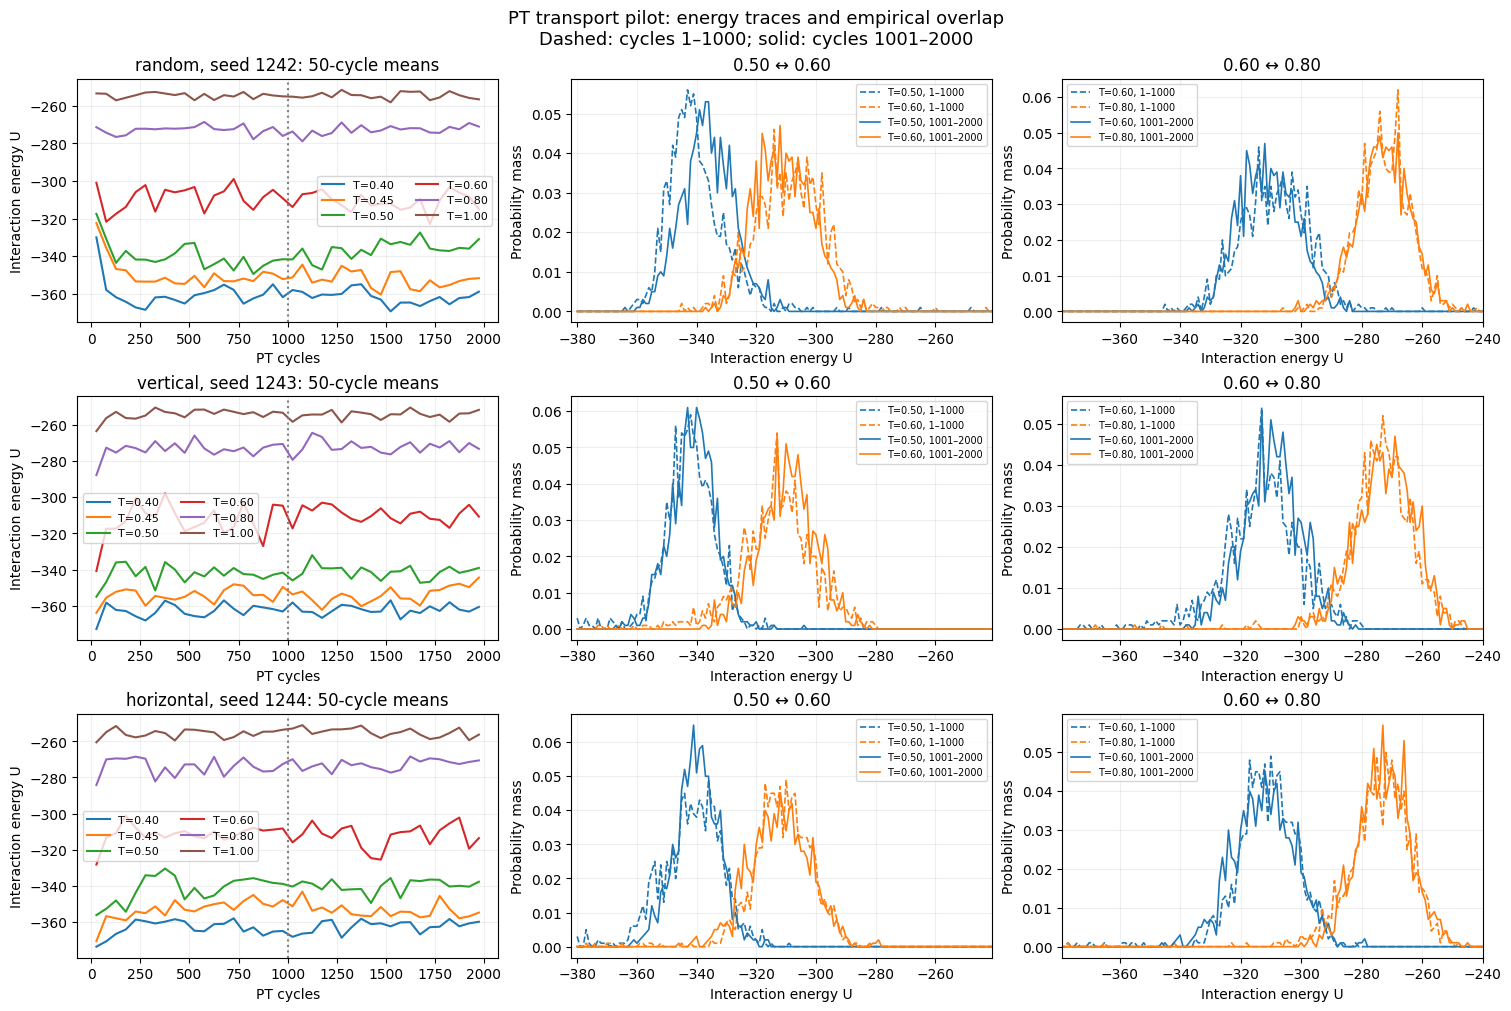

Initial    Pair         Window       Overlap  Accepted / Attempts
random     0.50-0.60     1-1000   0.1250     35 / 1000
random     0.50-0.60  1001-2000   0.1410     38 / 1000
random     0.60-0.80     1-1000   0.0550      8 / 1000
random     0.60-0.80  1001-2000   0.0350      3 / 1000
vertical   0.50-0.60     1-1000   0.1210     24 / 1000
vertical   0.50-0.60  1001-2000   0.0600     21 / 1000
vertical   0.60-0.80     1-1000   0.0650      4 / 1000
vertical   0.60-0.80  1001-2000   0.0440      9 / 1000
horizontal 0.50-0.60     1-1000   0.0860     25 / 1000
horizontal 0.50-0.60  1001-2000   0.0910     26 / 1000
horizontal 0.60-0.80     1-1000   0.0560      8 / 1000
horizontal 0.60-0.80  1001-2000   0.0300      1 / 1000

Saved diagnostic figures and numerical summaries.
No additional simulation was performed.


In [60]:
import json
import numpy as np
import matplotlib.pyplot as plt

with open(pt20_pilot_dir / "config.json", encoding="utf-8") as f:
    energy_diag_config = json.load(f)

energy_diag_runs = {}

for kind, seed in energy_diag_config["runs"]:
    with np.load(
        pt20_pilot_dir / f"{kind}_seed_{seed}.npz",
        allow_pickle=False,
    ) as data:
        energy_diag_runs[(kind, seed)] = {
            name: data[name].copy()
            for name in (
                "cycles", "temperatures",
                "energy_by_slot", "exchange_accepted",
            )
        }

energy_diag_windows = [(1, 1000), (1001, 2000)]
energy_diag_pairs = [(0.50, 0.60), (0.60, 0.80)]

# Shared unit-width bins for the integer-valued interaction energy.
all_energies = np.concatenate([
    run["energy_by_slot"][1:].ravel()
    for run in energy_diag_runs.values()
])
energy_diag_edges = np.arange(
    np.floor(all_energies.min()) - 0.5,
    np.ceil(all_energies.max()) + 1.5,
    1.0,
)
energy_diag_centers = (
    energy_diag_edges[:-1] + energy_diag_edges[1:]
) / 2


def energy_diag_pmf(values):
    counts, _ = np.histogram(values, bins=energy_diag_edges)
    assert counts.sum() == len(values)
    return counts / counts.sum()


energy_diag_rows = []

fig, axes = plt.subplots(
    3, 3, figsize=(15, 10), layout="constrained"
)

for row, ((kind, seed), run) in enumerate(energy_diag_runs.items()):
    cycles = run["cycles"]
    temperatures = run["temperatures"]
    energies = run["energy_by_slot"]
    accepted = run["exchange_accepted"]

    assert np.array_equal(cycles, np.arange(2001))
    assert energies.shape == (2001, len(temperatures))

    # Left column: 50-cycle means, for readability only.
    block = 50
    block_times = cycles[1:].reshape(-1, block).mean(axis=1)

    for slot, temperature in enumerate(temperatures):
        block_u = energies[1:, slot].reshape(-1, block).mean(axis=1)
        axes[row, 0].plot(
            block_times, block_u,
            label=f"T={temperature:.2f}",
        )

    axes[row, 0].axvline(1000.5, color="grey", linestyle=":")
    axes[row, 0].set(
        title=f"{kind}, seed {seed}: 50-cycle means",
        xlabel="PT cycles",
        ylabel="Interaction energy U",
    )
    axes[row, 0].legend(fontsize=8, ncol=2)
    axes[row, 0].grid(alpha=0.2)

    # Other columns: adjacent-slot empirical energy distributions.
    for col, (ta, tb) in enumerate(energy_diag_pairs, start=1):
        a = int(np.flatnonzero(np.isclose(temperatures, ta))[0])
        b = int(np.flatnonzero(np.isclose(temperatures, tb))[0])
        assert b == a + 1

        ax = axes[row, col]

        for window_index, (start, end) in enumerate(energy_diag_windows):
            mask = (cycles >= start) & (cycles <= end)
            ua = energies[mask, a]
            ub = energies[mask, b]
            pa = energy_diag_pmf(ua)
            pb = energy_diag_pmf(ub)

            # Empirical histogram overlap, between 0 and 1.
            overlap = float(np.minimum(pa, pb).sum())

            # Acceptance was recorded once per edge per cycle.
            exchange_count = int(accepted[start - 1:end, a].sum())
            attempts = end - start + 1

            energy_diag_rows.append({
                "initial": kind,
                "seed": seed,
                "temperature_pair": [ta, tb],
                "window": [start, end],
                "mean_U": [float(ua.mean()), float(ub.mean())],
                "empirical_energy_overlap": overlap,
                "accepted_exchanges": exchange_count,
                "attempted_exchanges": attempts,
                "exchange_acceptance": exchange_count / attempts,
            })

            linestyle = "--" if window_index == 0 else "-"
            for temperature, pmf, color in (
                (ta, pa, "tab:blue"),
                (tb, pb, "tab:orange"),
            ):
                ax.plot(
                    energy_diag_centers, pmf,
                    color=color, linestyle=linestyle,
                    linewidth=1.2,
                    label=f"T={temperature:.2f}, {start}–{end}",
                )

        # Same horizontal range across the three ensembles for this pair.
        pair_values = np.concatenate([
            other["energy_by_slot"][1:, [a, b]].ravel()
            for other in energy_diag_runs.values()
        ])
        ax.set(
            xlim=(pair_values.min() - 2, pair_values.max() + 2),
            xlabel="Interaction energy U",
            ylabel="Probability mass",
            title=f"{ta:.2f} ↔ {tb:.2f}",
        )
        ax.legend(fontsize=7)
        ax.grid(alpha=0.2)

fig.suptitle(
    "PT transport pilot: energy traces and empirical overlap\n"
    "Dashed: cycles 1–1000; solid: cycles 1001–2000",
    fontsize=13,
)
fig.savefig(
    pt20_pilot_dir / "energy_transport_diagnostic.png",
    dpi=180,
)
plt.show()

print("Initial    Pair         Window       Overlap  Accepted / Attempts")
for row in energy_diag_rows:
    ta, tb = row["temperature_pair"]
    start, end = row["window"]
    print(
        f"{row['initial']:10s} "
        f"{ta:.2f}-{tb:.2f}  "
        f"{start:4d}-{end:4d}   "
        f"{row['empirical_energy_overlap']:.4f}   "
        f"{row['accepted_exchanges']:4d} / "
        f"{row['attempted_exchanges']}"
    )

energy_diag_report = {
    "windows": energy_diag_windows,
    "temperature_pairs": energy_diag_pairs,
    "histogram_edges": energy_diag_edges.tolist(),
    "rows": energy_diag_rows,
    "scope": (
        "Post-pilot descriptive analysis of saved data; "
        "no equilibrium or transport qualification threshold."
    ),
    "limitations": [
        "Both windows may contain transient behavior.",
        "Histogram overlap is not the replica-exchange acceptance probability.",
        "Energies were recorded after the complete exchange cycle, "
        "not immediately before each edge proposal.",
    ],
}

(pt20_pilot_dir / "energy_transport_diagnostic.json").write_text(
    json.dumps(energy_diag_report, indent=2, allow_nan=False),
    encoding="utf-8",
)

print("\nSaved diagnostic figures and numerical summaries.")
print("No additional simulation was performed.")

## Revised Temperature-Ladder Transport Pilot

### Question
Does inserting intermediate temperatures improve end-to-end replica
transport at the same total within-slot proposal budget?

### Frozen design
- System: periodic 20×20 lattice, N=200, epsilon=1.
- Temperatures: [0.40, 0.45, 0.50, 0.55, 0.60, 0.70, 0.80, 1.00].
- Budget: 1,500 PT cycles per ensemble.
- Initializations: random, vertical stripe, horizontal stripe.
- Seeds: 1342, 1343, 1344, respectively.
- Update schedule: one nonlocal sweep per temperature slot, followed by
  the existing even/odd adjacent replica-exchange schedule.
- All cycles, including the initial transient, enter transport diagnostics.

The total within-slot proposal budget is 14,400,000, matching the original
six-temperature pilot. The revised pilot has 31,500 replica-exchange
attempts, compared with 30,000 previously. Wall-clock time is reported
separately.

### Primary comparison
Compare total completed cold–hot–cold round trips and the fraction of
replicas completing at least one round trip.

- Both increase: observed transport improvement in this pilot.
- Neither increases: no observed improvement in the primary metrics.
- Otherwise: mixed result.

Also report per-ensemble results, repeated round trips, and acceptance
rates on every adjacent temperature edge.

### Scope and stopping
The candidate ladder was selected using the original pilot diagnostics.
This is an exploratory comparison, not an independent confirmation of
algorithmic superiority or equilibrium accuracy.

Stop after the three fixed-budget runs. Do not automatically extend runs,
change the ladder, or modify the existing provisional reference.

In [61]:
from pathlib import Path
from datetime import datetime
import json
import time
import numpy as np

# Existing notebook functions are reused without modification.
required_functions = (
    "replica_exchange_cycle",
    "lattice_energy",
    "pt20_pilot_initial",
    "pt20_pilot_structure",
    "pt_assess_round_trips",
)
for name in required_functions:
    if not callable(globals().get(name)):
        raise RuntimeError(f"Run the existing definition of {name} first.")

baseline_dir = Path(pt20_pilot_dir)

# Read the original results before starting any new simulation.
baseline_rows = []
baseline_proposals = 0
baseline_exchange_attempts = 0

for initial, seed in (
    ("random", 1242),
    ("vertical", 1243),
    ("horizontal", 1244),
):
    path = baseline_dir / f"{initial}_seed_{seed}.npz"
    with np.load(path, allow_pickle=False) as saved:
        assert np.allclose(
            saved["temperatures"],
            [0.40, 0.45, 0.50, 0.60, 0.80, 1.00],
            rtol=0, atol=1e-12,
        )
        assert np.array_equal(saved["cycles"], np.arange(2001))

        counts = np.asarray(
            pt_assess_round_trips(saved["replica_ids_by_slot"]),
            dtype=int,
        )
        baseline_rows.append({
            "initial": initial,
            "seed": seed,
            "round_trips_by_id": counts.tolist(),
            "elapsed_seconds": float(saved["elapsed_seconds"]),
        })
        baseline_proposals += int(saved["within_slot_proposals"])
        baseline_exchange_attempts += int(saved["replica_exchange_attempts"])

assert baseline_proposals == 14_400_000
assert baseline_exchange_attempts == 30_000

revised_config = {
    "L": 20,
    "N": 200,
    "epsilon": 1.0,
    "temperatures": [0.40, 0.45, 0.50, 0.55, 0.60, 0.70, 0.80, 1.00],
    "cycles": 1500,
    "runs": [
        ["random", 1342],
        ["vertical", 1343],
        ["horizontal", 1344],
    ],
    "rng_streams": {"initialization": 0, "updates": 1},
    "check_interval": 100,
    "snapshot_interval": 100,
    "baseline_directory": str(baseline_dir.resolve()),
    "primary_rule": {
        "improvement": "Both total trips and completion fraction increase.",
        "no_improvement": "Neither primary metric increases.",
        "mixed": "Only one primary metric increases.",
    },
    "scope": "Exploratory transport comparison; no equilibrium qualification.",
    "stopping": "Three fixed-budget runs; no automatic extension or tuning.",
}

revised_dir = baseline_dir.parent / (
    "pt_transport_revised_20x20_"
    + datetime.now().strftime("%Y%m%d_%H%M%S_%f")
)
revised_dir.mkdir(parents=True, exist_ok=False)

# Persist the protocol before generating trajectories.
(revised_dir / "config.json").write_text(
    json.dumps(revised_config, indent=2, allow_nan=False),
    encoding="utf-8",
)


def run_revised_transport(initial, seed, config):
    temperatures = np.asarray(config["temperatures"], dtype=float)
    original_temperatures = temperatures.copy()
    n_slots = len(temperatures)
    n_cycles = config["cycles"]
    n_sites = config["L"] ** 2

    init_rng = np.random.default_rng(np.random.SeedSequence([seed, 0]))
    run_rng = np.random.default_rng(np.random.SeedSequence([seed, 1]))

    states = [
        pt20_pilot_initial(initial, init_rng)
        for _ in range(n_slots)
    ]
    initial_states = np.stack(states).copy()
    energies = np.array([
        lattice_energy(state, epsilon=config["epsilon"], mu=0.0)
        for state in states
    ], dtype=float)
    replica_ids = np.arange(n_slots)

    energy_history = np.empty((n_cycles + 1, n_slots))
    id_history = np.empty((n_cycles + 1, n_slots), dtype=int)
    accepted_history = np.zeros((n_cycles, n_slots - 1), dtype=bool)
    cold_s = np.empty(n_cycles + 1)
    cold_d = np.empty(n_cycles + 1)

    snapshot_cycles = [0]
    endpoint_snapshots = [np.stack([states[0], states[-1]]).copy()]
    rng_start_json = json.dumps(run_rng.bit_generator.state)

    def check_bookkeeping():
        direct = np.array([
            lattice_energy(state, epsilon=config["epsilon"], mu=0.0)
            for state in states
        ])
        assert np.allclose(energies, direct, rtol=0, atol=1e-12)
        assert np.array_equal(temperatures, original_temperatures)
        assert np.array_equal(np.sort(replica_ids), np.arange(n_slots))

        for state in states:
            assert state.shape == (config["L"], config["L"])
            assert int(state.sum()) == config["N"]
            assert np.isin(state, [0, 1]).all()

        for a in range(n_slots):
            for b in range(a + 1, n_slots):
                assert not np.shares_memory(states[a], states[b])

    check_bookkeeping()
    energy_history[0] = energies
    id_history[0] = replica_ids
    cold_s[0], cold_d[0] = pt20_pilot_structure(states[0])

    started = time.perf_counter()

    for cycle in range(1, n_cycles + 1):
        accepted_history[cycle - 1] = replica_exchange_cycle(
            states, energies, replica_ids, temperatures, run_rng,
            epsilon=config["epsilon"],
        )

        # Record fixed temperature slots, including rejected exchanges.
        energy_history[cycle] = energies
        id_history[cycle] = replica_ids
        cold_s[cycle], cold_d[cycle] = pt20_pilot_structure(states[0])

        if cycle % config["check_interval"] == 0 or cycle == n_cycles:
            check_bookkeeping()

        if cycle % config["snapshot_interval"] == 0 or cycle == n_cycles:
            snapshot_cycles.append(cycle)
            endpoint_snapshots.append(
                np.stack([states[0], states[-1]]).copy()
            )

        if cycle % 500 == 0:
            print(
                f"{initial:10s} seed={seed} | {cycle}/{n_cycles} "
                f"| cold U={energies[0]:.0f} | D={cold_d[cycle]:+.2f}",
                flush=True,
            )

    return {
        "initial": initial,
        "seed": seed,
        "temperatures": temperatures.copy(),
        "cycles": np.arange(n_cycles + 1),
        "energy_by_slot": energy_history,
        "replica_ids_by_slot": id_history,
        "target_U": energy_history[:, 0].copy(),
        "target_S_low": cold_s,
        "target_D": cold_d,
        "exchange_accepted": accepted_history,
        "snapshot_cycles": np.asarray(snapshot_cycles),
        "endpoint_snapshot_slots": np.array([0, n_slots - 1]),
        "endpoint_snapshots": np.stack(endpoint_snapshots),
        "initial_states": initial_states,
        "final_states": np.stack(states),
        "rng_state_start_json": rng_start_json,
        "rng_state_end_json": json.dumps(run_rng.bit_generator.state),
        "within_slot_proposals": n_cycles * n_slots * n_sites,
        "replica_exchange_attempts": n_cycles * (n_slots - 1),
        "elapsed_seconds": time.perf_counter() - started,
    }


revised_runs = {}
revised_rows = []

for initial, seed in revised_config["runs"]:
    run = run_revised_transport(initial, seed, revised_config)
    revised_runs[(initial, seed)] = run

    # Save each completed ensemble immediately.
    np.savez_compressed(
        revised_dir / f"{initial}_seed_{seed}.npz", **run
    )

    counts = np.asarray(
        pt_assess_round_trips(run["replica_ids_by_slot"]), dtype=int
    )
    row = {
        "initial": initial,
        "seed": seed,
        "round_trips_by_id": counts.tolist(),
        "acceptance_by_edge": run["exchange_accepted"].mean(axis=0).tolist(),
        "elapsed_seconds": float(run["elapsed_seconds"]),
    }
    revised_rows.append(row)

    print("Round trips by replica ID:", counts.tolist())
    print("Acceptance by edge:", np.round(row["acceptance_by_edge"], 3))
    print()

assert sum(
    run["within_slot_proposals"] for run in revised_runs.values()
) == baseline_proposals
assert sum(
    run["replica_exchange_attempts"] for run in revised_runs.values()
) == 31_500


def summarize_transport(rows):
    counts = np.concatenate([
        np.asarray(row["round_trips_by_id"], dtype=int) for row in rows
    ])
    return {
        "total_round_trips": int(counts.sum()),
        "replicas": int(counts.size),
        "replicas_with_at_least_one_trip": int((counts >= 1).sum()),
        "completion_fraction": float((counts >= 1).mean()),
        "replicas_with_repeated_trips": int((counts >= 2).sum()),
        "total_run_seconds": float(sum(r["elapsed_seconds"] for r in rows)),
    }


baseline_summary = summarize_transport(baseline_rows)
revised_summary = summarize_transport(revised_rows)

more_trips = (
    revised_summary["total_round_trips"]
    > baseline_summary["total_round_trips"]
)
higher_fraction = (
    revised_summary["completion_fraction"]
    > baseline_summary["completion_fraction"]
)

if more_trips and higher_fraction:
    decision = "OBSERVED_TRANSPORT_IMPROVEMENT_IN_THIS_PILOT"
elif not more_trips and not higher_fraction:
    decision = "NO_OBSERVED_IMPROVEMENT_IN_PRIMARY_METRICS"
else:
    decision = "MIXED_TRANSPORT_RESULT"

comparison = {
    "baseline": baseline_summary,
    "revised": revised_summary,
    "baseline_runs": baseline_rows,
    "revised_runs": revised_rows,
    "decision": decision,
    "scope": revised_config["scope"],
}

(revised_dir / "transport_comparison.json").write_text(
    json.dumps(comparison, indent=2, allow_nan=False),
    encoding="utf-8",
)

print("Baseline:", json.dumps(baseline_summary, indent=2))
print("Revised:", json.dumps(revised_summary, indent=2))
print("\nDecision:", decision)
print("Fixed-budget pilot complete. No automatic continuation.")
print("Transport comparison only; equilibrium accuracy is not assessed.")
print("Saved to:", revised_dir.resolve())

random     seed=1342 | 500/1500 | cold U=-357 | D=+32.55
random     seed=1342 | 1000/1500 | cold U=-354 | D=+30.14
random     seed=1342 | 1500/1500 | cold U=-362 | D=-33.65
Round trips by replica ID: [1, 1, 0, 0, 0, 0, 1, 0]
Acceptance by edge: [0.288 0.199 0.308 0.26  0.129 0.239 0.139]

vertical   seed=1343 | 500/1500 | cold U=-356 | D=-29.39
vertical   seed=1343 | 1000/1500 | cold U=-356 | D=-29.14
vertical   seed=1343 | 1500/1500 | cold U=-359 | D=-27.72
Round trips by replica ID: [1, 0, 0, 0, 0, 0, 0, 0]
Acceptance by edge: [0.315 0.291 0.222 0.328 0.082 0.256 0.108]

horizontal seed=1344 | 500/1500 | cold U=-361 | D=+30.21
horizontal seed=1344 | 1000/1500 | cold U=-352 | D=+29.26
horizontal seed=1344 | 1500/1500 | cold U=-360 | D=+35.68
Round trips by replica ID: [0, 0, 0, 0, 0, 0, 0, 0]
Acceptance by edge: [0.307 0.235 0.267 0.272 0.12  0.212 0.125]

Baseline: {
  "total_round_trips": 2,
  "replicas": 18,
  "replicas_with_at_least_one_trip": 2,
  "completion_fraction": 0.1111111

### Decision: observed but limited transport improvement

At the matched within-slot proposal budget, the revised ladder produced
4 completed round trips, compared with 2 for the original ladder.
The fraction of replicas completing at least one round trip increased
from 2/18 (11.1%) to 4/24 (16.7%).

Both prespecified primary metrics improved. However, no replica completed
two round trips, and the revised horizontal-initialization ensemble
completed none. Improvement was therefore uneven across ensembles.

These results support retaining the revised ladder as a candidate for
further evaluation. They do not establish robust transport efficiency,
equilibrium sampling accuracy, or full-configuration reference validity.

The bounded pilot is complete. No automatic continuation is performed.
The existing provisional observable-mean reference remains unchanged.

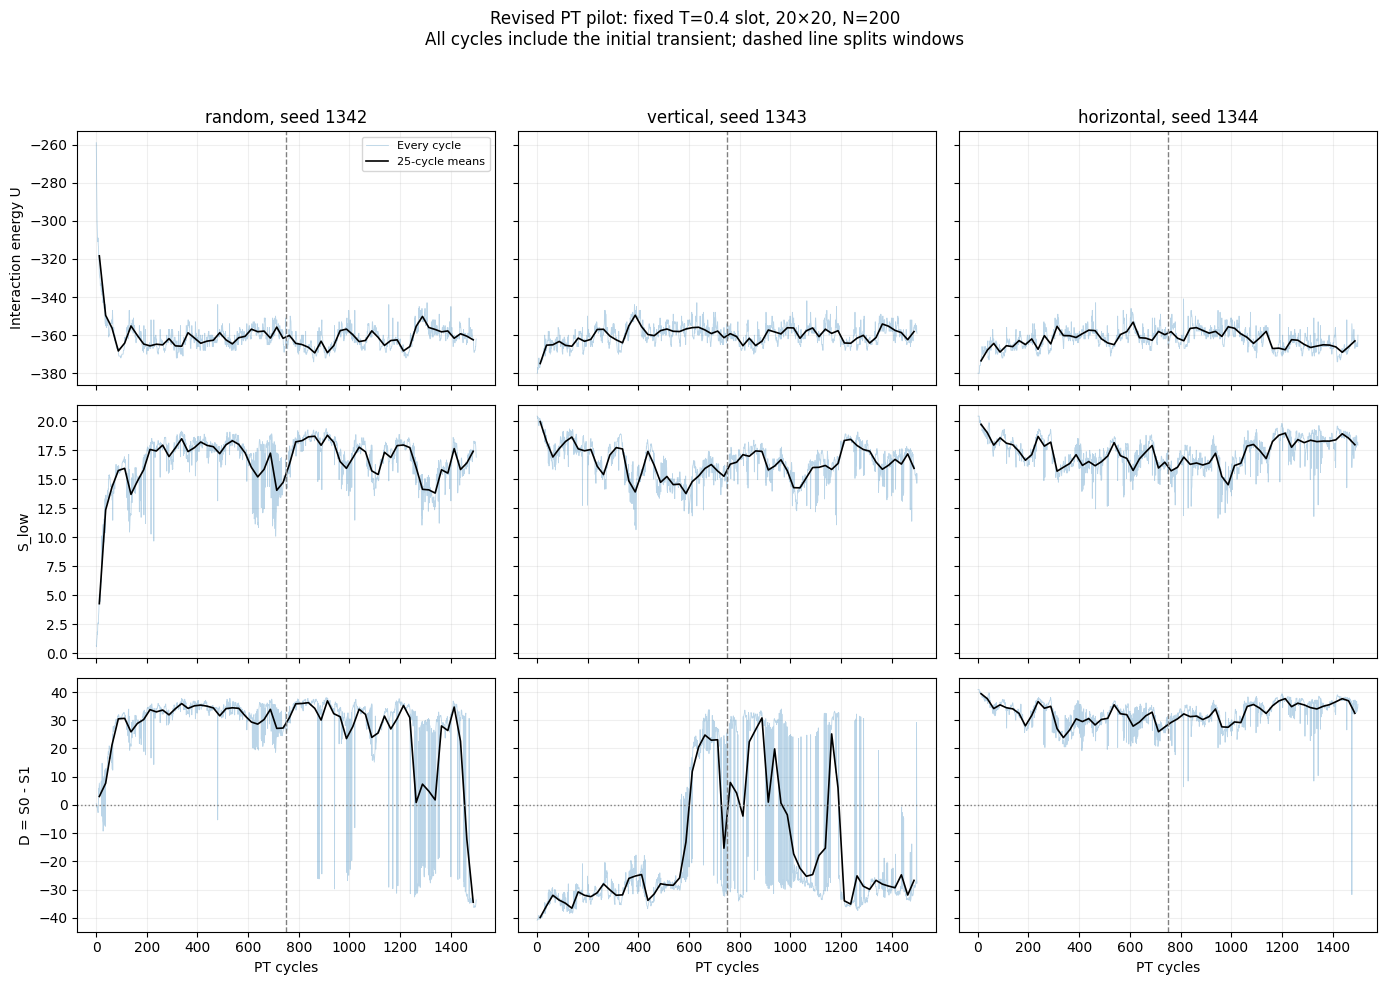

Descriptive window statistics; no equilibrium PASS/FAIL.
Initial    Seed | Window    | Mean U   | Mean S | Mean D | P(D>0) | P(D<0) | IDs
random     1342 |    1- 750 | -359.864 | 16.130 | +29.90 |  0.979 |  0.021 |  6
random     1342 |  751-1500 | -361.537 | 16.834 | +23.52 |  0.855 |  0.145 |  3
vertical   1343 |    1- 750 | -360.099 | 16.338 | -21.30 |  0.181 |  0.819 |  7
vertical   1343 |  751-1500 | -359.839 | 16.480 | -11.18 |  0.313 |  0.687 |  5
horizontal 1344 |    1- 750 | -362.183 | 17.230 | +31.53 |  1.000 |  0.000 |  5
horizontal 1344 |  751-1500 | -362.179 | 17.362 | +33.33 |  0.999 |  0.001 |  4

No additional simulation was performed.
Saved to: C:\Users\user\Documents\GitHub\active-matter-reproductions\lattice-gas\results\pt_transport_revised_20x20_20261103_210052_966786\cold_slot_diagnostic_20261103_210138_604764


In [62]:
from pathlib import Path
from datetime import datetime
import json
import numpy as np
import matplotlib.pyplot as plt

# Use the revised pilot directory from the preceding experiment.
source_dir = Path(revised_dir)

with (source_dir / "config.json").open(encoding="utf-8") as handle:
    cold_diag_config = json.load(handle)

cold_diag_dir = source_dir / (
    "cold_slot_diagnostic_"
    + datetime.now().strftime("%Y%m%d_%H%M%S_%f")
)
cold_diag_dir.mkdir(exist_ok=False)

windows = [(1, 750), (751, 1500)]
block_cycles = 25
observables = ("target_U", "target_S_low", "target_D")
axis_labels = ("Interaction energy U", "S_low", "D = S0 - S1")

cold_diag_runs = {}
cold_diag_rows = []

# Read existing trajectories only.
for initial, seed in cold_diag_config["runs"]:
    path = source_dir / f"{initial}_seed_{seed}.npz"

    with np.load(path, allow_pickle=False) as saved:
        run = {
            key: saved[key].copy()
            for key in (
                "cycles", "temperatures", "energy_by_slot",
                "replica_ids_by_slot", *observables,
            )
        }

    cycles = run["cycles"]
    assert np.array_equal(cycles, np.arange(1501))
    assert np.isclose(run["temperatures"][0], 0.4)
    assert np.allclose(
        run["target_U"], run["energy_by_slot"][:, 0],
        rtol=0, atol=1e-12,
    )

    n_slots = len(run["temperatures"])
    assert np.array_equal(
        np.sort(run["replica_ids_by_slot"], axis=1),
        np.broadcast_to(np.arange(n_slots), (len(cycles), n_slots)),
    )

    for key in observables:
        assert run[key].shape == cycles.shape
        assert np.isfinite(run[key]).all()

    cold_diag_runs[(initial, seed)] = run

    for start, end in windows:
        mask = (cycles >= start) & (cycles <= end)
        d_values = run["target_D"][mask]
        ids = run["replica_ids_by_slot"][mask, 0]
        assert int(mask.sum()) == 750

        row = {
            "initial": initial,
            "seed": seed,
            "window_start": start,
            "window_end": end,
            "records": int(mask.sum()),
            "mean_U": float(run["target_U"][mask].mean()),
            "mean_S_low": float(run["target_S_low"][mask].mean()),
            "mean_D": float(d_values.mean()),
            "fraction_D_positive": float(np.mean(d_values > 0)),
            "fraction_D_negative": float(np.mean(d_values < 0)),
            "fraction_D_zero": float(np.mean(d_values == 0)),
            "distinct_replica_ids_at_cold_slot": int(np.unique(ids).size),
        }
        cold_diag_rows.append(row)

# Columns: initializations. Rows: observables.
fig, axes = plt.subplots(
    3, 3, figsize=(14, 10),
    sharex=True, sharey="row",
)

for column, ((initial, seed), run) in enumerate(cold_diag_runs.items()):
    cycles = run["cycles"][1:]

    for row_index, (key, label) in enumerate(
        zip(observables, axis_labels)
    ):
        ax = axes[row_index, column]
        values = run[key][1:]

        # Raw records preserve short excursions and sign changes.
        ax.plot(
            cycles, values,
            color="tab:blue", alpha=0.30, linewidth=0.6,
            label="Every cycle",
        )

        # Block means are for visualization, not independent samples.
        block_x = cycles.reshape(-1, block_cycles).mean(axis=1)
        block_y = values.reshape(-1, block_cycles).mean(axis=1)
        ax.plot(
            block_x, block_y,
            color="black", linewidth=1.2,
            label=f"{block_cycles}-cycle means",
        )

        ax.axvline(750.5, color="gray", linestyle="--", linewidth=1)
        if key == "target_D":
            ax.axhline(0, color="gray", linestyle=":", linewidth=1)

        if row_index == 0:
            ax.set_title(f"{initial}, seed {seed}")
        if column == 0:
            ax.set_ylabel(label)
        if row_index == 2:
            ax.set_xlabel("PT cycles")

        ax.grid(alpha=0.2)

axes[0, 0].legend(fontsize=8)
fig.suptitle(
    "Revised PT pilot: fixed T=0.4 slot, 20×20, N=200\n"
    "All cycles include the initial transient; dashed line splits windows"
)
fig.tight_layout(rect=(0, 0, 1, 0.95))
fig.savefig(cold_diag_dir / "cold_slot_traces.png", dpi=180)
plt.show()

print("Descriptive window statistics; no equilibrium PASS/FAIL.")
print(
    "Initial    Seed | Window    | Mean U   | Mean S | Mean D "
    "| P(D>0) | P(D<0) | IDs"
)

for row in cold_diag_rows:
    print(
        f"{row['initial']:10s} {row['seed']} | "
        f"{row['window_start']:4d}-{row['window_end']:4d} | "
        f"{row['mean_U']:8.3f} | "
        f"{row['mean_S_low']:6.3f} | "
        f"{row['mean_D']:+6.2f} | "
        f"{row['fraction_D_positive']:6.3f} | "
        f"{row['fraction_D_negative']:6.3f} | "
        f"{row['distinct_replica_ids_at_cold_slot']:2d}"
    )

report = {
    "source_directory": str(source_dir.resolve()),
    "temperature": 0.4,
    "windows": windows,
    "plot_block_cycles": block_cycles,
    "rows": cold_diag_rows,
    "scope": "Descriptive cold-slot diagnostic; no new simulation.",
    "limitations": [
        "All cycles include the initial transient; burn-in is not established.",
        "One ensemble per initialization cannot isolate initialization effects.",
        "Records and plotting blocks are not assumed independent.",
        "Replica-ID coverage does not establish configuration mixing.",
        "A cold-slot D sign change can result from replica exchange.",
        "These diagnostics do not qualify the joint equilibrium distribution.",
    ],
}

(cold_diag_dir / "cold_slot_summary.json").write_text(
    json.dumps(report, indent=2, allow_nan=False),
    encoding="utf-8",
)

print("\nNo additional simulation was performed.")
print("Saved to:", cold_diag_dir.resolve())

In [63]:
from pathlib import Path
from datetime import datetime
import json
import time
import numpy as np

# Reuse the previously checked update functions.
for name in (
    "replica_exchange_cycle",
    "lattice_energy",
    "pt20_pilot_initial",
    "pt20_pilot_structure",
):
    if not callable(globals().get(name)):
        raise RuntimeError(f"Run the existing definition of {name} first.")

pt20_reference_config = {
    "experiment": "PT20_FIXED_BUDGET_REFERENCE_CANDIDATE_V1",
    "L": 20,
    "N": 200,
    "epsilon": 1.0,
    "temperatures": [0.40, 0.45, 0.50, 0.55, 0.60, 0.70, 0.80, 1.00],
    "runs": [
        ["random", 1442],
        ["random", 1443],
        ["random", 1444],
        ["vertical", 1445],
        ["vertical", 1446],
        ["vertical", 1447],
        ["horizontal", 1448],
        ["horizontal", 1449],
        ["horizontal", 1450],
    ],
    "cycles_per_run": 25_000,
    "initial_exclusion": 5_000,
    "measurement_windows": [[5001, 15000], [15001, 25000]],
    "checkpoint_cycles": 5_000,
    "check_interval": 100,
    "cold_snapshot_interval": 100,
    "rng_streams": {"initialization": 0, "updates": 1},
    "schedule": "One nonlocal sweep per slot, then even/odd exchanges.",
    "analysis": {
        "block_lengths_cycles": [500, 1000, 2000],
        "q_definition": "I(D>0) + 0.5*I(D==0)",
        "mean_screens": {
            "U": {
                "max_chain_range": 1.0,
                "max_window_change": 1.0,
                "max_block_sem": 0.25,
            },
            "S_low": {
                "max_chain_range": 0.5,
                "max_window_change": 0.5,
                "max_block_sem": 0.125,
            },
            "q": {
                "max_distance_from_half_per_chain": 0.10,
                "max_window_change": 0.10,
                "max_block_sem": 0.025,
            },
        },
        "interpretation": (
            "Operational diagnostic screens, not confidence bounds on "
            "equilibrium bias. Precision failure means insufficient evidence. "
            "Passing does not qualify the joint configuration distribution."
        ),
    },
    "stopping": (
        "Stop after nine runs of 25000 cycles. "
        "No automatic extension, ladder tuning, or reference replacement."
    ),
}

# For resumption after a kernel restart, first set:
# pt20_reference_dir = Path(r"PASTE_THE_PRINTED_OUTPUT_DIRECTORY_HERE")
#
# Otherwise a new directory is created on the first execution.
if "pt20_reference_dir" not in globals():
    pt20_reference_dir = Path(revised_dir).parent / (
        "pt_reference_candidate_20x20_"
        + datetime.now().strftime("%Y%m%d_%H%M%S_%f")
    )

pt20_reference_dir = Path(pt20_reference_dir)
pt20_reference_dir.mkdir(parents=True, exist_ok=True)
config_path = pt20_reference_dir / "config.json"

if config_path.exists():
    stored_config = json.loads(config_path.read_text(encoding="utf-8"))
    if stored_config != pt20_reference_config:
        raise RuntimeError("Stored configuration differs. Do not overwrite it.")
else:
    if any(pt20_reference_dir.iterdir()):
        raise RuntimeError("Nonempty output directory has no configuration.")
    config_path.write_text(
        json.dumps(pt20_reference_config, indent=2, allow_nan=False),
        encoding="utf-8",
    )

print("Output directory:", pt20_reference_dir.resolve(), flush=True)


def pt20_reference_check(states, energies, replica_ids, temperatures, config):
    expected_t = np.asarray(config["temperatures"])
    n_slots = len(expected_t)

    assert np.array_equal(temperatures, expected_t)
    assert np.array_equal(np.sort(replica_ids), np.arange(n_slots))
    assert np.isfinite(energies).all()

    direct = np.array([
        lattice_energy(state, epsilon=config["epsilon"], mu=0.0)
        for state in states
    ])
    assert np.allclose(energies, direct, rtol=0, atol=1e-12)

    for state in states:
        assert state.shape == (config["L"], config["L"])
        assert int(state.sum()) == config["N"]
        assert np.isin(state, [0, 1]).all()

    for a in range(n_slots):
        for b in range(a + 1, n_slots):
            assert not np.shares_memory(states[a], states[b])


def pt20_save_segment(path, payload):
    """Write a complete temporary file, then rename it."""
    if path.exists():
        raise FileExistsError(f"Refusing to overwrite {path}")

    temporary = path.with_suffix(".npz.tmp")
    with temporary.open("wb") as handle:
        np.savez_compressed(handle, **payload)
    temporary.replace(path)


def pt20_reference_run(initial, seed, config, output_dir):
    temperatures = np.asarray(config["temperatures"], dtype=float)
    n_slots = len(temperatures)
    n_sites = config["L"] ** 2
    checkpoint = config["checkpoint_cycles"]
    total_cycles = config["cycles_per_run"]

    init_rng = np.random.default_rng(np.random.SeedSequence([seed, 0]))
    run_rng = np.random.default_rng(np.random.SeedSequence([seed, 1]))

    states = [
        pt20_pilot_initial(initial, init_rng)
        for _ in range(n_slots)
    ]
    energies = np.array([
        lattice_energy(state, epsilon=config["epsilon"], mu=0.0)
        for state in states
    ], dtype=float)
    replica_ids = np.arange(n_slots)

    pt20_reference_check(
        states, energies, replica_ids, temperatures, config
    )

    segment_files = []
    total_recorded_seconds = 0.0

    for start in range(0, total_cycles, checkpoint):
        end = min(start + checkpoint, total_cycles)
        n_cycles = end - start
        path = output_dir / (
            f"{initial}_seed_{seed}_{start:06d}_{end:06d}.npz"
        )

        # Reconstruct and verify every checkpoint join when resuming.
        if path.exists():
            with np.load(path, allow_pickle=False) as saved:
                assert str(saved["initial"].item()) == initial
                assert int(saved["seed"]) == seed
                assert int(saved["start_cycle"]) == start
                assert int(saved["end_cycle"]) == end
                assert np.array_equal(saved["temperatures"], temperatures)
                assert np.array_equal(
                    saved["cycles"], np.arange(start, end + 1)
                )
                assert np.array_equal(
                    saved["initial_states"], np.stack(states)
                )
                assert np.array_equal(
                    saved["replica_ids_by_slot"][0], replica_ids
                )
                assert np.allclose(
                    saved["energy_by_slot"][0], energies,
                    rtol=0, atol=1e-12,
                )
                assert (
                    json.loads(saved["rng_state_start_json"].item())
                    == run_rng.bit_generator.state
                )
                assert int(saved["within_slot_proposals"]) == (
                    n_cycles * n_slots * n_sites
                )
                assert int(saved["replica_exchange_attempts"]) == (
                    n_cycles * (n_slots - 1)
                )

                states = [
                    state.copy() for state in saved["final_states"]
                ]
                energies = saved["energy_by_slot"][-1].copy()
                replica_ids = saved["replica_ids_by_slot"][-1].copy()
                run_rng.bit_generator.state = json.loads(
                    saved["rng_state_end_json"].item()
                )
                total_recorded_seconds += float(saved["elapsed_seconds"])

            pt20_reference_check(
                states, energies, replica_ids, temperatures, config
            )
            segment_files.append(path.name)
            print(
                f"Verified checkpoint: {initial}, seed={seed}, cycle={end}",
                flush=True,
            )
            continue

        # Missing middle segments must not be silently regenerated.
        later_paths = [
            output_dir / (
                f"{initial}_seed_{seed}_{later:06d}_"
                f"{min(later + checkpoint, total_cycles):06d}.npz"
            )
            for later in range(end, total_cycles, checkpoint)
        ]
        if any(item.exists() for item in later_paths):
            raise RuntimeError("Checkpoint gap detected. Inspect saved files.")

        initial_states = np.stack(states).copy()
        rng_start_json = json.dumps(run_rng.bit_generator.state)

        energy_history = np.empty((n_cycles + 1, n_slots))
        id_history = np.empty((n_cycles + 1, n_slots), dtype=np.int64)
        accepted = np.zeros((n_cycles, n_slots - 1), dtype=bool)
        cold_s = np.empty(n_cycles + 1)
        cold_d = np.empty(n_cycles + 1)

        energy_history[0] = energies
        id_history[0] = replica_ids
        cold_s[0], cold_d[0] = pt20_pilot_structure(states[0])

        snapshot_cycles = [start]
        cold_snapshots = [states[0].copy()]
        started = time.perf_counter()

        for offset in range(1, n_cycles + 1):
            cycle = start + offset

            accepted[offset - 1] = replica_exchange_cycle(
                states, energies, replica_ids, temperatures, run_rng,
                epsilon=config["epsilon"],
            )

            energy_history[offset] = energies
            id_history[offset] = replica_ids
            cold_s[offset], cold_d[offset] = pt20_pilot_structure(states[0])

            if cycle % config["check_interval"] == 0 or cycle == end:
                pt20_reference_check(
                    states, energies, replica_ids, temperatures, config
                )

            if (
                cycle % config["cold_snapshot_interval"] == 0
                or cycle == end
            ):
                snapshot_cycles.append(cycle)
                cold_snapshots.append(states[0].copy())

            if cycle % 1000 == 0:
                print(
                    f"{initial:10s} seed={seed} | "
                    f"{cycle:5d}/{total_cycles} | "
                    f"cold U={energies[0]:.0f} | "
                    f"S_low={cold_s[offset]:.2f} | "
                    f"D={cold_d[offset]:+.2f}",
                    flush=True,
                )

        elapsed = time.perf_counter() - started

        payload = {
            "initial": initial,
            "seed": seed,
            "start_cycle": start,
            "end_cycle": end,
            "cycles": np.arange(start, end + 1),
            "temperatures": temperatures.copy(),
            "energy_by_slot": energy_history,
            "replica_ids_by_slot": id_history,
            "target_U": energy_history[:, 0].copy(),
            "target_S_low": cold_s,
            "target_D": cold_d,
            "exchange_accepted": accepted,
            "cold_snapshot_cycles": np.asarray(snapshot_cycles),
            "cold_snapshots": np.asarray(cold_snapshots, dtype=np.int8),
            "initial_states": initial_states,
            "final_states": np.stack(states),
            "rng_state_start_json": rng_start_json,
            "rng_state_end_json": json.dumps(run_rng.bit_generator.state),
            "within_slot_proposals": n_cycles * n_slots * n_sites,
            "replica_exchange_attempts": n_cycles * (n_slots - 1),
            "elapsed_seconds": elapsed,
        }
        pt20_save_segment(path, payload)

        segment_files.append(path.name)
        total_recorded_seconds += elapsed
        print(f"Saved checkpoint: {path.name}", flush=True)

    return {
        "initial": initial,
        "seed": seed,
        "completed_cycles": total_cycles,
        "segment_files": segment_files,
        "recorded_simulation_seconds": total_recorded_seconds,
    }


pt20_reference_execution = []

for initial, seed in pt20_reference_config["runs"]:
    row = pt20_reference_run(
        initial, seed,
        pt20_reference_config,
        pt20_reference_dir,
    )
    pt20_reference_execution.append(row)

n_runs = len(pt20_reference_execution)
n_slots = len(pt20_reference_config["temperatures"])
cycles_per_run = pt20_reference_config["cycles_per_run"]

total_proposals = n_runs * cycles_per_run * n_slots * 400
total_exchanges = n_runs * cycles_per_run * (n_slots - 1)

assert n_runs == 9
assert total_proposals == 720_000_000
assert total_exchanges == 1_575_000
assert sum(
    len(row["segment_files"]) for row in pt20_reference_execution
) == 45

execution_report = {
    "status": "FIXED_BUDGET_EXECUTION_COMPLETE_ASSESSMENT_PENDING",
    "runs": pt20_reference_execution,
    "within_slot_proposals": total_proposals,
    "replica_exchange_attempts": total_exchanges,
    "scope": (
        "Execution and recorded bookkeeping checks completed. "
        "Reference assessment remains pending."
    ),
}

(pt20_reference_dir / "execution_summary.json").write_text(
    json.dumps(execution_report, indent=2, allow_nan=False),
    encoding="utf-8",
)

print("\nFinished all nine fixed-budget runs.")
print("Saved 45 trajectory segments with RNG checkpoints.")
print("PASS: recorded conservation, energy, and checkpoint checks.")
print("Reference assessment remains pending.")
print("No automatic continuation.")
print("Saved to:", pt20_reference_dir.resolve())

Output directory: C:\Users\user\Documents\GitHub\active-matter-reproductions\lattice-gas\results\pt_reference_candidate_20x20_20261103_210139_276291
random     seed=1442 |  1000/25000 | cold U=-358 | S_low=17.02 | D=-30.21
random     seed=1442 |  2000/25000 | cold U=-362 | S_low=17.80 | D=-34.16
random     seed=1442 |  3000/25000 | cold U=-357 | S_low=17.25 | D=+33.07
random     seed=1442 |  4000/25000 | cold U=-364 | S_low=17.52 | D=+33.62
random     seed=1442 |  5000/25000 | cold U=-362 | S_low=15.77 | D=+29.74
Saved checkpoint: random_seed_1442_000000_005000.npz
random     seed=1442 |  6000/25000 | cold U=-367 | S_low=16.44 | D=-29.44
random     seed=1442 |  7000/25000 | cold U=-365 | S_low=18.04 | D=-35.94
random     seed=1442 |  8000/25000 | cold U=-361 | S_low=17.33 | D=+32.68
random     seed=1442 |  9000/25000 | cold U=-362 | S_low=17.85 | D=-34.91
random     seed=1442 | 10000/25000 | cold U=-371 | S_low=18.97 | D=+37.69
Saved checkpoint: random_seed_1442_005000_010000.npz
rando

Loaded 45 segments; cycle coverage and checkpoint joins checked.

U: cycles 5001–25000
Initial    Seed | Mean       | SEM: 500 / 1000 / 2000 | Window change
random     1442 | -361.66985 | 0.2159 / 0.2251 / 0.2359 | -0.60750
random     1443 | -361.70670 | 0.1718 / 0.1373 / 0.1164 | -0.36420
random     1444 | -361.64030 | 0.2256 / 0.2724 / 0.3452 | -0.21620
vertical   1445 | -361.51800 | 0.1736 / 0.1379 / 0.0969 | +0.25800
vertical   1446 | -361.27145 | 0.1638 / 0.1518 / 0.1958 | +0.07490
vertical   1447 | -361.70815 | 0.1970 / 0.2067 / 0.2557 | -0.11690
horizontal 1448 | -361.60315 | 0.1829 / 0.1970 / 0.1300 | -0.13050
horizontal 1449 | -361.48135 | 0.1883 / 0.1751 / 0.1897 | -0.24430
horizontal 1450 | -361.74495 | 0.1691 / 0.1524 / 0.1387 | -0.27190
  max_window_change: 0.60750 <= 1.00000: PASS
  max_block_sem: 0.34519 <= 0.25000: NOT MET
  max_chain_range: 0.47350 <= 1.00000: PASS

S_low: cycles 5001–25000
Initial    Seed | Mean       | SEM: 500 / 1000 / 2000 | Window change
random   

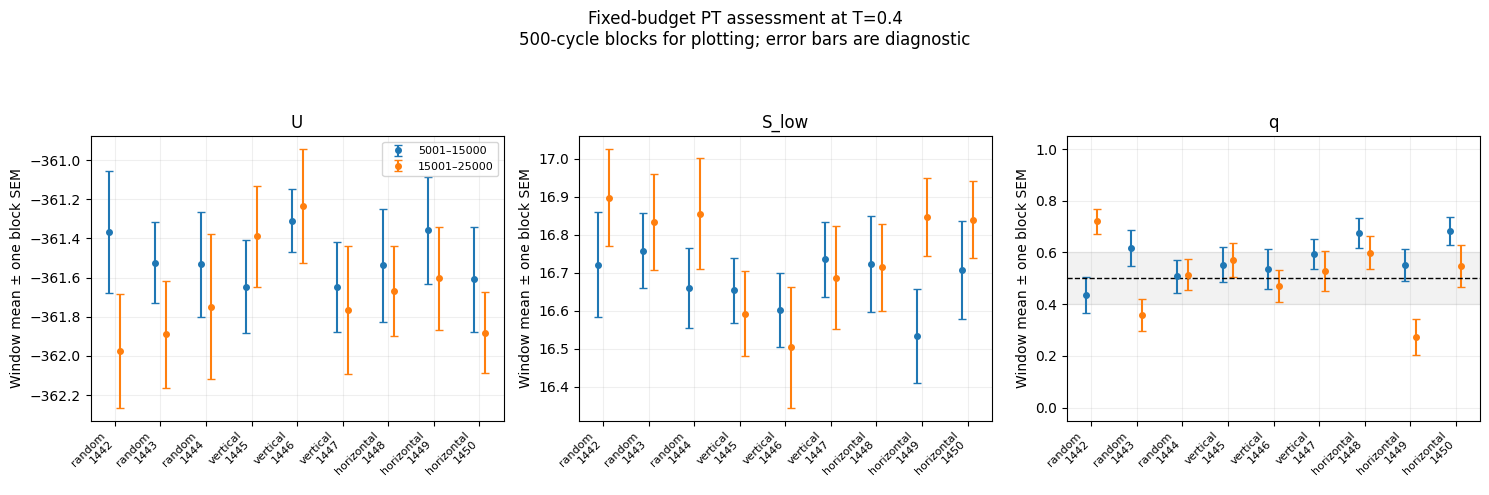


Precision screens passed: False
Stability/direction screens passed: False
Decision: NOT_READY_PRECISION_SCREEN_NOT_MET
Joint-distribution qualification is not established by these screens.
No additional simulation was performed.
Saved to: C:\Users\user\Documents\GitHub\active-matter-reproductions\lattice-gas\results\pt_reference_candidate_20x20_20261103_210139_276291\assessment_20261103_213923_279650


In [64]:
from pathlib import Path
from datetime import datetime
import json
import numpy as np
import matplotlib.pyplot as plt

source_dir = Path(pt20_reference_dir)
config = json.loads(
    (source_dir / "config.json").read_text(encoding="utf-8")
)
assert config["experiment"] == "PT20_FIXED_BUDGET_REFERENCE_CANDIDATE_V1"

assessment_dir = source_dir / (
    "assessment_" + datetime.now().strftime("%Y%m%d_%H%M%S_%f")
)
assessment_dir.mkdir(exist_ok=False)

blocks = config["analysis"]["block_lengths_cycles"]
thresholds = config["analysis"]["mean_screens"]
windows = config["measurement_windows"]
total_cycles = config["cycles_per_run"]
chunk_size = config["checkpoint_cycles"]
n_slots = len(config["temperatures"])

pt20_assessed_runs = {}
assessment_rows = []
source_files = []


def block_sem(values, block_length):
    values = np.asarray(values, dtype=float)
    assert len(values) % block_length == 0
    means = values.reshape(-1, block_length).mean(axis=1)
    assert len(means) >= 2
    return float(means.std(ddof=1) / np.sqrt(len(means)))


for initial, seed in config["runs"]:
    pieces = {
        key: [] for key in
        ("cycles", "target_U", "target_S_low", "target_D")
    }
    previous = None

    for start in range(0, total_cycles, chunk_size):
        end = min(start + chunk_size, total_cycles)
        path = source_dir / (
            f"{initial}_seed_{seed}_{start:06d}_{end:06d}.npz"
        )

        with np.load(path, allow_pickle=False) as saved:
            assert str(saved["initial"].item()) == initial
            assert int(saved["seed"]) == seed
            assert int(saved["start_cycle"]) == start
            assert int(saved["end_cycle"]) == end
            assert np.array_equal(
                saved["cycles"], np.arange(start, end + 1)
            )
            assert np.array_equal(
                saved["temperatures"], config["temperatures"]
            )

            energies = saved["energy_by_slot"]
            ids = saved["replica_ids_by_slot"]
            assert energies.shape == (end - start + 1, n_slots)
            assert ids.shape == energies.shape
            assert np.isfinite(energies).all()
            assert np.array_equal(
                np.sort(ids, axis=1),
                np.broadcast_to(np.arange(n_slots), ids.shape),
            )
            assert np.allclose(
                saved["target_U"], energies[:, 0],
                rtol=0, atol=1e-12,
            )

            assert int(saved["within_slot_proposals"]) == (
                (end - start) * n_slots * config["L"] ** 2
            )
            assert int(saved["replica_exchange_attempts"]) == (
                (end - start) * (n_slots - 1)
            )

            if previous is not None:
                assert np.array_equal(
                    previous["states"], saved["initial_states"]
                )
                assert np.array_equal(previous["ids"], ids[0])
                assert np.allclose(
                    previous["energies"], energies[0],
                    rtol=0, atol=1e-12,
                )
                assert previous["rng"] == json.loads(
                    saved["rng_state_start_json"].item()
                )
                for key in ("target_U", "target_S_low", "target_D"):
                    assert np.isclose(
                        previous[key], saved[key][0],
                        rtol=0, atol=1e-12,
                    )

            previous = {
                "states": saved["final_states"].copy(),
                "ids": ids[-1].copy(),
                "energies": energies[-1].copy(),
                "rng": json.loads(saved["rng_state_end_json"].item()),
                **{
                    key: float(saved[key][-1])
                    for key in ("target_U", "target_S_low", "target_D")
                },
            }

            # Keep each cycle exactly once.
            selection = slice(None) if start == 0 else slice(1, None)
            for key in pieces:
                array = saved[key]
                assert array.shape == (end - start + 1,)
                assert np.isfinite(array).all()
                pieces[key].append(array[selection].copy())

        source_files.append(path.name)

    run = {
        key: np.concatenate(arrays)
        for key, arrays in pieces.items()
    }
    assert np.array_equal(run["cycles"], np.arange(total_cycles + 1))

    run["U"] = run["target_U"]
    run["S_low"] = run["target_S_low"]
    d = run["target_D"]
    run["q"] = (d > 0).astype(float) + 0.5 * (d == 0)

    pt20_assessed_runs[(initial, seed)] = run
    cycles = run["cycles"]
    measurement = cycles > config["initial_exclusion"]
    assert int(measurement.sum()) == 20_000

    for observable in ("U", "S_low", "q"):
        values = run[observable]
        measured = values[measurement]

        sems = {
            str(length): block_sem(measured, length)
            for length in blocks
        }
        window_stats = []

        for first, last in windows:
            mask = (cycles >= first) & (cycles <= last)
            assert int(mask.sum()) == last - first + 1
            window_values = values[mask]
            window_stats.append({
                "start": first,
                "end": last,
                "mean": float(window_values.mean()),
                "block_sem_500": block_sem(window_values, 500),
            })

        assessment_rows.append({
            "initial": initial,
            "seed": seed,
            "observable": observable,
            "mean": float(measured.mean()),
            "block_sems": sems,
            "max_block_sem": max(sems.values()),
            "windows": window_stats,
            "window_change": (
                window_stats[1]["mean"] - window_stats[0]["mean"]
            ),
        })

assert len(source_files) == 45
assert len(pt20_assessed_runs) == 9

# Apply the frozen operational screens.
screen_results = {}

for observable in ("U", "S_low", "q"):
    rows = [
        row for row in assessment_rows
        if row["observable"] == observable
    ]
    limits = thresholds[observable]

    metrics = {
        "max_window_change": max(abs(r["window_change"]) for r in rows),
        "max_block_sem": max(r["max_block_sem"] for r in rows),
    }

    if observable == "q":
        metrics["max_distance_from_half_per_chain"] = max(
            abs(r["mean"] - 0.5) for r in rows
        )
    else:
        means = [r["mean"] for r in rows]
        metrics["max_chain_range"] = max(means) - min(means)

    screen_results[observable] = {
        metric: {
            "observed": float(value),
            "limit": float(limits[metric]),
            "passed": bool(value <= limits[metric]),
        }
        for metric, value in metrics.items()
    }

precision_pass = all(
    result["max_block_sem"]["passed"]
    for result in screen_results.values()
)
stability_pass = all(
    item["passed"]
    for result in screen_results.values()
    for metric, item in result.items()
    if metric != "max_block_sem"
)
all_pass = precision_pass and stability_pass

if not precision_pass:
    decision = "NOT_READY_PRECISION_SCREEN_NOT_MET"
elif not stability_pass:
    decision = "NOT_READY_STABILITY_OR_DIRECTION_SCREEN_NOT_MET"
else:
    decision = "FROZEN_MEAN_AND_DIRECTION_SCREENS_PASSED"

# Print all nine chains, followed by each observable's screen results.
print("Loaded 45 segments; cycle coverage and checkpoint joins checked.")

for observable in ("U", "S_low", "q"):
    print(f"\n{observable}: cycles 5001–25000")
    print(
        "Initial    Seed | Mean       | SEM: 500 / 1000 / 2000 "
        "| Window change"
    )

    for row in assessment_rows:
        if row["observable"] != observable:
            continue
        sem_text = " / ".join(
            f"{row['block_sems'][str(length)]:.4f}"
            for length in blocks
        )
        print(
            f"{row['initial']:10s} {row['seed']} | "
            f"{row['mean']:10.5f} | {sem_text} | "
            f"{row['window_change']:+.5f}"
        )

    for metric, result in screen_results[observable].items():
        flag = "PASS" if result["passed"] else "NOT MET"
        print(
            f"  {metric}: {result['observed']:.5f} "
            f"<= {result['limit']:.5f}: {flag}"
        )

# Compare the two fixed windows for all nine chains.
labels = [
    f"{initial}\n{seed}" for initial, seed in config["runs"]
]
x = np.arange(len(labels))
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, observable in zip(axes, ("U", "S_low", "q")):
    rows = [
        row for row in assessment_rows
        if row["observable"] == observable
    ]

    for index, (first, last) in enumerate(windows):
        offset = -0.12 if index == 0 else 0.12
        ax.errorbar(
            x + offset,
            [r["windows"][index]["mean"] for r in rows],
            yerr=[r["windows"][index]["block_sem_500"] for r in rows],
            fmt="o", markersize=4, capsize=3,
            label=f"{first}–{last}",
        )

    if observable == "q":
        ax.axhline(0.5, color="black", linestyle="--", linewidth=1)
        ax.axhspan(0.4, 0.6, color="gray", alpha=0.10)
        ax.set_ylim(-0.05, 1.05)

    ax.set_title(observable)
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=45, ha="right", fontsize=8)
    ax.set_ylabel("Window mean ± one block SEM")
    ax.grid(alpha=0.2)

axes[0].legend(fontsize=8)
fig.suptitle(
    "Fixed-budget PT assessment at T=0.4\n"
    "500-cycle blocks for plotting; error bars are diagnostic"
)
fig.tight_layout(rect=(0, 0, 1, 0.91))
fig.savefig(assessment_dir / "window_comparison.png", dpi=180)
plt.show()

report = {
    "decision": decision,
    "source_directory": str(source_dir.resolve()),
    "source_files": source_files,
    "frozen_analysis_config": config["analysis"],
    "measurement_windows": windows,
    "rows": assessment_rows,
    "screens": screen_results,
    "precision_screens_passed": precision_pass,
    "stability_and_direction_screens_passed": stability_pass,
    "all_screens_passed": all_pass,
    "joint_distribution_qualified": False,
    "limitations": [
        "Block SEM estimates do not bound equilibrium bias.",
        "Correlations longer than the tested block lengths may remain.",
        "The initial exclusion interval is prescribed, not proven sufficient.",
        "Passing mean and direction screens does not establish joint accuracy.",
        "The previous provisional reference is not overwritten.",
    ],
}

(assessment_dir / "reference_assessment.json").write_text(
    json.dumps(report, indent=2, allow_nan=False),
    encoding="utf-8",
)

print("\nPrecision screens passed:", precision_pass)
print("Stability/direction screens passed:", stability_pass)
print("Decision:", decision)
print("Joint-distribution qualification is not established by these screens.")
print("No additional simulation was performed.")
print("Saved to:", assessment_dir.resolve())

### Final decision: NOT READY under the fixed budget

All nine PT runs and the prescribed assessment were completed.

The energy mean passed the between-chain range and temporal-window
screens, but its maximum block SEM exceeded the frozen precision limit.
The directional weight q failed the precision, temporal stability,
and symmetry-target screens.

The candidate is therefore not qualified as the intended reference
under this protocol. This outcome does not establish an implementation
error or a general failure of parallel tempering.

Retain all trajectories, checkpoints, and assessment results.
Do not extend runs or relax thresholds within this task.
The existing provisional observable-mean reference remains unchanged.

In [65]:
from pathlib import Path
import json
import numpy as np

results_root = Path("results")

local_dir = results_root / (
    "kawasaki_initial_states_20261102_215633_047070"
)
reference_dir = results_root / (
    "nonlocal_20x20_100k_20261102_234519_565743"
)

for directory in (local_dir, reference_dir):
    if not directory.is_dir():
        raise FileNotFoundError(
            f"Directory not found: {directory.resolve()}\n"
            "Set results_root to your lattice-gas/results directory."
        )

print("LOCAL KAWASAKI FILES")
for path in sorted(local_dir.iterdir()):
    if path.is_file():
        print(path.name)

trajectory_files = sorted(local_dir.glob("*.npz"))

if trajectory_files:
    example_path = trajectory_files[0]
    print(f"\nEXAMPLE FILE: {example_path.name}")

    with np.load(example_path, allow_pickle=False) as data:
        for name in data.files:
            try:
                values = data[name]
            except ValueError:
                print(f"{name}: object array; not loaded")
                continue

            print(
                f"{name}: shape={values.shape}, dtype={values.dtype}"
            )

            if (
                values.ndim == 1
                and values.size > 0
                and any(word in name.lower()
                        for word in ("sweep", "step", "time"))
            ):
                print("  First entries:", values[:5])
                print("  Last entries: ", values[-5:])
else:
    print("\nNo top-level NPZ files found.")

summary_path = reference_dir / "provisional_reference_summary.json"

print("\nPROVISIONAL REFERENCE")
with summary_path.open(encoding="utf-8") as file:
    reference_summary = json.load(file)

print(json.dumps(reference_summary, indent=2, ensure_ascii=False))

LOCAL KAWASAKI FILES
config.json
final_configurations.png
observable_comparison.png
random_seed_442.npz
random_seed_442_rng.json
random_seed_443.npz
random_seed_443_rng.json
random_seed_444.npz
random_seed_444_rng.json
stripe_seed_445.npz
stripe_seed_445_rng.json
stripe_seed_446.npz
stripe_seed_446_rng.json
stripe_seed_447.npz
stripe_seed_447_rng.json
window_summary.json

EXAMPLE FILE: random_seed_442.npz
record_sweeps: shape=(1001,), dtype=int64
  First entries: [ 0 10 20 30 40]
  Last entries:  [ 9960  9970  9980  9990 10000]
boundary: shape=(1001,), dtype=int64
U: shape=(1001,), dtype=float64
S_low: shape=(1001,), dtype=float64
move_fraction: shape=(10000,), dtype=float64
snapshot_sweeps: shape=(6,), dtype=int64
  First entries: [   0  100 1000 5000 7500]
  Last entries:  [  100  1000  5000  7500 10000]
snapshots: shape=(6, 20, 20), dtype=int64
final_state: shape=(20, 20), dtype=int64

PROVISIONAL REFERENCE
{
  "status": "PROVISIONAL_OBSERVABLE_MEAN_REFERENCE",
  "reference_rows": [

In [66]:
# Compact metadata output; no simulation or file modification.

for label, directory in (
    ("LOCAL CONFIG", local_dir),
    ("REFERENCE CONFIG", reference_dir),
):
    print(f"\n{label}")
    with (directory / "config.json").open(encoding="utf-8") as file:
        config = json.load(file)

    for key, value in config.items():
        print(f"{key}: {json.dumps(value, ensure_ascii=False)}")

print("\nREFERENCE STATUS")
print(reference_summary.get("status", "Status field not found"))

print("\nREFERENCE ROWS")
rows = reference_summary["reference_rows"]
if isinstance(rows, list):
    for row in rows:
        print(json.dumps(row, ensure_ascii=False))
else:
    print(json.dumps(rows, ensure_ascii=False))


LOCAL CONFIG
L: 20
N: 200
temperature: 0.4
epsilon: 1.0
sweeps: 10000
record_every: 10
snapshot_sweeps: [0, 100, 1000, 5000, 7500, 10000]
seeds: {"random": [442, 443, 444], "stripe": [445, 446, 447]}
analysis_windows: [[5001, 7500], [7501, 10000]]
diagnostic_block_lengths_sweeps: [250, 500]
boundary: "periodic"
sweep_definition: "L**2 uniform bond proposals, including no-change moves"
status: "Initial-state sensitivity diagnostic; equilibrium not established"
python_version: "3.14.2"
numpy_version: "2.4.1"

REFERENCE CONFIG
source_directory: "C:\\Users\\user\\Documents\\GitHub\\active-matter-reproductions\\lattice-gas\\results\\nonlocal_20x20_20261102_232409_996903"
model_config: {"L": 20, "N": 200, "temperature": 0.4, "epsilon": 1.0, "sweeps": 20000, "initial_exclusion": 5000, "record_every": 10, "configuration_every": 100, "analysis_windows": [[5001, 12500], [12501, 20000]], "seeds": {"random": [842, 843, 844], "vertical": [845, 846, 847], "horizontal": [848, 849, 850]}, "rng_stream


U: provisional reference = -361.738375; between-chain SEM = 0.048010
Initial seed | Window       | Local mean | Difference | SEM250 / SEM500
random 442   |  5001-7500  |  -357.4880 |    +4.2504 | 0.8507 / 0.9678
random 442   |  7501-10000 |  -357.7000 |    +4.0384 | 0.9898 / 1.3050
random 443   |  5001-7500  |  -351.4400 |   +10.2984 | 1.0385 / 1.1518
random 443   |  7501-10000 |  -350.8360 |   +10.9024 | 1.3179 / 0.9734
random 444   |  5001-7500  |  -358.3360 |    +3.4024 | 0.6087 / 0.7064
random 444   |  7501-10000 |  -360.9800 |    +0.7584 | 0.7721 / 0.5624
stripe 445   |  5001-7500  |  -357.9480 |    +3.7904 | 0.9486 / 1.2728
stripe 445   |  7501-10000 |  -361.1960 |    +0.5424 | 0.9260 / 1.0921
stripe 446   |  5001-7500  |  -362.8600 |    -1.1216 | 0.8138 / 1.0488
stripe 446   |  7501-10000 |  -363.3040 |    -1.5656 | 1.0018 / 1.4566
stripe 447   |  5001-7500  |  -364.5760 |    -2.8376 | 0.8032 / 1.1561
stripe 447   |  7501-10000 |  -363.4960 |    -1.7576 | 0.4716 / 0.3155

S_low

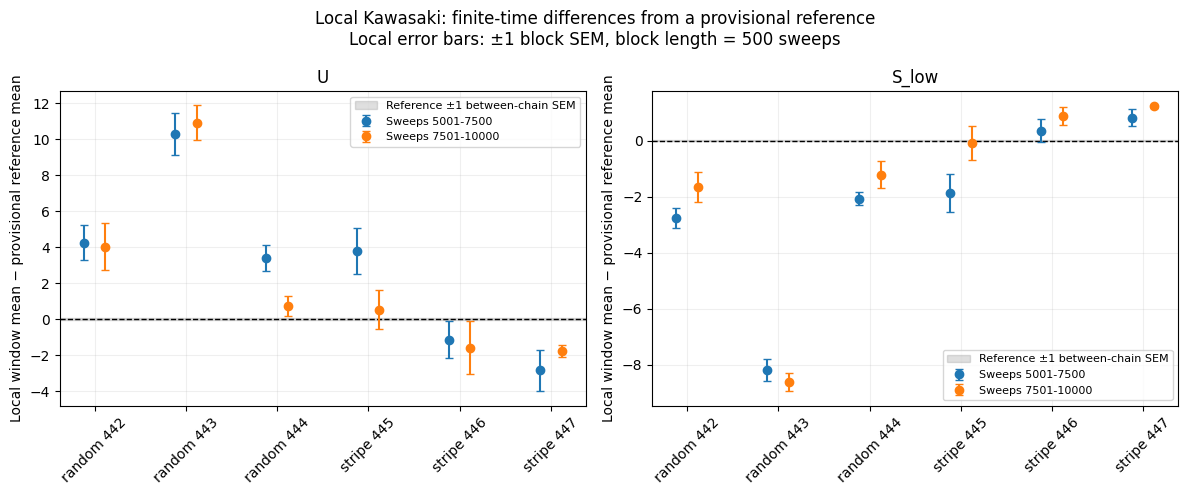


Descriptive comparison only; no equilibrium PASS/FAIL.
Saved to: C:\Users\user\Documents\GitHub\active-matter-reproductions\lattice-gas\results\kawasaki_initial_states_20261102_215633_047070\provisional_reference_comparison_20261103_213924_068365


In [67]:
from datetime import datetime
import hashlib
import json

import numpy as np
import matplotlib.pyplot as plt

# Read the saved configurations and reference.
with (local_dir / "config.json").open(encoding="utf-8") as file:
    local_config = json.load(file)

with (reference_dir / "config.json").open(encoding="utf-8") as file:
    reference_config = json.load(file)

with (reference_dir / "provisional_reference_summary.json").open(
    encoding="utf-8"
) as file:
    reference_summary = json.load(file)

reference_model = reference_config["model_config"]

for key in ("L", "N", "temperature", "epsilon"):
    assert local_config[key] == reference_model[key], (
        f"Physical parameter mismatch: {key}"
    )

assert reference_summary["status"] == (
    "PROVISIONAL_OBSERVABLE_MEAN_REFERENCE"
)

reference_by_name = {
    row["observable"]: row
    for row in reference_summary["reference_rows"]
}

windows = local_config["analysis_windows"]
block_lengths = local_config["diagnostic_block_lengths_sweeps"]
record_every = int(local_config["record_every"])
observables = ("U", "S_low")


def window_block_sem(values, block_sweeps):
    """Diagnostic SEM from non-overlapping block means."""
    assert block_sweeps % record_every == 0
    records_per_block = block_sweeps // record_every

    assert len(values) % records_per_block == 0
    block_means = values.reshape(-1, records_per_block).mean(axis=1)
    assert len(block_means) >= 2

    sem = block_means.std(ddof=1) / np.sqrt(len(block_means))
    return float(sem), int(len(block_means))


comparison_rows = []
chain_labels = []
source_files = [
    local_dir / "config.json",
    reference_dir / "config.json",
    reference_dir / "provisional_reference_summary.json",
]

for initial, seeds in local_config["seeds"].items():
    for seed in seeds:
        label = f"{initial} {seed}"
        chain_labels.append(label)

        path = local_dir / f"{initial}_seed_{seed}.npz"
        source_files.append(path)

        with np.load(path, allow_pickle=False) as data:
            sweeps = data["record_sweeps"].copy()
            traces = {
                name: data[name].astype(float)
                for name in observables
            }
            boundary = data["boundary"].astype(float)

        expected_sweeps = np.arange(
            0, local_config["sweeps"] + 1, record_every
        )
        assert np.array_equal(sweeps, expected_sweeps)

        for values in traces.values():
            assert values.shape == sweeps.shape
            assert np.isfinite(values).all()

        # Interaction energy convention on the periodic square lattice.
        expected_u = local_config["epsilon"] * (
            -2 * local_config["N"] + boundary / 2
        )
        assert np.allclose(
            traces["U"], expected_u, rtol=0, atol=1e-12
        )

        for window_id, (start, end) in enumerate(windows):
            mask = (sweeps >= start) & (sweeps <= end)

            for observable in observables:
                values = traces[observable][mask]
                assert values.size > 0
                mean = float(values.mean())

                sems = {}
                block_counts = {}
                for block_sweeps in block_lengths:
                    sem, count = window_block_sem(values, block_sweeps)
                    sems[str(block_sweeps)] = sem
                    block_counts[str(block_sweeps)] = count

                ref = reference_by_name[observable]

                comparison_rows.append({
                    "initial": initial,
                    "seed": int(seed),
                    "label": label,
                    "observable": observable,
                    "window_id": window_id,
                    "window": [int(start), int(end)],
                    "n_records": int(values.size),
                    "local_mean": mean,
                    "reference_mean": float(ref["mean"]),
                    "difference": mean - float(ref["mean"]),
                    "local_block_sem": sems,
                    "n_blocks": block_counts,
                    "reference_between_chain_sem": float(
                        ref["between_chain_sem"]
                    ),
                    "reference_combined_block_sem": float(
                        ref["combined_block_sem"]
                    ),
                })

# Compact numerical output.
for observable in observables:
    ref = reference_by_name[observable]
    print(
        f"\n{observable}: provisional reference = {ref['mean']:.6f}"
        f"; between-chain SEM = {ref['between_chain_sem']:.6f}"
    )
    print(
        "Initial seed | Window       | Local mean | Difference"
        " | SEM250 / SEM500"
    )

    for row in comparison_rows:
        if row["observable"] != observable:
            continue
        start, end = row["window"]
        sems = row["local_block_sem"]
        print(
            f"{row['label']:12s} | {start:5d}-{end:<5d} | "
            f"{row['local_mean']:10.4f} | "
            f"{row['difference']:+10.4f} | "
            f"{sems['250']:.4f} / {sems['500']:.4f}"
        )

# Plot differences rather than overlapping absolute means.
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
x = np.arange(len(chain_labels))

for ax, observable in zip(axes, observables):
    ref = reference_by_name[observable]
    ref_sem = float(ref["between_chain_sem"])

    ax.axhspan(
        -ref_sem, ref_sem, color="gray", alpha=0.25,
        label="Reference ±1 between-chain SEM"
    )
    ax.axhline(0, color="black", linestyle="--", linewidth=1)

    for window_id, (start, end) in enumerate(windows):
        selected = {
            row["label"]: row
            for row in comparison_rows
            if row["observable"] == observable
            and row["window_id"] == window_id
        }
        ordered = [selected[label] for label in chain_labels]
        offset = (-0.12, 0.12)[window_id]

        ax.errorbar(
            x + offset,
            [row["difference"] for row in ordered],
            yerr=[
                row["local_block_sem"]["500"] for row in ordered
            ],
            fmt="o", capsize=3,
            label=f"Sweeps {start}-{end}"
        )

    ax.set(
        title=observable,
        ylabel="Local window mean − provisional reference mean",
        xticks=x,
        xticklabels=chain_labels,
    )
    ax.tick_params(axis="x", labelrotation=45)
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)

fig.suptitle(
    "Local Kawasaki: finite-time differences from a provisional reference\n"
    "Local error bars: ±1 block SEM, block length = 500 sweeps"
)
fig.tight_layout()

# Save a separate analysis without modifying the source results.
comparison_dir = local_dir / (
    "provisional_reference_comparison_"
    + datetime.now().strftime("%Y%m%d_%H%M%S_%f")
)
comparison_dir.mkdir(exist_ok=False)

report = {
    "status": "DESCRIPTIVE_FINITE_TIME_COMPARISON",
    "local_directory": str(local_dir.resolve()),
    "reference_directory": str(reference_dir.resolve()),
    "reference_status": reference_summary["status"],
    "windows": windows,
    "block_lengths_sweeps": block_lengths,
    "rows": comparison_rows,
    "source_sha256": {
        str(path.resolve()): hashlib.sha256(path.read_bytes()).hexdigest()
        for path in source_files
    },
    "limitations": [
        "The reference is provisional, not exact equilibrium ground truth.",
        "Block SEM estimates are diagnostic and use few blocks per window.",
        "Reference equilibrium bias is not quantified.",
        "Agreement of means does not establish equilibrium or distributional agreement.",
        "No new simulation or sampling-efficiency comparison was performed.",
    ],
}

(comparison_dir / "comparison.json").write_text(
    json.dumps(report, indent=2, allow_nan=False),
    encoding="utf-8",
)
fig.savefig(comparison_dir / "mean_differences.png", dpi=180)
plt.show()

print("\nDescriptive comparison only; no equilibrium PASS/FAIL.")
print("Saved to:", comparison_dir.resolve())

### Local Kawasaki: finite-time comparison with a provisional reference

At L=20, N=200, T=0.4, and epsilon=1, the local Kawasaki
trajectories exhibit substantial between-run differences in their
late-window means.

Changes between sweeps 5001–7500 and 7501–10000 are not uniformly
toward the provisional reference. Improved agreement in energy does
not necessarily coincide with improved agreement in S_low.

Small within-window block SEMs do not establish equilibrium accuracy.
The observed differences are relative to a provisional reference whose
equilibrium bias remains unquantified.

These trajectories are retained as finite-time sampling diagnostics,
not qualified equilibrium samples. No new simulation was performed,
and the existing reference decisions remain unchanged.

## Exact Validation of a Rotation Update

For the isotropic square lattice with periodic boundaries, choose
k uniformly from {0, 1, 2, 3} and rotate the configuration by 90k degrees.

This update preserves particle number and interaction energy.
Each rotation has an equally probable inverse, so the update satisfies
detailed balance with respect to the fixed-N canonical distribution.

We validate the update by enumerating all 4×4 configurations with N=8.
Checks include the rotation maps, canonical stationarity, and the
transformation of U, S_low, and D.

This is a deterministic implementation check, not a sampling benchmark.
Rotations do not change U, S_low, or |D| and cannot by themselves improve
sampling of these observables. Rotated copies are not independent samples.

In [68]:
from itertools import combinations
from pathlib import Path
from datetime import datetime
import json
import numpy as np


def rotate_square_state(state, k):
    """Return an independent array rotated counterclockwise by 90k degrees."""
    state = np.asarray(state)
    if state.ndim != 2 or state.shape[0] != state.shape[1]:
        raise ValueError("A square 2D state is required.")
    return np.rot90(state, k=int(k), axes=(0, 1)).copy()


def random_rotation_update(state, rng):
    """Uniform rotation kernel, including the identity rotation."""
    k = int(rng.integers(4))
    return rotate_square_state(state, k)


# Fixed validation system; no Monte Carlo trajectory is generated.
rot_config = {
    "task": "EXACT_4X4_ROTATION_KERNEL_VALIDATION_V1",
    "L": 4,
    "N": 8,
    "temperature": 0.4,
    "epsilon": 1.0,
    "boundary": "periodic",
    "rotation_probabilities": [0.25, 0.25, 0.25, 0.25],
    "tolerance": 1e-12,
}

L = rot_config["L"]
N = rot_config["N"]
M = L * L
tol = rot_config["tolerance"]

# Enumerate all fixed-N states independently of notebook globals.
occupied_sites = np.array(
    list(combinations(range(M), N)), dtype=np.int64
)
flat_states = np.zeros((len(occupied_sites), M), dtype=np.int8)
flat_states[
    np.arange(len(flat_states))[:, None], occupied_sites
] = 1
rot_states = flat_states.reshape(-1, L, L)
n_states = len(rot_states)

assert n_states == 12870

# Encode each state as a unique integer for exact lookup.
bit_weights = np.left_shift(
    np.uint64(1), np.arange(M, dtype=np.uint64)
)
state_codes = flat_states.astype(np.uint64) @ bit_weights

lookup = np.full(1 << M, -1, dtype=np.int64)
lookup[state_codes.astype(np.int64)] = np.arange(n_states)

# Periodic interaction energy: count each bond once.
occupied_bonds = (
    rot_states * np.roll(rot_states, -1, axis=1)
    + rot_states * np.roll(rot_states, -1, axis=2)
).sum(axis=(1, 2))

rot_energy = -rot_config["epsilon"] * occupied_bonds

log_weights = -rot_energy / rot_config["temperature"]
weights = np.exp(log_weights - log_weights.max())
rot_pi = weights / weights.sum()

# Use the same Fourier normalization as the previous experiments.
fluctuations = rot_states.astype(float) - N / M
spectrum = np.abs(
    np.fft.fft2(fluctuations, axes=(1, 2))
) ** 2 / M

s0 = (spectrum[:, 1, 0] + spectrum[:, -1, 0]) / 2
s1 = (spectrum[:, 0, 1] + spectrum[:, 0, -1]) / 2
rot_s_low = (s0 + s1) / 2
rot_d = s0 - s1

# Build all four deterministic rotation maps.
rotation_targets = []

for k in range(4):
    rotated = np.rot90(
        rot_states, k=k, axes=(1, 2)
    ).copy()

    assert np.all(rotated.sum(axis=(1, 2)) == N)

    codes = (
        rotated.reshape(n_states, M).astype(np.uint64)
        @ bit_weights
    )
    targets = lookup[codes.astype(np.int64)]

    assert np.all(targets >= 0)
    assert np.array_equal(
        np.sort(targets), np.arange(n_states)
    )
    rotation_targets.append(targets)

rotation_targets = np.stack(rotation_targets)
state_ids = np.arange(n_states)

max_energy_error = 0.0
max_s_low_error = 0.0
max_d_error = 0.0
max_weight_error = 0.0

for k, targets in enumerate(rotation_targets):
    inverse_targets = rotation_targets[(-k) % 4]

    # An equally probable inverse exists for every proposed rotation.
    assert np.array_equal(inverse_targets[targets], state_ids)

    max_energy_error = max(
        max_energy_error,
        float(np.max(np.abs(rot_energy[targets] - rot_energy))),
    )
    max_s_low_error = max(
        max_s_low_error,
        float(np.max(np.abs(rot_s_low[targets] - rot_s_low))),
    )
    max_d_error = max(
        max_d_error,
        float(np.max(np.abs(rot_d[targets] - (-1)**k * rot_d))),
    )
    max_weight_error = max(
        max_weight_error,
        float(np.max(np.abs(rot_pi[targets] - rot_pi))),
    )

# Compute pi @ K, including repeated targets for symmetric states.
pi_after_rotation = np.zeros_like(rot_pi)
for targets in rotation_targets:
    np.add.at(pi_after_rotation, targets, rot_pi / 4)

stationarity_l1_error = float(
    np.abs(pi_after_rotation - rot_pi).sum()
)

# Check that the callable returns a copy, including k=0.
for k in range(4):
    sample = rot_states[0].copy()
    rotated = rotate_square_state(sample, k)
    assert not np.shares_memory(sample, rotated)
    assert np.array_equal(
        rotated, rot_states[rotation_targets[k, 0]]
    )

errors = {
    "max_energy_error": max_energy_error,
    "max_S_low_error": max_s_low_error,
    "max_D_transformation_error": max_d_error,
    "max_canonical_weight_error": max_weight_error,
    "stationarity_L1_error": stationarity_l1_error,
}

assert all(value < tol for value in errors.values())

rotation_report = {
    "status": "EXACT_ROTATION_KERNEL_CHECKS_PASSED",
    "config": rot_config,
    "states": n_states,
    "rotation_cases": 4 * n_states,
    "errors": errors,
    "inverse_maps_and_bijections_checked": True,
    "independent_array_copy_checked": True,
    "new_MC_trajectories": 0,
    "scope": (
        "Rotation-kernel validation only. "
        "No mixing, efficiency, or 20x20 equilibrium qualification."
    ),
}

rotation_check_dir = Path("results") / (
    "rotation_validation_4x4_"
    + datetime.now().strftime("%Y%m%d_%H%M%S_%f")
)
rotation_check_dir.mkdir(parents=True, exist_ok=False)

(rotation_check_dir / "validation.json").write_text(
    json.dumps(rotation_report, indent=2, allow_nan=False),
    encoding="utf-8",
)

print(f"Enumerated states: {n_states}")
print(f"Rotation cases checked: {4 * n_states}")
for name, value in errors.items():
    print(f"{name}: {value:.3e}")

print("PASS: exact rotation-kernel checks.")
print("No new MC trajectory was generated.")
print("20x20 reference status remains unchanged.")
print("Saved to:", rotation_check_dir.resolve())

Enumerated states: 12870
Rotation cases checked: 51480
max_energy_error: 0.000e+00
max_S_low_error: 0.000e+00
max_D_transformation_error: 0.000e+00
max_canonical_weight_error: 0.000e+00
stationarity_L1_error: 0.000e+00
PASS: exact rotation-kernel checks.
No new MC trajectory was generated.
20x20 reference status remains unchanged.
Saved to: C:\Users\user\Documents\GitHub\active-matter-reproductions\lattice-gas\results\rotation_validation_4x4_20261103_213924_361140


## Periodic Cluster and Wrapping Observables

Occupied sites are connected through four nearest neighbors with
periodic boundaries.

For each connected component, record its size, wrapping projections
along both lattice axes, and winding rank. Wrapping is detected from
nonzero winding of closed paths, not merely from crossing an image edge.

The largest-cluster fraction is f_max = N_max / N.
For an empty configuration, f_max is defined as zero.

Validation uses synthetic configurations with known answers and checks
translation invariance and rotation covariance. These checks do not
assess equilibrium sampling or provide a complete shape description.

In [69]:
import numpy as np


def periodic_cluster_observables(state):
    """Measure occupied clusters and closed-path winding on a 2D torus."""
    a = np.asarray(state)
    if (
        a.ndim != 2
        or min(a.shape) < 3
        or not np.isin(a, [0, 1]).all()
    ):
        raise ValueError(
            "A binary 2D array with each dimension >= 3 is required."
        )

    occupied = a == 1
    shape = np.array(a.shape, dtype=int)
    labels = np.full(a.shape, -1, dtype=int)
    lift = np.zeros((*a.shape, 2), dtype=int)
    components = []

    for root in zip(*np.nonzero(occupied)):
        if labels[root] >= 0:
            continue

        cid = len(components)
        labels[root] = cid
        stack = [root]
        size = 0
        wraps = np.zeros(2, dtype=bool)
        basis = None
        rank = 0

        while stack:
            i, j = stack.pop()
            size += 1

            for di, dj in ((1, 0), (-1, 0), (0, 1), (0, -1)):
                neighbor = (
                    (i + di) % a.shape[0],
                    (j + dj) % a.shape[1],
                )
                if not occupied[neighbor]:
                    continue

                proposed = lift[i, j] + (di, dj)

                if labels[neighbor] < 0:
                    labels[neighbor] = cid
                    lift[neighbor] = proposed
                    stack.append(neighbor)
                else:
                    assert labels[neighbor] == cid

                    # Two paths reach the same periodic site.
                    mismatch = proposed - lift[neighbor]
                    assert np.all(mismatch % shape == 0)
                    winding = mismatch // shape

                    if np.any(winding):
                        wraps |= winding != 0

                        if basis is None:
                            basis = winding.copy()
                            rank = 1
                        elif (
                            basis[0] * winding[1]
                            - basis[1] * winding[0]
                        ) != 0:
                            rank = 2

        components.append({
            "size": size,
            "wrap_axis0": bool(wraps[0]),
            "wrap_axis1": bool(wraps[1]),
            "winding_rank": rank,
        })

    n = int(occupied.sum())
    largest = max((c["size"] for c in components), default=0)
    assert sum(c["size"] for c in components) == n

    return {
        "N": n,
        "n_clusters": len(components),
        "f_max": largest / n if n else 0.0,
        "components": components,
    }


def cluster_signature(result, swap_axes=False):
    """Ignore component labels while retaining sizes and topology."""
    return sorted(
        (
            c["size"],
            c["wrap_axis1"] if swap_axes else c["wrap_axis0"],
            c["wrap_axis0"] if swap_axes else c["wrap_axis1"],
            c["winding_rank"],
        )
        for c in result["components"]
    )


# Known-answer tests. Tuple entries:
# (component size, wrap_axis0, wrap_axis1, winding rank).
cases = {}
a = np.zeros((8, 8), dtype=np.int8)

cases["empty"] = (a.copy(), [], 0.0)

a[3, 3] = 1
cases["single"] = (a.copy(), [(1, False, False, 0)], 1.0)

a[:] = 0
a[3, [0, 7]] = 1
cases["seam_pair"] = (a.copy(), [(2, False, False, 0)], 1.0)

a[:] = 0
a[2:6, 2:6] = 1
cases["droplet"] = (a.copy(), [(16, False, False, 0)], 1.0)

a[:] = 0
a[:, 2:6] = 1
cases["vertical"] = (a.copy(), [(32, True, False, 1)], 1.0)
cases["horizontal"] = (a.T.copy(), [(32, False, True, 1)], 1.0)

a[:] = 0
a[1:3, 1:3] = 1
a[5:7, 5:7] = 1
cases["two_droplets"] = (
    a.copy(), [(4, False, False, 0)] * 2, 0.5
)

a[:] = 0
for i in range(8):
    a[i, i] = 1
    a[i, (i + 1) % 8] = 1
cases["diagonal_loop"] = (a.copy(), [(16, True, True, 1)], 1.0)

a[:] = 1
cases["full"] = (a.copy(), [(64, True, True, 2)], 1.0)

transformation_checks = 0

for name, (state, expected, expected_fraction) in cases.items():
    original = state.copy()
    result = periodic_cluster_observables(state)

    assert cluster_signature(result) == expected, name
    assert result["f_max"] == expected_fraction, name
    assert np.array_equal(state, original), "Input was modified."

    # Every translation and quarter-turn rotation of each test state.
    for di in range(8):
        for dj in range(8):
            for k in range(4):
                changed = np.rot90(
                    np.roll(state, (di, dj), axis=(0, 1)), k
                )
                measured = periodic_cluster_observables(changed)

                assert cluster_signature(measured) == cluster_signature(
                    result, swap_axes=bool(k % 2)
                ), (name, di, dj, k)
                assert measured["f_max"] == expected_fraction
                transformation_checks += 1

    print(
        f"{name:14s} | f_max={result['f_max']:.2f}"
        f" | components={cluster_signature(result)}"
    )

print(f"\nPASS: {len(cases)} known-answer configurations.")
print(f"PASS: {transformation_checks} translation/rotation checks.")
print("No MC simulation or equilibrium assessment was performed.")

empty          | f_max=0.00 | components=[]
single         | f_max=1.00 | components=[(1, False, False, 0)]
seam_pair      | f_max=1.00 | components=[(2, False, False, 0)]
droplet        | f_max=1.00 | components=[(16, False, False, 0)]
vertical       | f_max=1.00 | components=[(32, True, False, 1)]
horizontal     | f_max=1.00 | components=[(32, False, True, 1)]
two_droplets   | f_max=0.50 | components=[(4, False, False, 0), (4, False, False, 0)]
diagonal_loop  | f_max=1.00 | components=[(16, True, True, 1)]
full           | f_max=1.00 | components=[(64, True, True, 2)]

PASS: 9 known-answer configurations.
PASS: 2304 translation/rotation checks.
No MC simulation or equilibrium assessment was performed.


In [70]:
from pathlib import Path
from datetime import datetime
from collections import Counter
import json
import numpy as np

pt_shape_source = Path("results") / (
    "pt_reference_candidate_20x20_20261103_015925_101620"
)
if not pt_shape_source.is_dir():
    raise FileNotFoundError(pt_shape_source.resolve())

shape_runs = {
    "random": [1442, 1443, 1444],
    "vertical": [1445, 1446, 1447],
    "horizontal": [1448, 1449, 1450],
}
shape_windows = [(5001, 15000), (15001, 25000)]

# These describe winding of occupied components, not complete morphology.
topology_names = [
    "none",
    "axis0_only",
    "axis1_only",
    "both_projections_rank1",
    "rank2_present",
]


def occupied_wrapping_class(components):
    """Classify wrapping using all occupied components."""
    if any(c["winding_rank"] == 2 for c in components):
        return "rank2_present"

    w0 = any(c["wrap_axis0"] for c in components)
    w1 = any(c["wrap_axis1"] for c in components)

    if w0 and w1:
        return "both_projections_rank1"
    if w0:
        return "axis0_only"
    if w1:
        return "axis1_only"
    return "none"


shape_snapshot_rows = []
shape_summary_rows = []
shape_source_files = []

for initial, seeds in shape_runs.items():
    for seed in seeds:
        snapshots = {}

        for start in range(0, 25000, 5000):
            end = start + 5000
            path = pt_shape_source / (
                f"{initial}_seed_{seed}_{start:06d}_{end:06d}.npz"
            )

            with np.load(path, allow_pickle=False) as data:
                cycles = data["cold_snapshot_cycles"].copy()
                states = data["cold_snapshots"].copy()
                recorded_cycles = data["cycles"].copy()
                recorded_u = data["target_U"].copy()

            assert np.array_equal(
                cycles, np.arange(start, end + 1, 100)
            ), path.name
            assert states.shape == (len(cycles), 20, 20), path.name
            assert np.isin(states, [0, 1]).all(), path.name
            assert np.all(states.sum(axis=(1, 2)) == 200), path.name

            # Independently check snapshot energies against the cold trace.
            direct_u = -(
                states * np.roll(states, -1, axis=1)
                + states * np.roll(states, -1, axis=2)
            ).sum(axis=(1, 2))

            positions = np.searchsorted(recorded_cycles, cycles)
            assert np.array_equal(recorded_cycles[positions], cycles)
            assert np.allclose(
                direct_u, recorded_u[positions], rtol=0, atol=1e-12
            ), path.name

            for cycle, state in zip(cycles, states):
                cycle = int(cycle)

                # Check duplicate checkpoint snapshots, then count once.
                if cycle in snapshots:
                    assert np.array_equal(
                        snapshots[cycle], state
                    ), (initial, seed, cycle)
                else:
                    snapshots[cycle] = state.copy()

            shape_source_files.append(str(path.resolve()))

        assert sorted(snapshots) == list(range(0, 25001, 100))

        run_rows = []
        for cycle, state in sorted(snapshots.items()):
            if cycle <= 5000:
                continue

            result = periodic_cluster_observables(state)
            row = {
                "initial": initial,
                "seed": seed,
                "cycle": cycle,
                "f_max": result["f_max"],
                "n_clusters": result["n_clusters"],
                "wrapping_class": occupied_wrapping_class(
                    result["components"]
                ),
                "components": result["components"],
            }
            run_rows.append(row)
            shape_snapshot_rows.append(row)

        assert len(run_rows) == 200

        for start, end in shape_windows:
            selected = [
                row for row in run_rows
                if start <= row["cycle"] <= end
            ]
            assert len(selected) == 100

            fractions = np.array([row["f_max"] for row in selected])
            counts = Counter(
                row["wrapping_class"] for row in selected
            )

            shape_summary_rows.append({
                "initial": initial,
                "seed": seed,
                "window": [start, end],
                "n_snapshots": len(selected),
                "mean_f_max": float(fractions.mean()),
                "min_f_max": float(fractions.min()),
                "max_f_max": float(fractions.max()),
                "mean_n_clusters": float(np.mean([
                    row["n_clusters"] for row in selected
                ])),
                "wrapping_counts": {
                    name: int(counts[name]) for name in topology_names
                },
            })

assert len(shape_source_files) == 45
assert len(shape_snapshot_rows) == 1800

print("Wrapping counts: none / axis0 / axis1 / both-rank1 / rank2")
print("Initial seed | Window       | mean f_max | Counts")

for row in shape_summary_rows:
    start, end = row["window"]
    counts = " / ".join(
        str(row["wrapping_counts"][name])
        for name in topology_names
    )
    print(
        f"{row['initial']:10s} {row['seed']} | "
        f"{start:5d}-{end:<5d} | "
        f"{row['mean_f_max']:.4f} | {counts}"
    )

pt_shape_dir = pt_shape_source / (
    "shape_diagnostic_"
    + datetime.now().strftime("%Y%m%d_%H%M%S_%f")
)
pt_shape_dir.mkdir(exist_ok=False)

shape_report = {
    "status": "EXPLORATORY_SNAPSHOT_SHAPE_DIAGNOSTIC",
    "source_files": shape_source_files,
    "snapshot_interval_cycles": 100,
    "windows": shape_windows,
    "connectivity": "Four nearest neighbors with periodic boundaries",
    "classification_scope": "All occupied components",
    "summary_rows": shape_summary_rows,
    "snapshot_rows": shape_snapshot_rows,
    "limitations": [
        "Snapshots are correlated; counts are not independent trials.",
        "Events between saved snapshots may be missed.",
        "Zero observed counts do not establish zero equilibrium probability.",
        "These observables do not completely describe shape.",
        "No new MC simulation or change to previous reference decisions.",
    ],
}

(pt_shape_dir / "shape_summary.json").write_text(
    json.dumps(shape_report, indent=2, allow_nan=False),
    encoding="utf-8",
)

print("\nChecked 45 segments and checkpoint snapshot joins.")
print("Analyzed 1800 post-exclusion snapshots.")
print("Exploratory diagnostic only; no equilibrium PASS/FAIL.")
print("Saved to:", pt_shape_dir.resolve())

Wrapping counts: none / axis0 / axis1 / both-rank1 / rank2
Initial seed | Window       | mean f_max | Counts
random     1442 |  5001-15000 | 0.9936 | 0 / 54 / 46 / 0 / 0
random     1442 | 15001-25000 | 0.9918 | 0 / 30 / 70 / 0 / 0
random     1443 |  5001-15000 | 0.9925 | 0 / 42 / 56 / 0 / 2
random     1443 | 15001-25000 | 0.9922 | 1 / 61 / 38 / 0 / 0
random     1444 |  5001-15000 | 0.9925 | 0 / 49 / 51 / 0 / 0
random     1444 | 15001-25000 | 0.9926 | 0 / 52 / 48 / 0 / 0
vertical   1445 |  5001-15000 | 0.9933 | 0 / 46 / 54 / 0 / 0
vertical   1445 | 15001-25000 | 0.9906 | 1 / 43 / 56 / 0 / 0
vertical   1446 |  5001-15000 | 0.9929 | 0 / 38 / 62 / 0 / 0
vertical   1446 | 15001-25000 | 0.9926 | 0 / 43 / 56 / 0 / 1
vertical   1447 |  5001-15000 | 0.9933 | 1 / 42 / 57 / 0 / 0
vertical   1447 | 15001-25000 | 0.9947 | 0 / 50 / 50 / 0 / 0
horizontal 1448 |  5001-15000 | 0.9932 | 1 / 33 / 66 / 0 / 0
horizontal 1448 | 15001-25000 | 0.9917 | 1 / 39 / 60 / 0 / 0
horizontal 1449 |  5001-15000 | 0.992

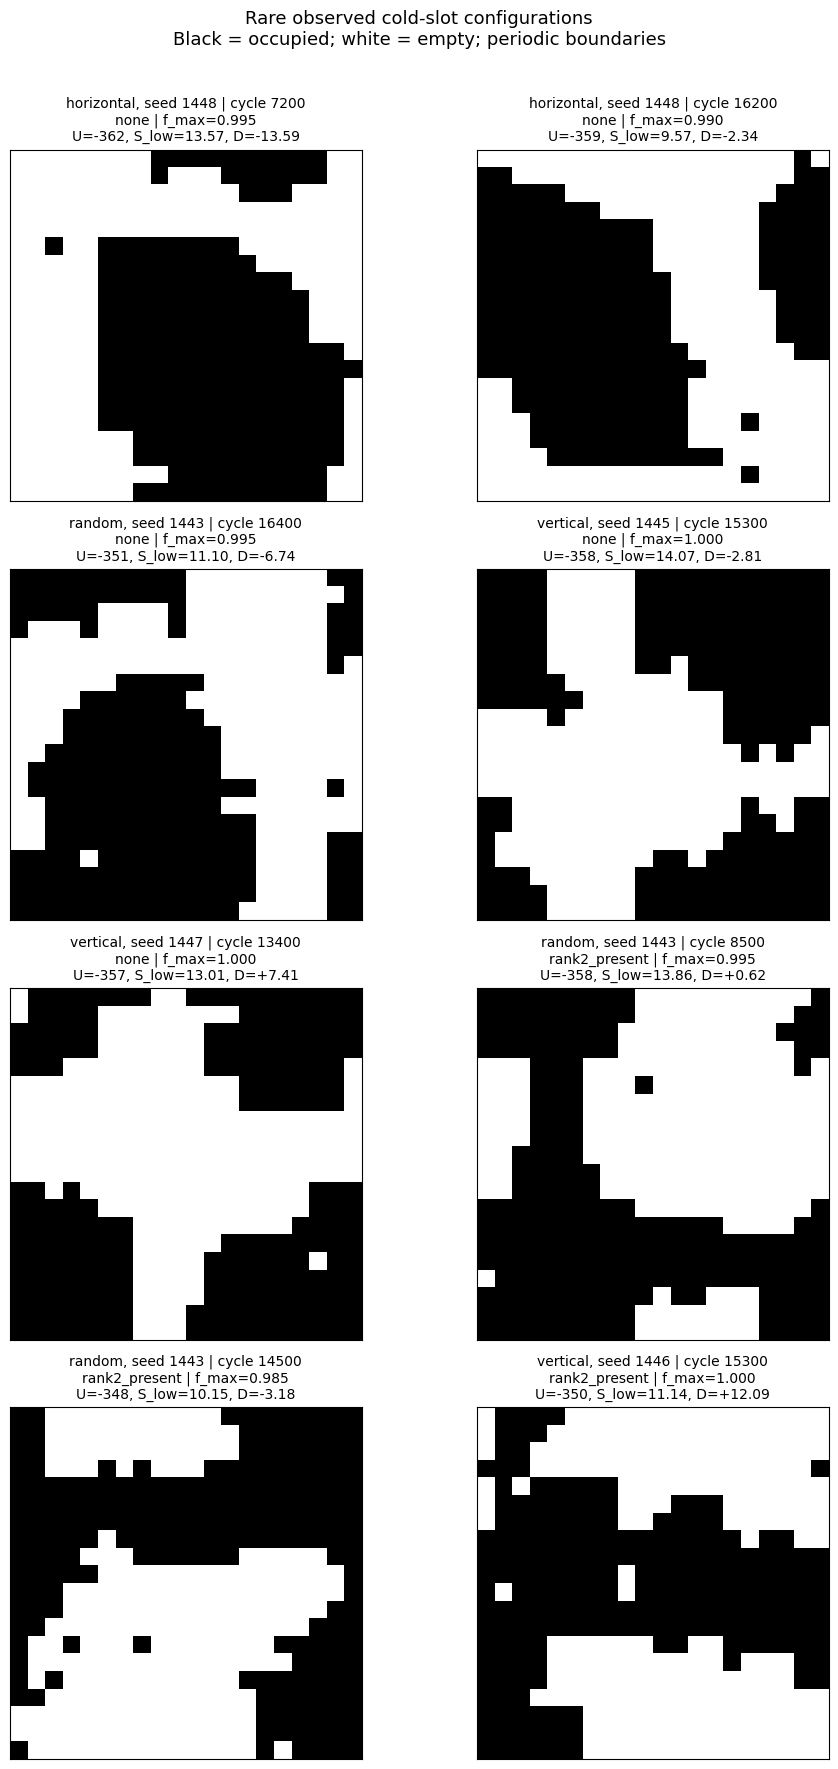

Inspected all 8 selected snapshots.
PASS: saved configurations match recorded observables and topology.
No new MC simulation; previous reference decisions unchanged.
Saved to: C:\Users\user\Documents\GitHub\active-matter-reproductions\lattice-gas\results\pt_reference_candidate_20x20_20261103_015925_101620\shape_diagnostic_20261103_213931_751835\rare_snapshot_inspection_20261103_213931_781969


In [71]:
import json
from pathlib import Path
from datetime import datetime

import numpy as np
import matplotlib.pyplot as plt

# Inspect every snapshot in the two rare observed categories.
rare_rows = [
    row for row in shape_snapshot_rows
    if row["wrapping_class"] in ("none", "rank2_present")
]
rare_rows.sort(key=lambda row: (
    row["wrapping_class"], row["initial"], row["seed"], row["cycle"]
))

if not rare_rows:
    raise ValueError("No snapshots in the selected categories.")

inspection_dir = pt_shape_dir / (
    "rare_snapshot_inspection_"
    + datetime.now().strftime("%Y%m%d_%H%M%S_%f")
)
inspection_dir.mkdir(parents=True, exist_ok=False)

states_to_save = []
inspection_rows = []

for row in rare_rows:
    cycle = int(row["cycle"])
    start = ((cycle - 1) // 5000) * 5000
    end = start + 5000

    source = pt_shape_source / (
        f"{row['initial']}_seed_{row['seed']}_"
        f"{start:06d}_{end:06d}.npz"
    )

    with np.load(source, allow_pickle=False) as data:
        snapshot_match = np.flatnonzero(
            data["cold_snapshot_cycles"] == cycle
        )
        record_match = np.flatnonzero(data["cycles"] == cycle)
        assert snapshot_match.size == record_match.size == 1

        state = data["cold_snapshots"][snapshot_match[0]].copy()
        index = int(record_match[0])
        recorded = {
            "U": float(data["target_U"][index]),
            "S_low": float(data["target_S_low"][index]),
            "D": float(data["target_D"][index]),
        }

    # Independently recompute observables for epsilon=1 and mu=0.
    a = state.astype(np.int64)
    assert a.shape == (20, 20)
    assert np.isin(a, [0, 1]).all() and a.sum() == 200

    direct_u = -float(np.sum(
        a * (np.roll(a, -1, axis=0) + np.roll(a, -1, axis=1))
    ))
    spectrum = np.abs(np.fft.fft2(a - a.mean()))**2 / a.size
    s0 = float((spectrum[1, 0] + spectrum[-1, 0]) / 2)
    s1 = float((spectrum[0, 1] + spectrum[0, -1]) / 2)

    assert np.allclose(
        [direct_u, (s0 + s1) / 2, s0 - s1],
        [recorded["U"], recorded["S_low"], recorded["D"]],
        rtol=0, atol=1e-10,
    )

    shape = periodic_cluster_observables(a)
    assert occupied_wrapping_class(
        shape["components"]
    ) == row["wrapping_class"]
    assert np.isclose(shape["f_max"], row["f_max"])

    states_to_save.append(state)
    inspection_rows.append({
        **row,
        **recorded,
        "source_file": str(source.resolve()),
    })

# Show original configurations without rotating or aligning them.
ncols = 2
nrows = (len(inspection_rows) + ncols - 1) // ncols
fig, axes = plt.subplots(
    nrows, ncols, figsize=(10, 4.5 * nrows), squeeze=False
)

for ax, state, row in zip(
    axes.flat, states_to_save, inspection_rows
):
    ax.imshow(
        state, cmap="binary", vmin=0, vmax=1,
        interpolation="nearest", origin="upper",
    )
    ax.set_title(
        f"{row['initial']}, seed {row['seed']} | cycle {row['cycle']}\n"
        f"{row['wrapping_class']} | f_max={row['f_max']:.3f}\n"
        f"U={row['U']:.0f}, S_low={row['S_low']:.2f}, "
        f"D={row['D']:+.2f}",
        fontsize=10,
    )
    ax.set_xticks([])
    ax.set_yticks([])

for ax in axes.flat[len(inspection_rows):]:
    ax.set_visible(False)

fig.suptitle(
    "Rare observed cold-slot configurations\n"
    "Black = occupied; white = empty; periodic boundaries",
    fontsize=13,
)
fig.tight_layout(rect=(0, 0, 1, 0.97))
fig.savefig(inspection_dir / "rare_snapshots.png", dpi=180)
plt.show()

np.savez_compressed(
    inspection_dir / "rare_snapshots.npz",
    states=np.stack(states_to_save),
    cycles=np.array([row["cycle"] for row in inspection_rows]),
    seeds=np.array([row["seed"] for row in inspection_rows]),
)
(inspection_dir / "inspection.json").write_text(
    json.dumps(inspection_rows, indent=2, allow_nan=False),
    encoding="utf-8",
)

print(f"Inspected all {len(inspection_rows)} selected snapshots.")
print("PASS: saved configurations match recorded observables and topology.")
print("No new MC simulation; previous reference decisions unchanged.")
print("Saved to:", inspection_dir.resolve())

In [72]:
import json
from datetime import datetime

import numpy as np

# Existing measurements only. No new Monte Carlo simulation.
source_dir = pt_shape_source
run_groups = {
    "random": [1442, 1443, 1444],
    "vertical": [1445, 1446, 1447],
    "horizontal": [1448, 1449, 1450],
}
block_cycles = [500, 1000, 2000]
measurement_cycles = 20000
previous_mcse_targets = {"U": 0.25, "S_low": 0.125, "abs_D": 0.5}

def batch_diagnostics(values, record_interval):
    x = np.asarray(values, dtype=float)
    estimates = []

    for length in block_cycles:
        assert length % record_interval == 0
        records_per_block = length // record_interval
        assert x.size % records_per_block == 0

        means = x.reshape(-1, records_per_block).mean(axis=1)
        assert means.size >= 2
        estimates.append(float(
            means.std(ddof=1) / np.sqrt(means.size)
        ))

    maximum = max(estimates)
    minimum = min(estimates)

    # Conservative descriptive choice across these block lengths.
    # This is not a proven upper bound on Monte Carlo error.
    variance = float(x.var(ddof=1))
    batch_ess = (
        variance / maximum**2
        if maximum > 0 and variance > 0 else None
    )
    sensitivity = maximum / minimum if minimum > 0 else None

    return {
        "mean": float(x.mean()),
        "mcse_by_block": estimates,
        "max_batch_mcse": maximum,
        "batch_ess_estimate": batch_ess,
        "block_sensitivity_ratio": sensitivity,
    }

budget_rows = []

for initial, seeds in run_groups.items():
    for seed in seeds:
        pieces = {name: [] for name in ("U", "S_low", "D")}
        recorded_cycles = []
        previous_endpoint = None

        for start in range(0, 25000, 5000):
            end = start + 5000
            path = source_dir / (
                f"{initial}_seed_{seed}_{start:06d}_{end:06d}.npz"
            )

            with np.load(path, allow_pickle=False) as data:
                cycles = data["cycles"].copy()
                arrays = {
                    "U": data["target_U"].copy(),
                    "S_low": data["target_S_low"].copy(),
                    "D": data["target_D"].copy(),
                }

            assert np.array_equal(cycles, np.arange(start, end + 1))
            if previous_endpoint is not None:
                for name in arrays:
                    assert np.isclose(
                        arrays[name][0], previous_endpoint[name],
                        rtol=0, atol=1e-10,
                    )
            previous_endpoint = {
                name: float(values[-1]) for name, values in arrays.items()
            }

            # Drop the duplicated segment-start record.
            keep = (cycles > start) & (cycles > 5000)
            recorded_cycles.append(cycles[keep])
            for name in pieces:
                pieces[name].append(arrays[name][keep])

        assert np.array_equal(
            np.concatenate(recorded_cycles), np.arange(5001, 25001)
        )
        traces = {
            name: np.concatenate(parts) for name, parts in pieces.items()
        }
        traces["abs_D"] = np.abs(traces.pop("D"))

        for observable, values in traces.items():
            result = batch_diagnostics(values, record_interval=1)
            target = previous_mcse_targets[observable]
            factor = max(1.0, (result["max_batch_mcse"] / target)**2)

            budget_rows.append({
                "initial": initial,
                "seed": seed,
                "observable": observable,
                **result,
                "previous_mcse_target": target,
                "conditional_length_factor": factor,
                "conditional_total_measurement_cycles": int(
                    1000 * np.ceil(measurement_cycles * factor / 1000)
                ),
            })

        snapshots_for_chain = sorted(
            (
                row for row in shape_snapshot_rows
                if row["initial"] == initial and row["seed"] == seed
                and 5000 < row["cycle"] <= 25000
            ),
            key=lambda row: row["cycle"],
        )
        assert np.array_equal(
            [row["cycle"] for row in snapshots_for_chain],
            np.arange(5100, 25001, 100),
        )

        shape_traces = {
            "f_max": np.array([
                row["f_max"] for row in snapshots_for_chain
            ])
        }
        for category in topology_names:
            shape_traces[f"P({category})"] = np.array([
                float(row["wrapping_class"] == category)
                for row in snapshots_for_chain
            ])

        for observable, values in shape_traces.items():
            result = batch_diagnostics(values, record_interval=100)
            is_indicator = observable.startswith("P(")
            constant = bool(np.all(values == values[0]))

            budget_rows.append({
                "initial": initial,
                "seed": seed,
                "observable": observable,
                **result,
                "observed_count": int(values.sum()) if is_indicator else None,
                "records": int(values.size),
                "constant_trace": constant,
                "interpretation": (
                    "Constant trace: zero empirical MCSE does not establish precision."
                    if constant else
                    "Diagnostic only; sparse events may give unstable error estimates."
                    if is_indicator else
                    "Diagnostic batch-means uncertainty."
                ),
            })

print("Existing mean targets: conditional budget estimates")
print("Initial seed | Observable | MCSE: B=500 / 1000 / 2000 | Factor")
for row in budget_rows:
    if "conditional_length_factor" not in row:
        continue
    sem_text = " / ".join(f"{v:.4f}" for v in row["mcse_by_block"])
    print(
        f"{row['initial']:10s} {row['seed']} | "
        f"{row['observable']:6s} | {sem_text} | "
        f"{row['conditional_length_factor']:.2f}"
    )

print("\nWorst-chain projection by observable:")
for observable in previous_mcse_targets:
    rows = [
        row for row in budget_rows if row["observable"] == observable
    ]
    worst = max(rows, key=lambda row: row["conditional_length_factor"])
    print(
        f"{observable:6s}: factor={worst['conditional_length_factor']:.2f}, "
        f"total measurement cycles≈"
        f"{worst['conditional_total_measurement_cycles']:,}"
    )

print("\nRare-category counts and diagnostic MCSE:")
for row in budget_rows:
    if row["observable"] not in (
        "P(none)", "P(both_projections_rank1)", "P(rank2_present)"
    ):
        continue
    note = "UNRESOLVED: constant trace" if row["constant_trace"] else "sparse"
    print(
        f"{row['initial']:10s} {row['seed']} | {row['observable']:26s} | "
        f"{row['observed_count']:3d}/{row['records']} | "
        f"max MCSE={row['max_batch_mcse']:.5f} | {note}"
    )

budget_dir = source_dir / (
    "precision_budget_" + datetime.now().strftime("%Y%m%d_%H%M%S_%f")
)
budget_dir.mkdir(parents=True, exist_ok=False)

report = {
    "status": "CONDITIONAL_PRECISION_BUDGET_DIAGNOSTIC",
    "source_directory": str(source_dir.resolve()),
    "measurement_window": [5001, 25000],
    "block_lengths_cycles": block_cycles,
    "rows": budget_rows,
    "limitations": [
        "Length projections assume stationarity and unchanged correlation times.",
        "Batch ESS estimates can be unreliable when blocks remain correlated.",
        "Constant or rare indicators do not establish precise category probabilities.",
        "No rank-normalized R-hat or joint-distribution assessment is performed here.",
        "No equilibrium qualification or automatic continuation.",
    ],
}
(budget_dir / "precision_budget.json").write_text(
    json.dumps(report, indent=2, allow_nan=False),
    encoding="utf-8",
)
print("\nSaved to:", budget_dir.resolve())

Existing mean targets: conditional budget estimates
Initial seed | Observable | MCSE: B=500 / 1000 / 2000 | Factor
random     1442 | U      | 0.2159 / 0.2251 / 0.2359 | 1.00
random     1442 | S_low  | 0.0942 / 0.0913 / 0.0981 | 1.00
random     1442 | abs_D  | 0.2808 / 0.2724 / 0.3061 | 1.00
random     1443 | U      | 0.1718 / 0.1373 / 0.1164 | 1.00
random     1443 | S_low  | 0.0793 / 0.0853 / 0.0913 | 1.00
random     1443 | abs_D  | 0.2582 / 0.2788 / 0.2573 | 1.00
random     1444 | U      | 0.2256 / 0.2724 / 0.3452 | 1.91
random     1444 | S_low  | 0.0905 / 0.0994 / 0.1259 | 1.01
random     1444 | abs_D  | 0.2862 / 0.3162 / 0.3388 | 1.00
vertical   1445 | U      | 0.1736 / 0.1379 / 0.0969 | 1.00
vertical   1445 | S_low  | 0.0697 / 0.0594 / 0.0365 | 1.00
vertical   1445 | abs_D  | 0.2303 / 0.2248 / 0.1712 | 1.00
vertical   1446 | U      | 0.1638 / 0.1518 / 0.1958 | 1.00
vertical   1446 | S_low  | 0.0922 / 0.0994 / 0.1067 | 1.00
vertical   1446 | abs_D  | 0.2700 / 0.2605 / 0.2560 | 1.00


In [73]:
for obs in ("U", "S_low", "abs_D"):
    rows = [r for r in budget_rows if r["observable"] == obs]
    worst = max(rows, key=lambda r: r["max_batch_mcse"])
    print(
        f"{obs}: worst={worst['initial']} {worst['seed']}, "
        f"max MCSE={worst['max_batch_mcse']:.5f}, "
        f"factor={worst['conditional_length_factor']:.2f}, "
        f"projected measurement cycles="
        f"{worst['conditional_total_measurement_cycles']}"
    )

print("\nf_max: MCSE for blocks 500 / 1000 / 2000")
for r in budget_rows:
    if r["observable"] == "f_max":
        errors = " / ".join(f"{x:.6f}" for x in r["mcse_by_block"])
        print(f"{r['initial']:10s} {r['seed']}: {errors}")

U: worst=random 1444, max MCSE=0.34519, factor=1.91, projected measurement cycles=39000
S_low: worst=random 1444, max MCSE=0.12586, factor=1.01, projected measurement cycles=21000
abs_D: worst=random 1444, max MCSE=0.33878, factor=1.00, projected measurement cycles=20000

f_max: MCSE for blocks 500 / 1000 / 2000
random     1442: 0.000639 / 0.000547 / 0.000588
random     1443: 0.000480 / 0.000326 / 0.000272
random     1444: 0.000568 / 0.000622 / 0.000554
vertical   1445: 0.000730 / 0.000837 / 0.000819
vertical   1446: 0.000659 / 0.000455 / 0.000427
vertical   1447: 0.000459 / 0.000550 / 0.000587
horizontal 1448: 0.000529 / 0.000657 / 0.000610
horizontal 1449: 0.000538 / 0.000634 / 0.000570
horizontal 1450: 0.000512 / 0.000451 / 0.000496


In [74]:
%pip install "arviz-stats==1.3.3"

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [75]:
import json
import warnings
from pathlib import Path
from datetime import datetime
from importlib.metadata import version

import numpy as np
from arviz_stats.base import array_stats as azs

source = Path("results") / (
    "pt_reference_candidate_20x20_20261103_015925_101620"
)
groups = {
    "random": [1442, 1443, 1444],
    "vertical": [1445, 1446, 1447],
    "horizontal": [1448, 1449, 1450],
}

chain_labels = []
source_files = []
collected = {name: [] for name in ("U", "S_low", "abs_D", "q")}

for initial, seeds in groups.items():
    for seed in seeds:
        parts = {name: [] for name in ("U", "S_low", "D")}
        cycle_parts = []
        previous_endpoint = None

        for start in range(0, 25000, 5000):
            end = start + 5000
            path = source / (
                f"{initial}_seed_{seed}_{start:06d}_{end:06d}.npz"
            )
            source_files.append(str(path.resolve()))

            with np.load(path, allow_pickle=False) as data:
                cycles = data["cycles"].copy()
                values = {
                    "U": data["target_U"].copy(),
                    "S_low": data["target_S_low"].copy(),
                    "D": data["target_D"].copy(),
                }

            assert np.array_equal(cycles, np.arange(start, end + 1))
            for name, x in values.items():
                assert x.shape == cycles.shape
                assert np.isfinite(x).all()
                if previous_endpoint is not None:
                    assert np.isclose(
                        x[0], previous_endpoint[name],
                        rtol=0, atol=1e-10,
                    )

            previous_endpoint = {
                name: float(x[-1]) for name, x in values.items()
            }

            # Keep cycles 5001–25000, without duplicate checkpoint records.
            keep = (cycles > start) & (cycles > 5000)
            cycle_parts.append(cycles[keep])
            for name in parts:
                parts[name].append(values[name][keep])

        assert np.array_equal(
            np.concatenate(cycle_parts), np.arange(5001, 25001)
        )
        traces = {
            name: np.concatenate(pieces)
            for name, pieces in parts.items()
        }
        d = traces["D"]

        collected["U"].append(traces["U"])
        collected["S_low"].append(traces["S_low"])
        collected["abs_D"].append(np.abs(d))
        collected["q"].append(
            (d > 0).astype(float) + 0.5 * (d == 0)
        )
        chain_labels.append(f"{initial}_{seed}")

# Preserve independent chains and chronological draw order.
diagnostic_arrays = {
    name: np.stack(chains) for name, chains in collected.items()
}
assert all(x.shape == (9, 20000) for x in diagnostic_arrays.values())

def finite_or_none(value):
    number = float(np.asarray(value).item())
    return number if np.isfinite(number) else None

diagnostic_rows = []

for name, x in diagnostic_arrays.items():
    constant_chains = [
        chain_labels[i]
        for i in range(x.shape[0])
        if np.all(x[i] == x[i, 0])
    ]

    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        metrics = {
            "rhat_rank": finite_or_none(
                azs.rhat(x, method="rank", chain_axis=0, draw_axis=1)
            ),
            "ess_bulk": finite_or_none(
                azs.ess(x, method="bulk", chain_axis=0, draw_axis=1)
            ),
            "ess_mean": finite_or_none(
                azs.ess(x, method="mean", chain_axis=0, draw_axis=1)
            ),
            "mcse_mean": finite_or_none(
                azs.mcse(x, method="mean", chain_axis=0, draw_axis=1)
            ),
        }

    diagnostic_rows.append({
        "observable": name,
        "pooled_mean": float(x.mean()),
        **metrics,
        "chain_means": x.mean(axis=1).tolist(),
        "constant_chains": constant_chains,
        "warnings": sorted(set(str(w.message) for w in caught)),
    })

def display_number(value, decimals):
    return "undefined" if value is None else f"{value:.{decimals}f}"

print("Nine independent runs; fixed T=0.4 slot; cycles 5001–25000")
print("Observable | Rank R-hat | Bulk ESS | Mean ESS | Pooled-mean MCSE")

for row in diagnostic_rows:
    print(
        f"{row['observable']:10s} | "
        f"{display_number(row['rhat_rank'], 5):>10s} | "
        f"{display_number(row['ess_bulk'], 1):>8s} | "
        f"{display_number(row['ess_mean'], 1):>8s} | "
        f"{display_number(row['mcse_mean'], 6)}"
    )
    if row["constant_chains"]:
        print("  Constant chains:", row["constant_chains"])
    for message in row["warnings"]:
        print("  Warning:", message)

print("\nUnrotated direction occupancy q, by independent run:")
for label, mean_q in zip(
    chain_labels, diagnostic_arrays["q"].mean(axis=1)
):
    print(f"{label:18s}: {mean_q:.5f}")

diagnostic_dir = source / (
    "multichain_diagnostic_"
    + datetime.now().strftime("%Y%m%d_%H%M%S_%f")
)
diagnostic_dir.mkdir(parents=True, exist_ok=False)

report = {
    "status": "EXPLORATORY_MULTICHAIN_DIAGNOSTIC",
    "arviz_stats_version": version("arviz-stats"),
    "numpy_version": np.__version__,
    "source_files": source_files,
    "chain_labels": chain_labels,
    "measurement_window": [5001, 25000],
    "draws_per_chain": 20000,
    "q_definition": "I(D > 0) + 0.5 I(D == 0); no rotation",
    "rows": diagnostic_rows,
    "limitations": [
        "MCSE refers to the pooled mean, not an individual-chain mean.",
        "Diagnostics do not bound common bias or exclude unvisited states.",
        "Discrete q can produce degenerate folded diagnostics.",
        "No shape-probability or joint-distribution qualification.",
        "Previous NOT READY decision remains unchanged.",
    ],
}
(diagnostic_dir / "multichain_diagnostic.json").write_text(
    json.dumps(report, indent=2, allow_nan=False),
    encoding="utf-8",
)
print("\nNo new MC simulation; no equilibrium PASS/FAIL.")
print("Saved to:", diagnostic_dir.resolve())

Nine independent runs; fixed T=0.4 slot; cycles 5001–25000
Observable | Rank R-hat | Bulk ESS | Mean ESS | Pooled-mean MCSE
U          |    1.00096 |   5003.5 |   5189.0 | 0.066193
S_low      |    1.00271 |   2460.6 |   2599.8 | 0.030027
abs_D      |    1.00333 |   2457.1 |   2743.5 | 0.091564
q          |    1.02537 |    384.4 |    384.4 | 0.025416

Unrotated direction occupancy q, by independent run:
random_1442       : 0.57815
random_1443       : 0.48795
random_1444       : 0.51130
vertical_1445     : 0.56135
vertical_1446     : 0.50375
vertical_1447     : 0.56130
horizontal_1448   : 0.63730
horizontal_1449   : 0.41355
horizontal_1450   : 0.61540

No new MC simulation; no equilibrium PASS/FAIL.
Saved to: C:\Users\user\Documents\GitHub\active-matter-reproductions\lattice-gas\results\pt_reference_candidate_20x20_20261103_015925_101620\multichain_diagnostic_20261103_213933_369787


In [76]:
import itertools
import json
import time
from pathlib import Path
from datetime import datetime

import numpy as np

assert callable(globals().get("replica_exchange_cycle")), (
    "Run the cell defining replica_exchange_cycle first."
)

# Freeze the protocol before generating trajectories.
config = {
    "task": "PT_ROTATION_4X4_JOINT_VALIDATION_V1",
    "L": 4,
    "N": 8,
    "epsilon": 1.0,
    "temperatures": [0.4, 0.5, 0.7, 1.0],
    "excluded_cycles": 500,
    "measurement_cycles": 5000,
    "methods": ["pt", "pt_rotation"],
    "seeds": {
        "random": [1642, 1643, 1644],
        "stripe": [1645, 1646, 1647],
    },
    "joint_observables": ["U", "S_low", "D"],
    "joint_tv_tolerance": 0.05,
    "joint_key_decimals": 10,
    "rotation": "Independent uniform k in {0,1,2,3} per slot after each PT cycle",
    "rng_streams": {"initialization": 0, "updates": 1, "rotation": 2},
    "stopping": "Fixed budget; no automatic extension or threshold changes",
}

out_dir = Path("results") / (
    "pt_rotation_validation_4x4_"
    + datetime.now().strftime("%Y%m%d_%H%M%S_%f")
)
out_dir.mkdir(parents=True, exist_ok=False)
(out_dir / "config.json").write_text(
    json.dumps(config, indent=2), encoding="utf-8"
)


# Independent measurements, supporting a batch of configurations.
def validation_observables(states):
    a = np.asarray(states, dtype=float)
    u = -(
        a * (
            np.roll(a, -1, axis=-2)
            + np.roll(a, -1, axis=-1)
        )
    ).sum(axis=(-2, -1))

    centered = a - a.mean(axis=(-2, -1), keepdims=True)
    spectrum = np.abs(
        np.fft.fft2(centered, axes=(-2, -1))
    ) ** 2 / 16

    s0 = (spectrum[..., 1, 0] + spectrum[..., -1, 0]) / 2
    s1 = (spectrum[..., 0, 1] + spectrum[..., 0, -1]) / 2
    return np.stack((u, (s0 + s1) / 2, s0 - s1), axis=-1)


# Enumerate every fixed-N configuration independently.
exact_states = np.zeros((12870, 16), dtype=np.uint8)
for index, occupied in enumerate(itertools.combinations(range(16), 8)):
    exact_states[index, list(occupied)] = 1
exact_states = exact_states.reshape(-1, 4, 4)

exact_obs = validation_observables(exact_states)
exact_u = exact_obs[:, 0]
weights = np.exp(-(exact_u - exact_u.min()) / 0.4)
weights /= weights.sum()

support, inverse = np.unique(
    np.round(exact_obs, config["joint_key_decimals"]),
    axis=0,
    return_inverse=True,
)
exact_pmf = np.bincount(
    inverse, weights=weights, minlength=len(support)
)
support_lookup = {
    tuple(values): index for index, values in enumerate(support)
}

np.savez_compressed(
    out_dir / "exact_joint_reference.npz",
    support=support,
    probability=exact_pmf,
    observable_names=np.array(config["joint_observables"]),
)
print(f"Exact states: {len(exact_states)}; joint support: {len(support)}")
print("Exact means [U, S_low, D]:", weights @ exact_obs)

temperatures = np.array(config["temperatures"], dtype=float)
frozen_temperatures = temperatures.copy()
burn = config["excluded_cycles"]
draws = config["measurement_cycles"]
total_cycles = burn + draws
rows = []
started = time.perf_counter()

for initial, seeds in config["seeds"].items():
    for seed in seeds:
        init_rng = np.random.default_rng(
            np.random.SeedSequence([seed, 0])
        )
        initial_states = []
        for slot in range(len(temperatures)):
            state = np.zeros((4, 4), dtype=np.uint8)
            if initial == "random":
                state.flat[init_rng.choice(16, 8, replace=False)] = 1
            else:
                state[:, :2] = 1
            initial_states.append(state)

        # Both methods start from identical configurations.
        for method in config["methods"]:
            states = [state.copy() for state in initial_states]
            energies = validation_observables(states)[:, 0].copy()
            replica_ids = np.arange(len(temperatures))
            run_rng = np.random.default_rng(
                np.random.SeedSequence([seed, 1])
            )
            rotation_rng = np.random.default_rng(
                np.random.SeedSequence([seed, 2])
            )

            cold_states = np.empty((draws, 4, 4), dtype=np.uint8)
            cold_energies = np.empty(draws)
            swap_accepts = np.zeros(len(temperatures) - 1, dtype=int)
            rotation_calls = 0
            run_started = time.perf_counter()

            for cycle in range(1, total_cycles + 1):
                swap_accepts += replica_exchange_cycle(
                    states,
                    energies,
                    replica_ids,
                    temperatures,
                    run_rng,
                )

                if method == "pt_rotation":
                    for slot in range(len(temperatures)):
                        k = int(rotation_rng.integers(4))
                        states[slot] = np.rot90(states[slot], k).copy()
                        rotation_calls += 1

                if cycle % 100 == 0 or cycle == total_cycles:
                    stacked = np.stack(states)
                    assert np.isin(stacked, [0, 1]).all()
                    assert np.all(stacked.sum(axis=(1, 2)) == 8)
                    assert np.array_equal(
                        temperatures, frozen_temperatures
                    )
                    assert np.array_equal(
                        np.sort(replica_ids), np.arange(4)
                    )
                    assert np.allclose(
                        energies,
                        validation_observables(stacked)[:, 0],
                        rtol=0,
                        atol=1e-12,
                    )
                    for a in range(4):
                        for b in range(a + 1, 4):
                            assert not np.shares_memory(states[a], states[b])

                if cycle > burn:
                    index = cycle - burn - 1
                    cold_states[index] = states[0]
                    cold_energies[index] = energies[0]

            observed = validation_observables(cold_states)
            assert np.allclose(
                observed[:, 0], cold_energies, rtol=0, atol=1e-12
            )

            keys = np.round(observed, config["joint_key_decimals"])
            assert all(tuple(key) in support_lookup for key in keys)
            indices = np.array([
                support_lookup[tuple(key)] for key in keys
            ])
            empirical_pmf = np.bincount(
                indices, minlength=len(support)
            ) / draws
            joint_tv = float(
                0.5 * np.abs(empirical_pmf - exact_pmf).sum()
            )

            elapsed = time.perf_counter() - run_started
            row = {
                "method": method,
                "initial": initial,
                "seed": seed,
                "joint_tv": joint_tv,
                "within_tolerance": joint_tv <= config["joint_tv_tolerance"],
                "observable_means": observed.mean(axis=0).tolist(),
                "within_slot_proposals": total_cycles * 4 * 16,
                "exchange_attempts": total_cycles * 3,
                "rotation_calls": rotation_calls,
                "elapsed_seconds": elapsed,
            }
            rows.append(row)

            np.savez_compressed(
                out_dir / f"{method}_{initial}_{seed}.npz",
                cold_states=cold_states,
                observables=observed,
                empirical_joint_pmf=empirical_pmf,
                initial_states=np.stack(initial_states),
                final_states=np.stack(states),
                final_energies=energies,
                final_replica_ids=replica_ids,
                swap_accepts=swap_accepts,
                update_rng_end_json=json.dumps(run_rng.bit_generator.state),
                rotation_rng_end_json=json.dumps(
                    rotation_rng.bit_generator.state
                ),
            )
            # Preserve completed runs even if a later run fails.
            (out_dir / "run_results.json").write_text(
                json.dumps(rows, indent=2, allow_nan=False),
                encoding="utf-8",
            )
            print(
                f"{method:11s} | {initial:6s} | seed={seed} | "
                f"joint TV={joint_tv:.5f} | "
                f"within tolerance={row['within_tolerance']}",
                flush=True,
            )

method_screens = {
    method: all(
        row["within_tolerance"]
        for row in rows if row["method"] == method
    )
    for method in config["methods"]
}
report = {
    "config": config,
    "runs": rows,
    "method_screens": method_screens,
    "total_seconds": time.perf_counter() - started,
    "scope": (
        "Fixed-budget 4x4 joint-distribution accuracy screen. "
        "No efficiency superiority or 20x20 reference qualification."
    ),
}
(out_dir / "assessment.json").write_text(
    json.dumps(report, indent=2, allow_nan=False), encoding="utf-8"
)

print("\nFixed-budget joint screens:", method_screens)
print("20x20 reference status remains unchanged.")
print("Saved to:", out_dir.resolve())

Exact states: 12870; joint support: 91
Exact means [U, S_low, D]: [-1.10287399e+01  8.24451544e-01  1.36338753e-15]
pt          | random | seed=1642 | joint TV=0.05183 | within tolerance=False
pt_rotation | random | seed=1642 | joint TV=0.02417 | within tolerance=True
pt          | random | seed=1643 | joint TV=0.06937 | within tolerance=False
pt_rotation | random | seed=1643 | joint TV=0.02688 | within tolerance=True
pt          | random | seed=1644 | joint TV=0.04873 | within tolerance=True
pt_rotation | random | seed=1644 | joint TV=0.03011 | within tolerance=True
pt          | stripe | seed=1645 | joint TV=0.04683 | within tolerance=True
pt_rotation | stripe | seed=1645 | joint TV=0.02946 | within tolerance=True
pt          | stripe | seed=1646 | joint TV=0.03758 | within tolerance=True
pt_rotation | stripe | seed=1646 | joint TV=0.03252 | within tolerance=True
pt          | stripe | seed=1647 | joint TV=0.02803 | within tolerance=True
pt_rotation | stripe | seed=1647 | joint TV=0.

In [77]:
import inspect

function = globals().get("replica_exchange_cycle")
assert callable(function), (
    "Run the cell defining replica_exchange_cycle first."
)

seen = set()

def show_function_and_dependencies(function):
    if function.__name__ in seen:
        return
    seen.add(function.__name__)

    print(f"\n# ===== {function.__name__} =====")
    print(inspect.getsource(function))

    for name in function.__code__.co_names:
        dependency = function.__globals__.get(name)
        if (
            inspect.isfunction(dependency)
            and dependency.__module__ == function.__module__
        ):
            show_function_and_dependencies(dependency)

show_function_and_dependencies(function)


# ===== replica_exchange_cycle =====
def replica_exchange_cycle(
    states, energies, replica_ids, temperatures, rng, epsilon=1.0
):
    """One within-slot sweep followed by even/odd adjacent exchanges."""
    n_slots = len(temperatures)

    # Update each configuration at its current slot temperature.
    for slot, temperature in enumerate(temperatures):
        _, delta_u = nonlocal_sweep(
            states[slot],
            temperature=float(temperature),
            rng=rng,
            epsilon=epsilon,
        )
        energies[slot] += delta_u

    # Each adjacent edge is attempted once per cycle.
    accepted_edges = np.zeros(n_slots - 1, dtype=bool)

    for parity in (0, 1):
        for a in range(parity, n_slots - 1, 2):
            accepted_edges[a] = attempt_replica_exchange(
                states, energies, replica_ids, temperatures,
                a, a + 1, rng,
            )

    return accepted_edges


# ===== nonlocal_sweep =====
def nonlocal_sweep(n, temperatur

In [78]:
import io
import contextlib
from pathlib import Path

buffer = io.StringIO()
seen.clear()

with contextlib.redirect_stdout(buffer):
    show_function_and_dependencies(replica_exchange_cycle)

    for name in (
        "periodic_cluster_observables",
        "occupied_wrapping_class",
    ):
        function = globals().get(name)
        if inspect.isfunction(function):
            show_function_and_dependencies(function)

export_path = Path("pt_rotation_dependencies.py")
export_path.write_text(
    "import numpy as np\n\n" + buffer.getvalue(),
    encoding="utf-8",
)

print("Source exported to:", export_path.resolve())

Source exported to: C:\Users\user\Documents\GitHub\active-matter-reproductions\lattice-gas\pt_rotation_dependencies.py
